# Predictive Analytics of Indian Stock Prices Using Linear Regression
## End-to-end case study: Reliance Industries (RELIANCE.NS)
**Objective:** Predict the next trading session's adjusted closing price using information available after today's close; evaluate predictive usefulness and diagnose statistical assumptions without claiming they necessarily hold.

**Data:** Yahoo Finance daily OHLCV, retrieved through `yfinance`, requested January 1, 2015–October 12, 2026 (end date exclusive: October 13). A data snapshot is embedded below for offline reproducibility. Prices are adjusted INR values, not necessarily historical quoted/tradable prices. This is educational research, not an investment recommendation.

**Research questions:** Does OLS outperform a no-change forecast? Are coefficients stable and interpretable? Do collinearity, changing variance, nonnormal errors, serial dependence, or nonlinear structure undermine inference?

**Workflow:** Audit → exploratory analysis → causal feature construction → chronological train/validation/test split → OLS candidates → validation-only selection → locked holdout evaluation → assumption diagnostics → HAC inference → interpretation and limitations.

In [1]:
# Run only if dependencies are missing (uncomment):
# %pip install numpy pandas matplotlib seaborn scipy scikit-learn statsmodels yfinance
import io, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan, acorr_ljungbox, linear_reset, acorr_breusch_godfrey
from statsmodels.stats.stattools import jarque_bera, durbin_watson
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf
from IPython.display import display, Markdown
sns.set_theme(style='whitegrid')
SEED = 42
ALPHA = 0.05
# Disable sandbox-specific rich-table MIME output for portable Jupyter files.
ip = get_ipython()
for mime in list(ip.display_formatter.formatters):
    if mime.startswith("e2b/"):
        ip.display_formatter.formatters[mime].enabled = False

from IPython.display import display as _display, HTML
def display(*objects):
    for obj in objects:
        if isinstance(obj, (pd.DataFrame, pd.Series)):
            table = obj.to_frame() if isinstance(obj, pd.Series) else obj
            _display(HTML(table.to_html()))
        else:
            _display(obj)


## 1. Reproducible data source
The default uses the embedded original download. To refresh, set `REFRESH=True`; internet access is required. To analyze another Indian stock, change `TICKER` and set `REFRESH=True`. The notebook explicitly requests adjusted OHLC values. Yahoo Finance is a third-party source, not an exchange-certified feed; cross-check corporate actions and suspicious values before production use.

Sources:
- Yahoo Finance historical data: https://finance.yahoo.com/quote/RELIANCE.NS/history/
- Download API documentation: https://ranaroussi.github.io/yfinance/reference/api/yfinance.download.html
- Statistical diagnostics: https://www.statsmodels.org/stable/diagnostic.html

In [2]:
TICKER = "RELIANCE.NS"
START = "2015-01-01"
END = "2026-10-13"
REFRESH = False
SNAPSHOT_CSV = 'Date,Close,High,Low,Open,Volume\n2015-01-01,189.12538146972656,189.99869740526844,188.22011599157378,188.78458634854346,2963643\n2015-01-02,188.62481689453125,190.86135588187943,188.3585707167246,189.16797331601128,7331366\n2015-01-05,186.55868530273438,189.7643887395962,186.18592644379618,188.5076641535704,10103941\n2015-01-06,178.0918426513672,185.95165834174796,177.2185266371568,185.3126532132128,18627980\n2015-01-07,181.9684600830078,182.92697466832107,178.28351380572232,178.30481349789582,20720312\n2015-01-08,179.35922241210938,183.8003373309876,178.95451393891003,183.20391736061134,19872227\n2015-01-09,183.2464599609375,183.60856892670137,179.98752192531978,180.71172563809517,13392787\n2015-01-12,181.116455078125,183.3955933743806,179.26333908900085,183.28909490697473,10100113\n2015-01-13,179.59349060058594,182.10692561278077,179.0290344848976,181.69156735665987,9948711\n2015-01-14,177.84686279296875,180.4135468931564,177.04809586798652,179.56153073567586,11380041\n2015-01-15,184.0878448486328,185.54691648630015,178.92252706998613,178.92252706998613,16927085\n2015-01-16,185.24871826171875,186.3776304213054,181.48920872023663,183.18257695961665,19136963\n2015-01-19,187.36810302734375,188.72066202305834,182.9163390480819,185.35522508539012,13339962\n2015-01-20,192.35238647460938,192.884893074836,187.19770381565894,187.76217417752903,13361320\n2015-01-21,193.14047241210938,194.13093659194718,190.00933217222018,192.76772777789918,17084297\n2015-01-22,188.2414093017578,193.236329437438,187.3361439226893,192.79967151746072,23721627\n2015-01-23,188.912353515625,191.2340767726755,186.80362717435793,189.57265817330642,18080494\n2015-01-27,189.37033081054688,190.9998000421227,187.54915011606235,190.19038324040642,17939876\n2015-01-28,193.1617889404297,193.7901583875143,188.74197420937347,188.74197420937347,19298126\n2015-01-29,197.96499633789062,199.05130914446687,193.17242311034371,193.215022497366,36117653\n2015-01-30,194.95098876953125,198.3590389894597,193.61971537551548,198.09277862315537,21746801\n2015-02-02,193.41737365722656,195.9414582996459,192.91681666722144,195.12139170498207,19302710\n2015-02-03,199.71160888671875,200.40386307805295,194.5143277632121,194.5143277632121,17092333\n2015-02-04,197.83718872070312,201.03222790718357,197.21948341965077,200.0311139225026,14072894\n2015-02-05,196.7508544921875,200.20148961197413,195.45153073566158,199.37078747665592,12365643\n2015-02-06,193.8114471435547,198.09279939514687,192.3417255986973,196.83608900941982,9045844\n2015-02-09,190.99978637695312,195.5367487994649,189.9986724027075,191.95830096665662,8839692\n2015-02-10,187.86865234375,192.66121122767632,183.45948793303515,191.27670274801648,13651008\n2015-02-11,191.851806640625,192.71447263370337,188.08164727735914,188.72065227801738,9781008\n2015-02-12,193.6516876220703,194.6741013860684,188.98692660117334,193.40674113759897,8709626\n2015-02-13,195.43028259277344,196.13318677248154,193.63040142379697,194.6847648027369,7393680\n2015-02-16,192.2991180419922,196.85738034119814,191.70269819676588,195.6858545626321,12266698\n2015-02-18,192.05418395996094,193.40675731754536,190.5099133376229,191.70272475582357,9835036\n2015-02-19,192.1393280029297,193.32150345503706,189.05078763819276,193.18304125118556,9550637\n2015-02-20,185.97293090820312,190.85070299548755,185.58952219951283,190.6909410725933,18717199\n2015-02-23,181.36143493652344,186.75041436301234,180.43486973467347,185.30199239697455,14104463\n2015-02-24,179.2313690185547,182.5009713840568,178.28351847326613,181.95781500065965,19946218\n2015-02-25,179.59349060058594,182.437085092006,179.14618280312914,180.7969659805008,15274116\n2015-02-26,179.34852600097656,181.0525440230303,178.19829997280607,180.22182759469933,21459750\n2015-02-27,182.23472595214844,183.3956019574645,179.90235253178665,180.5307077376429,18659378\n2015-03-02,184.0878448486328,186.48413142281302,182.23471466876626,185.09960871120293,14579511\n2015-03-03,191.8730926513672,193.0765536423123,184.75879672424819,185.09959178362945,20636925\n2015-03-04,189.1147003173828,193.75817526240309,187.45328172037026,192.98070808339077,14476047\n2015-03-05,188.49700927734375,191.43645224546293,187.04858748644065,190.10517876692057,10716702\n2015-03-09,185.23805236816406,189.94542663337924,184.0665408344018,188.52895441528287,14065391\n2015-03-10,183.0015106201172,186.54800864690574,182.20274378272023,185.08893718017865,15234060\n2015-03-11,182.3199462890625,185.22742579614135,181.56377866713999,183.38495949335052,11635873\n2015-03-12,183.99200439453125,184.7588218197999,182.24537260294952,182.75659369896488,11782380\n2015-03-13,181.0738525390625,185.22740644561915,180.41354783388658,185.0996082869568,12936157\n2015-03-16,179.36984252929688,181.89392737056428,178.98643381725202,181.37207064705345,13839990\n2015-03-17,182.51162719726562,183.16128206555757,179.13552625773318,181.16970385507284,19070082\n2015-03-18,185.02505493164062,185.79187230276494,182.0536625013523,182.5435696499169,9269885\n2015-03-19,182.362548828125,186.7397500451926,181.9258908474523,186.49480354460488,13934612\n2015-03-20,181.92587280273438,183.42754385713542,180.75434699898798,182.73527537793208,10405717\n2015-03-23,179.337890625,184.03460107470758,178.51782397653736,182.43708138411853,13251683\n2015-03-24,180.61590576171875,181.96847901169176,179.36984520244596,179.36984520244596,9238431\n2015-03-25,179.96627807617188,180.946092603735,179.13556143187716,180.83959411568614,10264941\n2015-03-26,176.6433868408203,180.8928035475393,175.53577437136974,179.15682169938287,20621346\n2015-03-27,172.89456176757812,177.85753299187633,170.71127189154245,177.62322212331762,23326922\n2015-03-30,172.6921844482422,174.17255580025198,169.64624297036656,173.938259172148,17330588\n2015-03-31,175.94049072265625,177.4102122570868,174.23645833672006,174.23645833672006,20235395\n2015-04-01,178.08116149902344,178.70951666860736,173.19273971095927,175.7061746080489,14588531\n2015-04-06,175.6529083251953,178.49650241037702,174.96065414305951,178.07049436800403,12334096\n2015-04-07,177.3995819091797,178.0918362553346,175.951159909431,175.951159909431,21275454\n2015-04-08,184.43930053710938,185.2061036951791,177.4102028641615,177.5380010207142,24821205\n2015-04-09,190.6589813232422,191.48969777779942,182.92697957554887,184.3541016457162,27276420\n2015-04-10,192.6292724609375,193.57713728800425,189.38098379093722,190.62704433606712,25323219\n2015-04-13,196.4952850341797,196.97454238182422,191.4364653750179,193.15113344797666,20177342\n2015-04-15,196.740234375,200.1376207827185,193.23633528159354,196.17576406274188,22231264\n2015-04-16,197.74136352539062,199.79684096944027,195.74978516638853,196.92129682977034,20177302\n2015-04-17,197.4218292236328,201.13872507094774,196.51656386101575,199.16844665304706,23958678\n2015-04-20,188.64608764648438,199.67964037461152,187.12311708682262,199.64769083817646,37628162\n2015-04-21,186.68650817871094,190.74422833923563,185.83450609817635,189.6046519178387,17707007\n2015-04-22,187.389404296875,188.8804255337765,184.67360799818601,187.84736193682545,14761313\n2015-04-23,186.8142852783203,189.44486839829514,185.11025300171463,188.2627070259338,13337818\n2015-04-24,187.20831298828125,188.39048847456047,185.02503782359088,186.80361886629143,12709854\n2015-04-27,186.44151306152344,189.04014645624184,185.621446520848,187.4532768211219,11042925\n2015-04-28,184.2902374267578,187.8686860160505,182.87376493503115,186.31376549529412,14687371\n2015-04-29,181.05255126953125,185.42976613438847,180.49874503472927,183.60858551429183,16387960\n2015-04-30,183.6831512451172,184.4393188506432,180.61590987077562,181.05256783444128,34802149\n2015-05-04,189.77503967285156,190.4033948600845,183.28909805271562,184.50320903948798,15078502\n2015-05-05,190.03065490722656,192.08613244297527,188.52898368535145,190.36081441345635,17846755\n2015-05-06,187.49591064453125,191.01045983497983,185.7386289399295,189.57268777269337,22438208\n2015-05-07,185.47238159179688,187.11250074539757,183.1825933101832,186.37764705705703,16735535\n2015-05-08,191.89645385742188,192.76998886852428,185.7278174387588,187.8631124455421,17104443\n2015-05-11,193.24449157714844,193.99938785476854,190.53761444961006,192.57585311645389,14214007\n2015-05-12,187.36700439453125,193.01799224612841,186.6013241708603,193.01799224612841,16650201\n2015-05-13,190.90426635742188,191.66996098197123,184.88660721019056,188.3699483150161,16701434\n2015-05-14,189.41604614257812,191.14154802413535,187.712126712545,191.09839751898676,12329713\n2015-05-15,188.49935913085938,191.30329225237853,187.66897473862284,190.21407684063172,8331715\n2015-05-18,192.29547119140625,192.82390291273086,188.12193755585287,188.7042894122208,9847540\n2015-05-19,193.15821838378906,195.14253690631463,191.22781999525608,192.23076328331737,14513036\n2015-05-20,196.02684020996094,196.490567757141,193.6219302602409,194.20429649932248,8708891\n2015-05-21,193.4170379638672,197.43959520399088,192.84547013696726,196.54449217032317,10759523\n2015-05-22,194.94839477539062,195.3258500817103,193.47094002587502,193.47094002587502,8349048\n2015-05-25,192.9317169189453,195.84349020230397,192.46798942280014,194.1179885242109,6617337\n2015-05-26,190.79641723632812,193.25524698420838,190.3866098786985,193.0395520811887,9510249\n2015-05-27,190.94737243652344,192.15522632509257,189.84737318646467,191.0983487733836,8078236\n2015-05-28,188.8983917236328,192.87781265868432,188.0787769193217,191.0660386272173,26538868\n2015-05-29,189.15724182128906,191.19548061317758,188.31605887933804,189.7827298150447,29277517\n2015-06-01,194.60330200195312,195.17488420406747,189.372905153844,189.8042806131137,19594976\n2015-06-02,193.8268280029297,198.17290566214237,192.27388506594002,195.3582028879292,20178960\n2015-06-03,193.33074951171875,196.37193124706977,191.63761422713773,193.90231729061682,15546279\n2015-06-04,196.8572540283203,197.61215035452682,192.51116134568232,195.02391175368928,15931395\n2015-06-05,195.7895965576172,197.77391511708967,195.07782197986302,196.2533241164874,13066337\n2015-06-08,190.97976684570312,196.27488221056336,190.47290320455636,195.58467572183218,10846953\n2015-06-09,190.60232543945312,192.10133390831174,189.23271088979416,190.56995896227934,9153355\n2015-06-10,195.3689727783203,196.25329164173195,190.8826887078706,191.09836921216734,13509379\n2015-06-11,189.18955993652344,196.1670260564273,188.4346493502279,195.4121154701317,14676438\n2015-06-12,191.92877197265625,192.5434758206847,189.42680608088114,189.58858086039226,21543824\n2015-06-15,194.49545288085938,195.1964433694674,191.96113477120412,193.0179981192392,12858570\n2015-06-16,194.96995544433594,195.19643437871102,192.65133236024005,193.9023081194335,13929305\n2015-06-17,200.84742736816406,203.2523371171076,192.82388178639968,195.20722348368895,26232634\n2015-06-18,211.1464385986328,211.8042785053372,201.1277916622991,201.13857568703364,49366799\n2015-06-19,214.96412658691406,217.06706927613607,211.91216080142698,211.91216080142698,45710935\n2015-06-22,213.89649963378906,217.56316965747888,212.77491761422857,215.0288512826212,19394187\n2015-06-23,214.60824584960938,216.26902911960536,213.7454949362534,214.10138220764512,16007498\n2015-06-24,213.72393798828125,217.07787117984907,212.80726689494824,214.60825700052484,18603004\n2015-06-25,216.66806030273438,217.6278674888944,212.4513906180649,212.88276609028398,27175118\n2015-06-26,215.83766174316406,218.72785274188087,214.6945117771632,215.66510292680425,20966796\n2015-06-29,213.713134765625,214.36020512509336,209.6474417573692,213.07686283011645,20168946\n2015-06-30,215.70823669433594,216.30137252426832,213.09843040389427,213.508237791198,23184864\n2015-07-01,216.9053192138672,217.94061456857037,215.90237593912974,215.90237593912974,14824266\n2015-07-02,218.02688598632812,219.94650031555713,217.21805519433633,217.62786260364018,15931202\n2015-07-03,217.23960876464844,218.6631433767422,216.34450581940408,217.78960848329174,13831096\n2015-07-06,219.04061889648438,219.76316309616325,214.65139037025082,214.84551725221064,12237733\n2015-07-07,216.38766479492188,219.2670718116633,215.68667428837102,218.0592320681065,11294999\n2015-07-08,214.95330810546875,217.56311400291722,213.88566089278058,214.79153334137607,15190654\n2015-07-09,212.96902465820312,215.90236616300606,212.05235363821487,214.82392035261478,16245867\n2015-07-10,216.0749053955078,216.5494169333633,213.58372342124125,213.7670518616792,16110573\n2015-07-13,217.19647216796875,218.38275820763624,214.64058604670007,216.0749046814345,9860248\n2015-07-14,215.212158203125,218.16706773981207,214.6513744484258,217.60628398511287,9942927\n2015-07-15,218.09156799316406,218.7925440498951,215.5896020829163,215.63273818499832,13532911\n2015-07-16,220.79843139648438,221.68275028899987,218.09156898898715,218.2748974236729,14854295\n2015-07-17,220.36705017089844,222.40528854148198,219.56901790186066,221.13274476197677,10195142\n2015-07-20,221.02490234375,222.14646975826778,219.54744770039386,221.68274227762913,6348354\n2015-07-21,217.3690185546875,221.8229508615277,216.27980313588535,221.72589462779453,7923338\n2015-07-22,226.55728149414062,227.32296173340805,216.67882577991844,216.76509798739664,17309440\n2015-07-23,225.457275390625,230.32100052456877,224.57295649430867,227.22589878535965,18642915\n2015-07-24,221.0896453857422,226.39553068662536,220.23767845085933,226.0396577930844,13099664\n2015-07-27,216.84060668945312,222.13572230140866,216.06414235077094,221.05729081007794,20118553\n2015-07-28,217.8974609375,219.28862905994157,215.70823171305562,217.47686953387185,13382878\n2015-07-29,214.82391357421875,218.42589338351584,213.9827451618395,217.7356869348118,14790821\n2015-07-30,215.71902465820312,217.41217436851056,214.02588934579455,215.7082406319693,11701228\n2015-07-31,216.085693359375,217.3906037117329,213.52980718308112,215.68666999560452,16634259\n2015-08-03,216.21511840820312,218.67394853987463,215.5572783670028,215.9023816269619,9887787\n2015-08-04,213.09841918945312,216.90529536335586,211.37293192064573,216.41999981933222,12006872\n2015-08-05,213.04452514648438,215.85924252602445,212.25726239502848,213.15236541438256,14345010\n2015-08-06,211.1464385986328,213.9611554417314,210.83370188133085,213.74546054914356,8708037\n2015-08-07,212.3111572265625,214.3925315993971,210.7582000676196,211.15722338212865,8608888\n2015-08-10,208.97882080078125,213.27097841911095,208.02979769771665,212.34353776638306,9288894\n2015-08-11,208.3533172607422,210.00331634222698,206.62781560348682,209.43174859757792,8762464\n2015-08-12,203.37095642089844,208.35332021000772,202.86409282153707,207.8356725850833,9650325\n2015-08-13,201.31117248535156,205.75432109586058,200.45920557468926,204.25529818107353,9340350\n2015-08-14,208.55825805664062,209.6474736503162,201.51608639680467,202.79942888701206,12739366\n2015-08-17,205.0532989501953,208.35331141853055,204.05035581935485,208.35331141853055,10857430\n2015-08-18,203.62977600097656,206.1964461118649,203.21998302361058,206.1964461118649,6630334\n2015-08-19,205.8944854736328,207.274869508524,202.62682502080204,203.60820011939205,8877298\n2015-08-20,197.63368225097656,207.04841013731846,197.08368254879417,207.04841013731846,19008087\n2015-08-21,195.8327178955078,196.68468475999595,193.4709441712895,196.27487736703083,20050521\n2015-08-24,178.92288208007812,189.80428166737124,176.43169994733043,189.80428166737124,35635706\n2015-08-25,182.93463134765625,185.63072403270024,177.55325879855377,181.36012047613085,49504268\n2015-08-26,184.06700134277344,188.68269380966993,181.17679613903437,182.85914730045522,18955515\n2015-08-27,187.4640655517578,190.0738718328802,184.85425927063545,186.9572019319312,26997546\n2015-08-28,188.16505432128906,190.4513254037068,186.80622386417951,188.7258380659934,10770215\n2015-08-31,184.6062469482422,188.26213294854446,184.15330340866046,188.26213294854446,20708942\n2015-09-01,181.14447021484375,184.1748681867301,180.11995885489355,184.1748681867301,21645696\n2015-09-02,183.23663330078125,184.8650646079722,181.7376103204902,183.3336895459562,19652369\n2015-09-03,184.16407775878906,185.6523166255282,182.12583913672233,184.207213865254,11659978\n2015-09-04,180.29248046875,183.26895792897503,177.96305894399623,183.26895792897503,16199949\n2015-09-07,179.71011352539062,182.03953485361757,178.52384201079278,180.79932881754087,10234633\n2015-09-08,183.0316925048828,183.96993151753745,177.96305654976982,180.314046094147,12900468\n2015-09-09,188.5209197998047,189.52386296507026,183.44149982060765,185.7062171605128,17340694\n2015-09-10,187.00035095214844,187.7552616199805,184.51995281168513,185.7062389471499,11074406\n2015-09-11,185.69546508789062,188.96311175743168,184.6709536953797,188.07879272026005,10634833\n2015-09-14,186.32090759277344,186.71993090462797,183.74345369961657,185.8679641574111,7964072\n2015-09-15,187.00035095214844,187.6474213525472,184.5415208651718,185.92191948201648,11509788\n2015-09-16,188.1974334716797,189.23272890281734,186.6121382426189,188.10037722461686,13424811\n2015-09-18,193.1258544921875,194.01015903348315,189.18956976826752,189.46995444788118,34261453\n2015-09-21,189.39443969726562,191.57287026335263,188.95228028969314,189.8042470309594,12732187\n2015-09-22,182.88072204589844,190.86113152566716,182.147393891634,189.80426819863706,15745524\n2015-09-23,183.4091796875,184.8003624101719,181.17682843313136,181.8238844724135,15221260\n2015-09-24,180.60520935058594,182.9022641174557,180.0444256892399,182.9022641174557,29076982\n2015-09-28,179.93661499023438,181.3709337657103,178.73955920513254,181.133685173236,11624639\n2015-09-29,181.33859252929688,183.38761536025498,178.17878606225526,179.01996900894986,15853471\n2015-09-30,185.98660278320312,186.52581845779352,180.85326265011156,183.54935542096143,17292020\n2015-10-01,186.50424194335938,188.49934416817757,185.18856209213806,188.49934416817757,8663393\n2015-10-05,191.52976989746094,191.96114536088643,185.88956558881378,186.09447649283808,16015412\n2015-10-06,193.69741821289062,194.2258498805165,191.04446145095,193.17977057117756,12330294\n2015-10-07,197.094482421875,198.01115346518384,192.17683678354965,192.97486913810502,11515191\n2015-10-08,191.76702880859375,197.33174481258874,191.1523249053749,197.33174481258874,10753149\n2015-10-09,191.38955688476562,195.29348928942224,190.12779710854883,192.8346594919329,9327873\n2015-10-12,192.33859252929688,194.46310327845762,191.52976176995912,191.52976176995912,6212395\n2015-10-13,192.73760986328125,193.31996165670165,190.42975634338734,190.89348385253473,6162561\n2015-10-14,194.75428771972656,195.19644719406165,192.81310540231365,193.21212877163055,8002587\n2015-10-15,194.91604614257812,196.49055715351653,194.13958186220378,195.77879703001514,9048478\n2015-10-16,197.31016540527344,197.31016540527344,194.91603969072716,195.08858410334375,15246935\n2015-10-19,207.81410217285156,208.24546319047266,202.96114674563634,202.96114674563634,33505855\n2015-10-20,206.3474578857422,208.50432084103667,205.5494111053754,208.13764953130874,18091895\n2015-10-21,205.98077392578125,210.25136346681964,205.5493984816352,206.08861418734307,14404450\n2015-10-23,206.1209716796875,209.87392806380248,202.99351762485776,207.91117766022953,12153422\n2015-10-26,203.3601837158203,207.70626144284748,203.02586450685718,207.46901286725338,10938775\n2015-10-27,202.64840698242188,204.52488510597118,202.1846794645574,202.4866465917361,11601798\n2015-10-28,202.08763122558594,203.80234902629095,200.56704029928295,202.07684719911356,11958727\n2015-10-29,202.961181640625,203.823932619995,201.6562711442754,201.88275011536263,13280382\n2015-10-30,204.40626525878906,206.17488876239378,202.76705007054346,203.19841112174055,13366359\n2015-11-02,207.01608276367188,207.3827540748474,203.86706053284587,204.68666097218568,7222044\n2015-11-03,208.61215209960938,209.31314260833523,207.32882416783582,207.76019961984426,11373522\n2015-11-04,205.18272399902344,210.2945106943322,204.0827245524261,208.78470386228324,10033187\n2015-11-05,202.0121307373047,205.11801655958982,201.23566648068254,204.68664112906717,10767454\n2015-11-06,205.4199981689453,205.92686181592717,202.29254407444432,202.6268488983073,8367190\n2015-11-09,207.32879638671875,208.13761265269522,199.17582879222806,201.34348978816624,17031699\n2015-11-10,199.02487182617188,206.9513612716489,197.63368928389946,206.41214557585238,11486238\n2015-11-13,201.24642944335938,202.43270095471374,197.24544110133922,197.36406537289528,13682323\n2015-11-16,201.51608276367188,203.17686619349726,199.45627591817592,199.7258910037589,15346549\n2015-11-17,200.10330200195312,202.5082117654588,199.76899719928755,202.32488332528735,8588142\n2015-11-18,196.7062530517578,200.86900234779324,196.26409357969672,200.0709556132637,11249222\n2015-11-19,201.61309814453125,202.46506494071627,197.8385884967615,198.194475730265,12183206\n2015-11-20,204.22293090820312,205.5062732825881,199.62880594078462,201.45136404949199,11304265\n2015-11-23,205.711181640625,206.6062847064493,204.08275031712196,204.9023651914985,10499517\n2015-11-24,208.719970703125,209.56115346714228,205.12878951504746,205.5493808970561,14806176\n2015-11-26,213.23861694335938,213.95039143824042,208.8386192567413,209.43175507054337,23805828\n2015-11-27,211.1680450439453,214.06903461239565,210.10039760530512,213.31412394792108,10891864\n2015-11-30,208.59056091308594,212.32194880049352,207.55526570224512,211.04939063830724,29919205\n2015-12-01,208.33175659179688,211.1141072357572,207.32881339729641,207.92194921378302,12981379\n2015-12-02,210.9307861328125,211.30824144657555,208.02979670634872,208.40725202011174,7573628\n2015-12-03,210.76901245117188,213.30333060337222,210.1003884273676,210.2729328469561,11361395\n2015-12-04,208.23471069335938,210.5533485036212,207.36119010252116,209.71216559610298,13443688\n2015-12-07,205.34451293945312,209.86314972104415,204.84843331190496,208.2347040929907,14483909\n2015-12-08,202.93960571289062,205.6788205289558,201.90431033697155,204.6650932067892,7532164\n2015-12-09,197.5474395751953,203.48961132957604,196.88959951893887,201.92588419388113,9174419\n2015-12-10,204.9778289794922,205.721941175931,198.43173798486978,198.97095368605838,18592203\n2015-12-11,205.5386199951172,206.84353038888125,203.37097308770743,205.2798033603932,18155513\n2015-12-14,206.00234985351562,207.81412390861303,204.0395994264599,204.3847026745497,10563900\n2015-12-15,210.4886474609375,210.9308069753967,205.6896113631853,206.4121699836065,15718833\n2015-12-16,211.08177185058594,213.00138618504857,209.97098831032028,210.48863598719453,12097338\n2015-12-17,217.7788543701172,218.92200446590584,210.9415938396434,211.38375336004933,19369032\n2015-12-18,213.93960571289062,217.62784327322527,213.5297983399872,216.50627580899342,16016139\n2015-12-21,213.9827423095703,215.4709810475095,212.31117513502124,213.07685535640763,12331769\n2015-12-22,212.9474639892578,216.24746249815573,212.2356894417627,214.13373570455065,11579277\n2015-12-23,216.5062713623047,217.17489533726848,213.5297939544305,213.918033268044,12919467\n2015-12-24,215.8052978515625,217.23961654089567,214.88864121961024,216.52785640832002,11901877\n2015-12-28,217.9298095703125,218.65235368458278,215.68666025238315,215.8160685597931,12885935\n2015-12-29,219.00823974609375,219.7199998309059,217.22881793721646,217.92980839436726,14913870\n2015-12-30,216.65725708007812,219.13765502715017,216.11804138705364,218.92197450909973,8151610\n2015-12-31,218.83570861816406,219.93572255803977,215.49257388454305,216.4200289957462,18483713\n2016-01-01,218.9974822998047,219.7631626053424,217.45532326396145,217.80041212374195,5416562\n2016-01-04,214.6729278564453,218.66313242159575,212.81801790350687,216.7650863672306,30170947\n2016-01-05,216.79745483398438,217.84353416846446,215.03961537425454,215.75137549950432,14946239\n2016-01-06,222.63174438476562,223.9690065752162,215.7729034437298,217.32584611752915,26759864\n2016-01-07,218.54452514648438,221.72589926161513,217.42295762633168,220.22687642671337,19739943\n2016-01-08,221.2406005859375,222.78275950402073,219.28863428025832,220.00040879500355,21313199\n2016-01-11,226.81610107421875,228.80041946368618,218.0592271367203,219.1268745139818,29016443\n2016-01-12,225.48965454101562,229.79259646165926,224.55141540396858,227.54946127259487,23373377\n2016-01-13,232.26219177246094,235.04455687716177,225.8670771603823,227.13963542633581,71802356\n2016-01-14,228.98373413085938,233.15728155203664,227.12883856378946,229.4582456475279,27823189\n2016-01-15,231.49649047851562,234.99061559913002,229.83570732296806,230.73081025404883,28767318\n2016-01-18,219.3209991455078,233.79358048030858,217.43375128396264,231.8631821141703,27254669\n2016-01-19,225.0906219482422,226.42787002634057,218.72785915815766,221.94159983155998,21489315\n2016-01-20,216.66806030273438,223.21415177822698,213.52982209966274,223.21415177822698,45114225\n2016-01-21,212.27883911132812,221.24062490157408,210.66119183314333,219.47200124217076,31768619\n2016-01-22,216.58177185058594,218.0592266130631,214.40334099699277,214.40334099699277,23682648\n2016-01-25,216.5386199951172,219.7307778609592,215.68665320338263,217.84351584798412,13099564\n2016-01-27,215.5464630126953,217.8435180085244,215.0288153969411,217.43372504438798,17251028\n2016-01-28,219.33177185058594,220.38864960372396,215.0611823251616,215.90236515806583,23074633\n2016-01-29,223.32196044921875,224.31411957557316,219.569018848342,219.77391532965314,19177163\n2016-02-01,222.22198486328125,224.7023829447483,221.19747355123394,224.30335956683638,9918809\n2016-02-02,215.93470764160156,222.76118304286348,213.63763819130708,222.2219673630865,14771279\n2016-02-03,211.6748809814453,214.39254174024484,210.29449694937637,213.09841551254542,15691478\n2016-02-04,209.87393188476562,215.90237554895083,208.28863677561003,213.09844223625564,18203784\n2016-02-05,209.4102020263672,211.80431350463616,207.36117939662753,211.17882556877757,20998404\n2016-02-08,207.2856903076172,212.40824685964114,206.6170518707073,209.45333721959173,12078110\n2016-02-09,206.51998901367188,208.95725090717173,204.9023419013875,205.52782981447368,19603494\n2016-02-10,207.63076782226562,209.86313316911526,204.61115418820788,205.2690085627429,16883350\n2016-02-11,199.41310119628906,208.3425334055574,197.4611350038204,207.67389503377063,17114833\n2016-02-12,195.53074645996094,201.4297814286022,191.55132570175633,201.4297814286022,29319458\n2016-02-15,204.2013397216797,205.19349886409947,198.0003522805049,198.0003522805049,19283523\n2016-02-16,200.70724487304688,206.62783371931286,199.94155020598154,205.13959488850472,13024856\n2016-02-17,205.463134765625,206.50921414181406,197.65526913941457,201.68861027174333,15442221\n2016-02-18,202.7670440673828,208.93567969165795,201.88272514281232,207.69547351248744,14433087\n2016-02-19,203.6837158203125,205.49548990804146,202.17390887983822,202.74549109405953,10235503\n2016-02-22,207.5552978515625,208.8494242645162,203.62979690329257,203.62979690329257,12770834\n2016-02-23,204.8268585205078,208.6121525640382,203.33861968682004,207.72783360534714,18989787\n2016-02-24,205.47390747070312,206.7464513354168,203.1768379415559,203.80234024580352,15186204\n2016-02-25,203.62977600097656,206.31508479268481,202.92879993126817,205.80822118593923,24826958\n2016-02-26,204.9778289794922,206.789602950141,203.6729186318346,205.5493967588782,8349402\n2016-02-29,208.49349975585938,214.52194245066883,201.66701042253075,205.1827033257611,31032353\n2016-03-01,211.65330505371094,212.46213571565775,208.06212398271344,208.0729080075955,16453192\n2016-03-02,216.0102081298828,216.92687915710735,212.93667426064673,214.15529802292954,20105967\n2016-03-03,218.45828247070312,219.569066114829,215.14748519573203,217.84356409864446,15880459\n2016-03-04,217.06704711914062,218.92195701776518,216.44155926887092,218.70626211904982,8987660\n2016-03-08,221.5102081298828,222.35137653076552,217.3043085338768,217.3043085338768,13222993\n2016-03-09,224.68081665039062,225.15532821742445,219.69845239548502,220.00041953737903,11854901\n2016-03-10,218.2209930419922,225.58669900608842,217.62785719495903,224.7563001815026,20706353\n2016-03-11,218.81411743164062,222.06020997768005,217.97294902265057,218.90040403580468,15319044\n2016-03-14,219.9464874267578,221.38079167842244,218.47981669924275,219.8062806910677,11880095\n2016-03-15,220.10824584960938,221.6935408487817,218.9435422579518,220.86314205963976,10487788\n2016-03-16,220.37783813476562,221.2513729943125,216.86215944141694,220.21607775258948,11064129\n2016-03-17,221.60494995117188,226.16355676483715,220.73248527640175,224.00422052678675,16832997\n2016-03-18,224.0478515625,224.69128737072785,221.5395264388928,222.0957186880398,14030979\n2016-03-21,226.2508087158203,227.16689520232163,223.07723690758957,224.21143229087383,12708074\n2016-03-22,228.55191040039062,229.5116040223603,225.89089473218522,226.1853562771113,15333442\n2016-03-23,224.4840850830078,228.3447145124184,223.0009008909158,228.3447145124184,16806372\n2016-03-28,222.56468200683594,225.02938551290273,221.52863555464046,224.65858580243065,18070240\n2016-03-29,226.0217742919922,227.27592945707445,222.52102488962478,223.3062314082837,15871250\n2016-03-30,228.37742614746094,229.40256707089824,227.42862333704463,227.42862333704463,14453294\n2016-03-31,227.9739227294922,230.32957171861716,225.24748859949202,227.05785076261697,30833349\n2016-04-01,225.6291961669922,228.21385953557103,223.56800873939125,226.64343171263732,12381116\n2016-04-04,225.76004028320312,227.31956251405242,223.6334203829546,226.8397083999445,8632568\n2016-04-05,223.99331665039062,227.36318636427038,222.95727030185063,224.9530248873549,10259495\n2016-04-06,225.47653198242188,226.1199678575967,223.04454471997164,225.11663770376123,6990781\n2016-04-07,226.2399139404297,228.5846574914566,222.9354766382923,225.72734344881053,8789163\n2016-04-08,226.04360961914062,229.99148264702242,224.92031965905267,225.9454460536905,13411752\n2016-04-11,226.90516662597656,228.0393766525431,225.31292788253646,226.1853926537392,10308361\n2016-04-12,228.45376586914062,230.64583307278167,226.41438945262303,226.9051490283628,11164859\n2016-04-13,232.5216522216797,233.36140073155525,229.5771088338222,229.5771088338222,16038542\n2016-04-18,232.23806762695312,232.68520541568859,230.19869124613882,232.46708196361936,19065716\n2016-04-20,226.2508087158203,233.20868636328697,225.92363081063942,233.20868636328697,21687934\n2016-04-21,227.09056091308594,229.45710072306386,225.74914749525942,227.1450881382,11380697\n2016-04-22,226.61073303222656,228.47560802725408,224.50592365888625,226.62163847851312,11705087\n2016-04-25,221.80126953125,227.81034471937446,220.7979394256467,227.81034471937446,61157544\n2016-04-26,221.8121795654297,223.32808020069,219.7509920841051,221.47411074807457,26429236\n2016-04-27,222.34652709960938,223.7751839514983,221.60494234351737,222.01936377780646,14502641\n2016-04-28,217.3953399658203,222.3029211830321,216.14117012941722,221.16872579985477,61949033\n2016-04-29,214.34170532226562,217.79883288940005,213.50195703876463,216.68643395385155,23479680\n2016-05-02,215.2687225341797,216.45744515563885,213.3165896449897,213.53469854433757,10620873\n2016-05-03,212.8367462158203,217.01364832855614,212.17149947932916,215.4977477217923,17571826\n2016-05-04,213.33839416503906,214.55983308493052,212.2260096915654,212.4550240290427,13546285\n2016-05-05,212.71678161621094,214.50531832136906,211.76797875725225,213.75282803737144,21665684\n2016-05-06,211.34266662597656,213.05486533406588,210.91733967046187,212.22603687512182,14748329\n2016-05-09,214.42898559570312,215.06151599757658,212.18240557249408,212.66225973667574,15347096\n2016-05-10,214.30902099609375,214.77796970444464,213.31659635284038,214.42898089450728,7248302\n2016-05-11,212.74951171875,213.91642355872239,211.5716798727887,211.96429048810913,12339923\n2016-05-12,216.54469299316406,216.85006001829018,212.67315803321173,212.88036149168548,12786216\n2016-05-13,213.34933471679688,216.05395823304056,212.6622770313018,215.7049693870706,14648291\n2016-05-16,212.86944580078125,214.2981027309891,211.81158854894935,213.09846013859783,9327335\n2016-05-17,211.38624572753906,214.42895191798985,210.77552631268262,213.80732705929677,12157600\n2016-05-18,211.69161987304688,212.11693219705688,210.28477389053546,210.6773844419349,8228838\n2016-05-19,207.47108459472656,211.98606959389366,206.2496457079979,211.9424478165109,9134784\n2016-05-20,203.76315307617188,208.19089498730926,203.14152812293528,207.64560815253944,18544619\n2016-05-23,202.8470458984375,205.18088379703065,201.8982431168601,204.4501899031695,18365734\n2016-05-24,205.12640380859375,205.900705098287,202.4217656180928,202.4217656180928,12283217\n2016-05-25,207.47108459472656,207.82007337379437,205.27903204122003,207.17663759739298,9240115\n2016-05-26,206.52230834960938,207.73285650752342,205.92249427352957,207.209380551671,14190024\n2016-05-27,212.5968017578125,213.07665589774027,206.93671564366994,207.0021483136592,13401594\n2016-05-30,211.2881317138672,214.07999859829175,210.48109961633403,212.96761402277878,9633652\n2016-05-31,208.9215850830078,212.22603715716104,208.62713803957345,211.35357235289493,23332727\n2016-06-01,207.99456787109375,210.72101641439144,207.60197186070434,208.94337068288078,9042808\n2016-06-02,208.57257080078125,208.76888336579293,206.1405983876339,208.190880235493,10253825\n2016-06-03,209.31417846679688,210.0230469618925,208.48533551498704,209.39051658288335,8643295\n2016-06-06,208.25631713867188,210.04485378955368,207.76555755617267,209.60862143177584,8672842\n2016-06-07,208.31085205078125,209.59772372170954,207.55834720184268,208.79070620604446,18954268\n2016-06-08,208.1036376953125,208.95427694783493,207.02395498248453,208.95427694783493,12135516\n2016-06-09,211.822509765625,212.97851610545297,208.5616796500626,209.39052262579244,15643495\n2016-06-10,213.03306579589844,214.71256281539118,211.20090708373658,212.4441571184175,16316760\n2016-06-13,213.9927520751953,214.50532257329814,210.0557697727436,211.5498594850865,10214469\n2016-06-14,212.93487548828125,214.93063007277325,211.41897502202798,213.96001639179048,10923848\n2016-06-15,214.75616455078125,215.17057148364384,212.38961005518647,213.75283443541477,11129082\n2016-06-16,212.94578552246094,214.54892957930946,210.92822000547326,213.97092644806528,9372207\n2016-06-17,212.64044189453125,213.4583794600206,211.5934899643093,213.09848518400435,10534878\n2016-06-20,215.97760009765625,216.50107603810687,211.13545128848992,212.04061781884715,10758608\n2016-06-21,215.3014373779297,216.83914878770207,213.68738785391426,216.8282433428102,13933068\n2016-06-22,213.86187744140625,215.03969462333953,213.12027806018406,214.84339661301956,12788710\n2016-06-23,213.85096740722656,214.18903619552282,211.5716566473909,213.74191295938908,9837526\n2016-06-24,207.52561950683594,210.45927150457464,203.58865203210772,210.45927150457464,24985097\n2016-06-27,208.44171142578125,209.04152546268156,205.137274220309,205.137274220309,9163399\n2016-06-28,208.91067504882812,209.72861260486494,208.29995552325778,208.60532256604682,7604977\n2016-06-29,210.89552307128906,211.3426609067809,209.39052787866078,209.82676026840912,7523987\n2016-06-30,211.38624572753906,213.20751308827693,210.92820252639544,212.00787058623214,12758283\n2016-07-01,212.32415771484375,213.05483706248168,211.57165291801664,212.17148149056246,6610193\n2016-07-04,215.2141876220703,216.71918275565162,212.7713096313358,212.7713096313358,7803505\n2016-07-05,216.61013793945312,218.7476635564476,213.81827101440084,215.0833318473131,11359882\n2016-07-07,215.47593688964844,218.22418196050052,215.09423173647227,216.47926699742112,12029091\n2016-07-08,213.40382385253906,215.7158363243316,212.95668606846462,215.27961854475262,7140617\n2016-07-11,216.479248046875,217.01362939053905,214.95244212783402,216.15207014993547,8266601\n2016-07-12,218.85671997070312,219.2056942162327,216.1520822078074,217.07907416750916,9767494\n2016-07-13,220.0236358642578,221.75764535938146,219.0203057694674,219.2493201224054,14915296\n2016-07-14,219.1838836669922,221.1905438219378,217.73341577673185,219.8818612791514,10758372\n2016-07-15,220.77610778808594,222.6955242549587,218.8785167701606,220.07814478195309,13992989\n2016-07-18,219.4783477783203,226.5670910735215,218.4968285799074,224.22234753064464,32106850\n2016-07-19,221.99755859375,223.12084848081292,217.08996304055523,219.42380092940928,16649300\n2016-07-20,223.13177490234375,224.2877812311067,221.72492877016592,222.46652817503784,12265316\n2016-07-21,219.50013732910156,223.5679845163783,219.20567577420246,223.34986107126636,6711097\n2016-07-22,221.35415649414062,221.99759236811568,219.22752172420948,219.42383431220745,6899519\n2016-07-25,223.0772247314453,223.2953336163233,219.71824598428452,221.16871374874017,8241568\n2016-07-26,223.36080932617188,225.7055530904997,221.4305016429905,223.13179495291607,10516399\n2016-07-27,220.97242736816406,223.78610493102457,220.06724632832658,223.14266912680546,11030767\n2016-07-28,223.8624267578125,224.76760773179427,220.96150584746889,221.37592728037663,15610838\n2016-07-29,221.3650360107422,223.5461831951758,220.73249109685116,223.34987063017272,9629597\n2016-08-01,220.18722534179688,222.54287442689485,219.21661154877083,222.0412093617356,7978251\n2016-08-02,220.90701293945312,222.4774408028136,219.4892613161394,219.86006103054618,7710138\n2016-08-03,216.7955322265625,221.25597577475318,216.2611508539917,221.25597577475318,11872282\n2016-08-04,216.5883026123047,218.11510853219008,214.49439901474827,217.8969996407805,10187608\n2016-08-05,221.65948486328125,222.25929888799257,217.47167757510834,217.67888102655186,12109001\n2016-08-08,224.4949951171875,225.5310415278423,222.18296794224895,222.4556186313719,13556347\n2016-08-09,224.811279296875,225.64012234625451,222.6955644476789,224.00426170038205,13290768\n2016-08-10,218.91127014160156,225.65102524490425,218.5513758531702,224.93125122804994,13471958\n2016-08-11,221.1905517578125,223.09906297452372,218.02788517926714,218.54045568158332,14169454\n2016-08-12,225.92361450195312,227.47224579734734,221.82305105838816,221.82305105838816,16365425\n2016-08-16,223.5461883544922,227.88667193409114,221.49590645940378,226.02179716356284,13367575\n2016-08-17,221.0160369873047,224.39681205465658,219.68552911279488,223.37167117823273,15486572\n2016-08-18,222.05209350585938,223.27353243428752,221.60495571241523,221.60495571241523,7749690\n2016-08-19,221.3650360107422,222.91365284129105,219.66372839407845,222.0411881435151,8177802\n2016-08-22,220.69981384277344,222.41202720734682,219.68557818401666,220.73253018273275,6684236\n2016-08-23,220.39443969726562,221.3868643652759,219.20570244876532,220.73250851031898,7320433\n2016-08-24,222.5864715576172,222.9027440097572,220.51437885188764,220.66705507567644,8719596\n2016-08-25,220.8852081298828,224.44048545177213,220.07817600454266,222.7391776329487,14960746\n2016-08-26,224.2005615234375,224.83309198194888,221.29962538749376,222.0194139782211,9639663\n2016-08-29,230.64585876464844,231.14752384106325,223.8079402769915,224.05878009520293,16193208\n2016-08-30,232.59799194335938,233.05602067593378,229.67524505164582,231.63828357413973,18170724\n2016-08-31,231.2020263671875,234.25563828343348,228.36652334781346,232.27078908187295,23295502\n2016-09-01,224.4840850830078,233.98298970735368,223.7206748170751,229.6752224753265,42621045\n2016-09-02,221.0269775390625,225.2147852636792,218.61680118421484,224.8985127711399,28124615\n2016-09-06,222.4556121826172,223.5679966771776,221.38684946745082,222.4556121826172,11510431\n2016-09-07,221.9648895263672,224.01517173895863,220.96155931339652,222.9136925060252,12927438\n2016-09-08,225.40016174316406,225.95636856686406,222.52105141816577,223.14267635288076,12206479\n2016-09-09,227.83216857910156,228.99908043356115,224.65859639921155,225.7491701308571,15269894\n2016-09-12,228.25746154785156,230.32955424142463,224.4731703889594,224.7458065012685,33684893\n2016-09-14,227.87576293945312,230.98390206859085,227.03602912954972,228.58464597171667,18604842\n2016-09-15,232.29258728027344,233.4267826020538,228.36651087102763,228.36651087102763,31371009\n2016-09-16,234.59371948242188,238.58522898636107,231.00572601904622,232.7288446355048,39324529\n2016-09-19,236.08778381347656,237.3092372493221,233.60128428480297,233.9393530565055,16678060\n2016-09-20,234.2992401123047,236.60034701839103,233.17595026904903,236.43676535966603,11531268\n2016-09-21,233.8739471435547,236.63309765406137,233.16507862631195,234.25565229591953,10943394\n2016-09-22,237.51646423339844,239.01055392355443,235.34622237280945,236.21868711917966,18761415\n2016-09-23,240.53733825683594,241.98780603486367,237.52734825732105,237.52734825732105,31085948\n2016-09-26,241.4970703125,246.37195001629337,239.98116971879327,240.66822734039874,38213411\n2016-09-27,242.21682739257812,245.58671171327163,241.36618814891267,243.63457887869546,19374535\n2016-09-28,237.8872528076172,241.67154407997884,236.93844998832031,241.64973319034013,24820234\n2016-09-29,233.9175262451172,242.27132893088734,232.81604733098874,238.83602686642843,21260295\n2016-09-30,236.37135314941406,238.73790748377385,232.57614185855147,232.9469415437521,11199883\n2016-10-03,237.89817810058594,241.66065879721748,234.7464169247979,237.091145996609,18125170\n2016-10-04,239.1304931640625,241.7369671726673,238.18169038235172,238.41071927449184,13113580\n2016-10-05,237.61460876464844,241.34438747710735,236.8294021557144,240.79910066090105,10789932\n2016-10-06,242.2822723388672,245.65214206781874,238.18169414440447,238.18169414440447,21111045\n2016-10-07,241.88966369628906,244.95416644191027,241.3443769039714,242.9802372809243,15280380\n2016-10-10,239.1304931640625,244.72516085484094,238.6179227178514,242.98023151284224,11553662\n2016-10-13,230.5803985595703,237.53826156261627,229.45709407474686,237.52735611790942,21938040\n2016-10-14,235.0517578125,236.00056066416192,231.56191343121733,231.8563750113909,15265659\n2016-10-17,231.34381103515625,235.7388366109687,230.92938954621997,235.56433492299126,9826781\n2016-10-18,235.8042755126953,236.16416978364748,231.6491841880929,232.5107289652101,11073137\n2016-10-19,237.16748046875,238.7706392063159,235.86970332692013,236.5349500661773,17073242\n2016-10-20,237.21112060546875,239.4904170043058,236.4477102839393,238.6070467796813,10125508\n2016-10-21,232.11810302734375,239.272278381962,230.85302779902403,239.272278381962,43608816\n2016-10-24,231.92181396484375,234.2556520990478,231.34381079403795,233.38318734009206,10513017\n2016-10-25,231.3874053955078,232.34711360562326,229.93693763612896,232.2925863845946,7658966\n2016-10-26,229.90423583984375,231.08206756855105,229.4789089289222,230.34046819566052,10945927\n2016-10-27,228.73733520507812,229.87153064918294,227.58132887012542,229.26081114543476,12842476\n2016-10-28,230.1005401611328,230.76578683590748,227.66855323662065,229.02087203518477,8127969\n2016-11-01,229.23898315429688,230.31865129074313,228.4537620223326,229.30441582195954,10223897\n2016-11-02,223.2953338623047,227.46134460811464,222.69551986822378,227.05782861064017,7039997\n2016-11-03,223.3389892578125,225.69463837170628,222.60830982267387,223.31717836601754,7311872\n2016-11-04,219.32566833496094,223.9824244566282,218.115120242626,222.53195657086164,11535892\n2016-11-07,218.36595153808594,221.72491587537291,217.90790829936384,221.16872363406884,9506040\n2016-11-08,218.8785400390625,219.35839420679383,217.74433001351096,219.35839420679383,13432073\n2016-11-09,219.11842346191406,220.07813163803294,202.8470353631807,207.2093439309934,21640144\n2016-11-10,220.38351440429688,224.42955083103493,219.6419150514683,222.17205099875463,9764091\n2016-11-11,218.49684143066406,221.93215882715532,217.0463734383674,217.64618752600697,14775330\n2016-11-15,214.93063354492188,218.11511075194684,213.65465283717185,217.3517150642381,14487470\n2016-11-16,215.1814727783203,217.41716188356813,213.9055065475265,217.02455128947497,16550762\n2016-11-17,213.2620391845703,217.71157672652856,212.53134533135312,215.06148108815518,12628378\n2016-11-18,215.38868713378906,216.5228825551867,214.18904448115077,214.84340031350146,18163751\n2016-11-21,216.2611541748047,216.70827743299952,214.4507920113533,215.3995948743663,13232434\n2016-11-22,218.43138122558594,219.81640180757614,216.65373551861336,217.61344376188592,17646355\n2016-11-23,220.07815551757812,220.4053334276661,218.0169681720391,219.20569079734793,13107911\n2016-11-24,215.35598754882812,219.32568639249493,214.2326974852652,219.32568639249493,18913793\n2016-11-25,216.74098205566406,217.2208361838988,214.70162021067438,215.93396458545544,10454964\n2016-11-28,215.20326232910156,218.24596865159003,214.6470701092924,216.5882974364724,8312777\n2016-11-29,217.61343383789062,219.05299613715,215.5086248894302,215.71582832704848,9885281\n2016-11-30,215.94488525390625,218.1042217031886,215.2032858398047,218.1042217031886,27596098\n2016-12-01,217.62437438964844,221.38686968605174,217.024560308195,218.11513401265722,12627845\n2016-12-02,216.97000122070312,219.20567553058007,216.32656545034916,217.22082643829654,12481430\n2016-12-05,216.77371215820312,218.04967830725417,215.17055354836046,217.02453738613377,3987213\n2016-12-06,219.24929809570312,219.54375965133346,216.93728566781272,217.24263810771973,6726369\n2016-12-07,217.92971801757812,219.77278184728613,217.31899855589973,218.98757527084422,4930865\n2016-12-08,222.4883575439453,222.8700627234483,219.06394549470613,219.216621742504,8750556\n2016-12-09,224.4295654296875,225.06209581765228,222.54286515109575,222.91366485162973,8239158\n2016-12-12,224.0478515625,227.21051793922015,222.58647826787612,222.58647826787612,9023848\n2016-12-13,226.79611206054688,227.05785731578487,224.1242050800315,224.22235409074293,10365823\n2016-12-14,231.09300231933594,232.17267062089675,226.44715116473762,226.79612544564074,24139260\n2016-12-15,229.66433715820312,232.85972016620684,228.72643969100562,229.54437725333105,19331986\n2016-12-16,230.5803985595703,231.6382558161464,229.45709407474686,229.45709407474686,14942206\n2016-12-19,231.7582244873047,232.71793277787455,229.96967324760445,230.11145859417073,15009634\n2016-12-20,230.74400329589844,231.42015549531862,229.7079568251703,230.0460402048843,11688169\n2016-12-21,231.91091918945312,232.79428943453905,230.59133110482654,231.22386153216854,20367894\n2016-12-22,229.75157165527344,231.78004275215315,229.2280957128531,230.7658072037133,28892834\n2016-12-23,230.61309814453125,233.15413937670368,229.45707740954774,229.45707740954774,10265033\n2016-12-26,228.46469116210938,232.5107280122672,227.85397164057773,229.96968635445938,15321770\n2016-12-27,232.2271728515625,232.75064877657007,228.3665288046274,228.55193593140532,17442849\n2016-12-28,228.95542907714844,233.28502166617852,228.38833139233955,232.92512743081676,9637310\n2016-12-29,232.39077758789062,233.12147160239007,228.9118383343991,229.0209073562705,8772325\n2016-12-30,236.08778381347656,236.6548960344083,231.87816585352218,232.2489655179758,15711974\n2017-01-02,236.6767120361328,237.74547471558395,233.89573633265823,236.4367776974772,7097888\n2017-01-03,237.61460876464844,239.2722946635221,235.80426119404578,237.71277233077117,6434204\n2017-01-04,232.7615509033203,238.39982610187582,232.13992598123727,238.3780152119784,10392483\n2017-01-05,234.9972381591797,235.542524996326,233.11055240025695,233.60131200968934,8734164\n2017-01-06,234.4628448486328,236.65491209133418,234.05932882405543,234.29926317380685,7845839\n2017-01-09,235.06265258789062,236.87301464750885,233.60129387856793,234.9099763621418,5228980\n2017-01-10,237.7127685546875,238.7051786052128,235.5643230993557,235.5643230993557,11349916\n2017-01-11,236.88392639160156,238.9887355139938,236.43678858715455,238.83605928418487,11475958\n2017-01-12,236.28408813476562,237.82179940022306,235.52067794396854,237.0911055410311,4371992\n2017-01-13,237.8327178955078,239.3813346898162,236.55673721287027,236.55673721287027,7234429\n2017-01-16,234.74639892578125,238.6070283379646,234.24473390069468,237.73457818651454,12013154\n2017-01-17,227.1123809814453,232.9469544645189,226.51256692094339,232.2926131766993,39234251\n2017-01-18,225.2147674560547,228.58465190800652,224.38592450942386,227.4068201585827,15867619\n2017-01-19,225.46560668945312,227.9957427433623,224.87668353620998,225.78186459618755,15284274\n2017-01-20,223.7424774169922,226.2835187942939,223.3280559645556,225.52012311665266,8784907\n2017-01-23,221.58316040039062,224.87669229680026,220.90700822033472,222.87004664760184,13708502\n2017-01-24,224.06964111328125,224.39680442867748,221.8230468808682,221.8230468808682,9419288\n2017-01-25,221.88851928710938,225.2474837330992,221.63767949016483,225.0948075019197,23856654\n2017-01-27,223.58984375,224.4186868126294,222.25933558314938,222.53198630849104,21861796\n2017-01-30,227.88668823242188,228.24658250230115,223.52439345088652,223.55710978814759,15678126\n2017-01-31,227.9739227294922,229.84971756453626,226.90515996813184,228.33381698505463,15125194\n2017-02-01,228.9445343017578,229.21718499216377,225.79277327430373,228.17023313141775,11312284\n2017-02-02,227.6031036376953,229.1953420969062,226.45800292990745,229.0208549978162,9099129\n2017-02-03,225.45469665527344,229.11902804082888,224.68038095177474,228.14841433024927,13219481\n2017-02-06,227.19961547851562,227.9084839653648,225.10571179304637,226.18537997086602,9991907\n2017-02-07,224.8548583984375,227.35227795892135,224.04784095514063,227.27593984833976,9905562\n2017-02-08,223.6007080078125,226.45802185421633,222.91365043772575,224.854863257337,16230826\n2017-02-09,225.25840759277344,225.53105830217532,223.96063040164242,224.2223611050606,9861688\n2017-02-10,224.6913299560547,225.8691473468888,223.6879997164525,225.74918743041684,12518554\n2017-02-13,224.6258544921875,225.5310355368213,222.91365596680097,225.3129120793158,8565757\n2017-02-14,228.9772491455078,229.6534158645057,224.63676549778057,225.74915002257464,18244623\n2017-02-15,229.304443359375,230.65676233348995,227.9848407230203,229.6534321888258,15236663\n2017-02-16,232.837890625,233.26321754094187,229.57707520279018,229.57707520279018,19655195\n2017-02-17,234.58282470703125,235.17174790653675,230.86396572945753,232.6198007620418,14847356\n2017-02-20,234.56100463867188,235.31350949748494,232.61979166145977,233.5031473061435,11650581\n2017-02-21,237.3528594970703,237.95267349193142,234.0484079631906,234.51735662681054,14186476\n2017-02-22,263.3740234375,264.2791899796737,238.18171617443,238.39983964580279,127323130\n2017-02-23,257.9756164550781,266.536637045011,257.23401718379495,264.7044643136097,62249698\n2017-02-27,270.22283935546875,274.12707611713836,259.63334625180096,259.66604802756177,83422197\n2017-02-28,270.0374755859375,272.20773234038256,267.9544624075486,268.7178728180592,36111716\n2017-03-01,269.26312255859375,271.42245889117874,268.28160339650844,270.48456150874114,24385665\n2017-03-02,269.75390625,273.66906324335594,267.63819150796195,270.0047169453847,18063590\n2017-03-03,274.5088195800781,280.8886952254694,270.80088031542033,270.80088031542033,84305639\n2017-03-06,284.716552734375,286.1670205494475,275.9701531854544,276.78807609229557,66724743\n2017-03-07,284.62933349609375,289.4387660264565,282.70991683816817,287.6611347207693,42071555\n2017-03-08,281.6302490234375,285.2291332362857,280.5178645125562,285.2291332362857,43336972\n2017-03-09,280.6596374511719,283.11343552424563,279.51455109708087,281.3685350989605,31094457\n2017-03-10,279.5472412109375,282.67720590423187,275.0867830828697,281.42303602587214,24785585\n2017-03-14,281.2594299316406,287.69384621599517,280.3324525618673,287.6393044318848,27765035\n2017-03-15,284.62933349609375,287.1049424373943,281.4557760391947,281.59753227141823,24107889\n2017-03-16,283.0370788574219,285.818039974941,282.15369418243694,285.7307964198825,15924023\n2017-03-17,283.7023620605469,287.9010606084958,283.1243588738419,285.29458626542635,22727289\n2017-03-20,279.36187744140625,284.9129094927155,278.8274960392178,284.85836770391387,12869337\n2017-03-21,275.6539001464844,280.0380056743551,274.67238094113867,279.6672205310077,22596181\n2017-03-22,274.7596435546875,276.11194799714235,271.8914384175392,273.08014660775535,20291685\n2017-03-23,277.7259826660156,278.65296004986203,274.3888291401525,275.51210453375325,11807911\n2017-03-24,280.6596374511719,281.80475292527797,276.6681278603063,277.9004868996759,16282523\n2017-03-27,272.8837890625,278.91468874752735,272.03313532840855,277.24608305065016,32452615\n2017-03-28,271.7169189453125,275.69750823596104,270.92077779117244,274.388825733832,21707345\n2017-03-29,274.09442138671875,274.8251009042871,269.01233742509453,273.01473844104345,18924345\n2017-03-30,277.14794921875,278.04222472986515,273.2982256394453,273.7344433912039,27862325\n2017-03-31,288.1082458496094,291.7616716924345,276.1337182983731,276.1337182983731,45390562\n2017-04-03,299.8320007324219,301.10798170990057,291.63087163823036,292.7105545699474,44886623\n2017-04-05,308.63287353515625,309.2872293250443,301.0206694355143,304.3142010339264,40323877\n2017-04-06,313.7585754394531,316.0269661161793,305.841018959726,307.32418851912024,50620850\n2017-04-07,306.8006896972656,312.77704778944496,305.9173341643747,310.0070067455602,31875272\n2017-04-10,301.2933349609375,310.7922251070103,300.4099502330383,307.54231512637796,30768410\n2017-04-11,299.3303527832031,305.45938876335964,298.83959310450695,302.71112873865724,32249647\n2017-04-12,295.3278503417969,302.4057021648282,294.70622545034604,301.6095610427846,27448279\n2017-04-13,297.6835021972656,299.5592676835759,293.87737120466784,295.327838935369,12713918\n2017-04-17,303.58355712890625,304.3905892359677,297.7271725898525,297.7271725898525,11837502\n2017-04-18,298.8613586425781,307.54232616249385,298.1633810152431,305.3502879516684,16016414\n2017-04-19,298.5559387207031,301.5550377481096,296.10214101464715,298.5995604968103,11572557\n2017-04-20,298.71954345703125,302.48202367357453,297.53080634420576,300.78074523688343,8393496\n2017-04-21,305.9064636230469,309.9415946920145,300.68259538705485,301.10792229562276,30230907\n2017-04-24,309.1564025878906,312.9952360104729,305.40481273218376,307.3351203293265,25512511\n2017-04-25,312.515380859375,320.13850624665304,311.05402193066243,318.4481183849275,36764315\n2017-04-26,308.94915771484375,314.0966733133538,305.9282766741984,312.9952088172394,16763153\n2017-04-27,307.4332580566406,310.6286553448767,305.8410339750038,309.0691330380611,12571594\n2017-04-28,304.3142395019531,309.78891893202416,303.39815292831315,307.4878261720635,11848658\n2017-05-02,298.9377136230469,305.79742879770214,298.0107361043163,305.79742879770214,18591411\n2017-05-03,298.83953857421875,301.16244205882936,297.7271540548239,300.32270822674064,9500038\n2017-05-04,296.189453125,300.9116420574184,295.3387992576331,299.9083119533474,14365934\n2017-05-05,289.7113952636719,298.23971513700036,289.0025267950224,296.98554531092043,15598448\n2017-05-08,288.21734619140625,292.16523422563927,287.5520994081821,290.09314119198274,16066733\n2017-05-09,290.1694641113281,290.8892234921245,287.96647682824334,288.78442889553264,21106150\n2017-05-10,296.44024658203125,297.4217657380991,290.23488830512395,291.14005478726995,22906024\n2017-05-11,296.5384521484375,298.763221451979,294.8153333788241,297.53086232991257,13783848\n2017-05-12,294.5535888671875,297.5090375004031,293.1576626746752,296.6474927159638,7523427\n2017-05-15,293.16845703125,295.8512831941482,290.85644502615435,295.8512831941482,6738085\n2017-05-16,295.8295593261719,300.32271935054337,292.4923765243663,293.5938701994747,12655992\n2017-05-17,295.131591796875,297.9343641852991,293.9646654088469,295.10978090513663,9844573\n2017-05-18,289.5151672363281,294.4554659415001,288.80629859633945,292.328860021534,9790379\n2017-05-19,287.6611022949219,291.33633895314074,285.7307949690363,290.747444959486,12813204\n2017-05-22,288.8171691894531,290.8783714002991,286.86505056480485,289.32973974050793,8801430\n2017-05-23,284.76019287109375,290.0604140203586,283.985891692832,289.15521837815226,9223001\n2017-05-24,283.0480041503906,286.53786325702066,282.4809209735732,285.1855297491947,14326531\n2017-05-25,284.08404541015625,286.2542726351033,282.77533377620387,283.5496640476299,25922008\n2017-05-26,291.68536376953125,293.23396609799767,283.54966874247975,284.4112134677526,21430443\n2017-05-29,295.9604187011719,297.8252935233701,291.3145534135725,291.61993500131155,24022633\n2017-05-30,296.49481201171875,297.6617383832214,294.12825749157685,295.7423216973924,9658309\n2017-05-31,292.42694091796875,298.3705979337097,291.35817815007647,298.16337991135885,16423338\n2017-06-01,289.7113952636719,292.2742475795672,288.56630900508816,290.6820235262946,9534069\n2017-06-02,288.9479675292969,291.9906883500414,287.25758001555477,291.18365636747757,11495005\n2017-06-05,289.95135498046875,292.49239675682173,287.0068262528644,289.27521731295246,10835031\n2017-06-06,286.34149169921875,290.95462555823025,285.94889571462613,290.95462555823025,9591064\n2017-06-07,292.0561828613281,292.71053876522075,285.5127403024704,285.9925799439791,11199223\n2017-06-08,290.4638977050781,293.3212117091364,289.6677856450208,292.2742598493302,7903123\n2017-06-09,291.33636474609375,295.09884529203276,290.3112237685909,293.3866467010995,13836547\n2017-06-12,287.7919616699219,290.03857051480406,287.2575803489571,289.3405929723157,8432435\n2017-06-13,286.6795654296875,289.4387154735411,285.9488861450322,288.0427895661395,6025338\n2017-06-14,296.0912780761719,296.6365503289753,287.01768570940146,287.01768570940146,52939271\n2017-06-15,301.8603820800781,304.270557945347,296.440216384158,296.63651437137247,28290813\n2017-06-16,302.9183044433594,304.4450959413931,298.6650350759468,302.983737116703,32710880\n2017-06-19,307.3786926269531,308.80734948455836,303.22361650339326,303.22361650339326,15236956\n2017-06-20,308.0549011230469,310.1815358121526,306.9861383357052,307.32422170884666,10142474\n2017-06-21,310.15972900390625,311.46841161134455,306.28816473021095,307.0624950569592,19992472\n2017-06-22,312.482666015625,315.2636275144517,311.40298319371925,311.784688359443,22118609\n2017-06-23,313.1806335449219,314.52204714924125,312.0355470983214,313.2133644445475,31143289\n2017-06-27,313.4641418457031,314.7401226352008,310.8140458182937,312.34086641154175,32591540\n2017-06-28,305.0340270996094,314.074889223181,304.39059123489363,314.074889223181,15567803\n2017-06-29,303.7689208984375,307.5423214382329,303.2018377449507,305.3611741463324,12898245\n2017-06-30,300.9988708496094,303.70347943566975,299.91918812016473,303.61623587612024,7814271\n2017-07-03,301.2279052734375,304.2051940054862,299.0358669076612,302.7874277597432,9195278\n2017-07-04,310.1487731933594,311.27207765374163,302.9618960078436,303.18000489723477,18816782\n2017-07-05,314.66375732421875,315.7107090618043,310.59589569713495,311.78463276585575,27209010\n2017-07-06,314.64202880859375,316.2669840600454,313.64958947085097,315.9834133235371,13590313\n2017-07-07,325.24237060546875,326.681918508177,314.0857942794407,314.7401209988471,35845310\n2017-07-10,325.6131286621094,327.3689780131679,324.79520577087874,326.1038882208501,3504540\n2017-07-11,325.9403076171875,328.13234553411354,324.3371636743567,327.3907753445121,20995547\n2017-07-12,329.59375,332.6255509361608,326.6273817309498,327.0417886226503,17104482\n2017-07-13,334.6321716308594,335.26974492424296,331.12557722025053,331.69719769206,23010262\n2017-07-14,337.1934814453125,337.68814238340354,333.1922253839319,334.1705697967041,20530867\n2017-07-17,341.1507263183594,342.8765359785552,337.9079429402156,337.9079429402156,18749450\n2017-07-18,334.1485595703125,341.16171992078336,332.1919002482174,340.06247673833155,19640167\n2017-07-19,337.0175476074219,338.12779749377114,332.5436156776203,332.5436156776203,11790198\n2017-07-20,336.1272277832031,340.7660278955123,334.9839866122911,338.51256599829105,13626050\n2017-07-21,348.460693359375,349.93366907014655,339.6557421270225,340.7659626407307,97142371\n2017-07-24,355.1111145019531,357.2326408971597,348.46068106117417,351.7584101021349,43429394\n2017-07-25,352.2311096191406,357.24367100289487,351.23078109410665,357.1886956404528,20063064\n2017-07-26,356.760009765625,358.3319295298749,352.0002819207915,352.6818238295933,21954323\n2017-07-27,350.6152648925781,358.68370016015956,349.1972349728015,357.91425045104086,18409364\n2017-07-28,350.5382385253906,353.06651800007035,346.9217228506224,349.83471243088417,14331863\n2017-07-31,355.1001281738281,355.8915914077348,350.8790300616609,352.18713842233285,16567422\n2017-08-01,352.5498962402344,356.7599875705959,349.8897109501536,356.7599875705959,12311920\n2017-08-02,358.17803955078125,359.6070468448205,353.53921054903253,353.9569411452772,20786240\n2017-08-03,362.77288818359375,366.0266786006533,355.50689381672566,357.66141167569447,19707381\n2017-08-04,356.62811279296875,365.60893926253345,355.0781772670211,365.60893926253345,18579866\n2017-08-07,355.35296630859375,358.7056415909039,354.51753451555027,358.7056415909039,9537088\n2017-08-08,352.3190612792969,356.3862696685581,348.8564351443782,355.7157345874601,10961296\n2017-08-09,351.4945983886719,356.1554114571411,348.4607097285341,352.08820316656966,10436651\n2017-08-10,348.31781005859375,353.2204503327047,346.9107870521037,350.2305007613479,10188164\n2017-08-11,339.9415588378906,347.36144256565643,337.02853961889866,340.9748491325664,16996281\n2017-08-14,345.8335266113281,348.3507997781629,343.1843477787429,343.1843477787429,13440617\n2017-08-16,344.3055725097656,346.4820744945461,340.8099552875706,345.602674120104,13576650\n2017-08-17,344.525390625,351.24177711711064,343.2172822946796,344.9430918310222,15828719\n2017-08-18,346.3501281738281,346.8777801218553,341.45849493678236,343.8438621373288,7935890\n2017-08-21,343.9317321777344,348.2737576968014,343.0193702733818,346.70183832388926,7573558\n2017-08-22,342.9754638671875,347.33944509592527,342.09606353362403,345.60265805485136,9533641\n2017-08-23,347.8121337890625,348.8014555298424,341.45850211335465,344.03075037998343,8320052\n2017-08-24,344.7342224121094,350.24144441651515,343.95376601869066,349.55993193066377,12654347\n2017-08-28,344.4045104980469,347.7901772211408,343.2283076476144,347.15263318614853,12316426\n2017-08-29,336.8416748046875,344.61333598676276,336.36899822657466,343.371180448652,15164812\n2017-08-30,343.8658447265625,344.8991349911947,338.84230586501064,340.22734452560223,10334911\n2017-08-31,350.5492858886719,351.1978366994043,346.04236259993326,346.2622053575539,25104625\n2017-09-01,353.97894287109375,355.40795023557746,351.5386294074586,351.72548108724953,15431918\n2017-09-04,354.6934509277344,359.70601293106546,350.84608497778424,355.1661275674554,21560532\n2017-09-05,358.9255065917969,359.42016744025676,356.3862495264694,358.35388610738715,25216776\n2017-09-06,361.7395935058594,363.3005358645188,356.7710295339681,357.5624635002134,48745984\n2017-09-07,359.7169494628906,366.0486260924024,358.3538950680626,361.8714964568472,16205339\n2017-09-08,359.1893005371094,361.98139129828564,357.0787515991414,360.55235483202625,13248413\n2017-09-11,359.6289978027344,363.5643002551419,359.0354224046733,361.1239871378895,12690592\n2017-09-12,362.2012023925781,362.75080917659267,359.23323770440817,361.76148761386935,6500191\n2017-09-13,373.3036804199219,378.09637024228743,361.4318185466942,362.31121898376716,29377106\n2017-09-14,371.0392150878906,378.799899798418,370.2257968265762,376.29363347946594,11867640\n2017-09-15,370.1378479003906,374.9964904418501,367.03797684091234,370.22578500691446,28595395\n2017-09-18,371.78668212890625,374.2050405095932,370.70942326846944,373.74334136854714,5061995\n2017-09-19,368.7308044433594,373.19375946529686,368.02730757409233,373.1717751881323,7718697\n2017-09-20,372.4902038574219,383.63655436704994,371.588819213282,376.42550656543386,24942703\n2017-09-21,369.9399108886719,374.49080230392065,367.697456267361,372.4242218722812,12950541\n2017-09-22,359.4092102050781,369.30242853896993,357.56247220255096,369.30242853896993,12294087\n2017-09-25,361.23394775390625,364.048023186431,354.04488391361116,358.3539194922093,14229631\n2017-09-26,360.59637451171875,363.65227698559784,357.1227707862714,361.2999007079691,10564143\n2017-09-27,351.38470458984375,363.0587077764853,349.7798230336181,363.01473922293127,18448855\n2017-09-28,345.80047607421875,353.03350701607184,343.05235402224486,351.6044999858843,29547622\n2017-09-29,343.36029052734375,348.85650731823716,342.56882709103263,348.13099672232624,16666208\n2017-10-03,351.0329284667969,353.4512574244829,345.31684084671826,349.5599526874431,18345748\n2017-10-04,360.0467834472656,362.7289239889092,349.82380095709567,351.40669827894175,18907611\n2017-10-05,362.377197265625,364.2679039353941,359.95886790745914,362.75093000323943,10631751\n2017-10-06,368.0491943359375,369.0605001690664,361.6955344582489,362.3111234072611,12997688\n2017-10-09,365.2351989746094,369.2584389106859,364.07000298871617,368.90666114125344,8850408\n2017-10-10,370.75335693359375,372.5561260737543,365.3890474118601,365.3890474118601,14732024\n2017-10-11,369.41229248046875,377.4367872866109,367.58753903907467,371.6767314009936,15420644\n2017-10-12,383.7464599609375,385.52724490054436,370.26971810699587,370.26971810699587,18642942\n2017-10-13,385.3733825683594,391.63907784306133,384.01032799484875,386.6265451045043,21509701\n2017-10-16,385.5272521972656,392.2106478886648,378.71192150471217,386.4945896462184,32009221\n2017-10-17,384.449951171875,388.6930331759308,381.30608279425985,386.0548324179771,13898844\n2017-10-18,402.1038818359375,403.5988419456188,384.73580493449094,385.791079527061,36671941\n2017-10-19,400.08123779296875,405.357610334306,397.0473199127622,402.67544083968835,8014767\n2017-10-23,413.2062683105469,415.3827998520189,399.7295245439685,401.40038834807666,27455320\n2017-10-24,410.78790283203125,416.7018491061896,408.1277467684974,416.7018491061896,13857773\n2017-10-25,413.2721862792969,415.91035788990115,408.699310481948,413.36012337621696,10011782\n2017-10-26,416.5699462890625,421.14279307324165,409.3588983475855,413.3161854077807,16840049\n2017-10-27,408.8531799316406,420.6590868200903,407.0284265589064,417.7131061662602,11498547\n2017-10-30,414.41546630859375,415.75653660952963,409.1830614205014,410.6780216664539,7823263\n2017-10-31,413.68988037109375,415.8443979115637,409.8864835887435,415.49264952993616,9504986\n2017-11-01,418.8343505859375,421.14275806197656,415.84440126350086,416.7238015761588,17571371\n2017-11-02,416.2181701660156,420.5712035603068,415.1848798451769,418.9443084374955,10277678\n2017-11-03,415.6465759277344,420.32934407515495,413.38213681925845,420.32934407515495,4798537\n2017-11-06,410.0184326171875,414.4154346102954,408.4795039332275,414.4154346102954,9757496\n2017-11-07,398.6741638183594,411.1176144983606,397.0692825450814,410.39213349262496,20447574\n2017-11-08,390.3639221191406,398.3664332566556,388.7370563717959,396.82750461178887,17752793\n2017-11-09,395.9481201171875,400.08128150544513,392.23265998245427,393.4198402650277,15007224\n2017-11-10,388.62713623046875,396.1459639767803,386.5825398883443,396.1459639767803,13923102\n2017-11-13,384.8456726074219,392.166640906183,384.07619370835715,389.13272320699826,9088619\n2017-11-14,389.8802185058594,393.52969584939234,383.8563516426734,384.73575190719316,12481463\n2017-11-15,388.5611572265625,391.59504577032317,386.032877638094,388.91290561389684,15272059\n2017-11-16,397.42108154296875,398.3664347496524,389.3526175483563,389.3526175483563,15160866\n2017-11-17,400.960693359375,406.6767521703506,399.4657038116165,404.06056448903047,12219276\n2017-11-20,404.8959655761719,406.4349236727002,397.9267736422081,398.4543962914145,9231195\n2017-11-21,410.0403747558594,413.16222970682384,406.9405040788137,407.51212455220184,13082246\n2017-11-22,409.24896240234375,412.722565918559,406.03914083551564,412.1949139652783,11058315\n2017-11-23,416.3940734863281,417.6691908418121,407.4462090190028,409.35889972798043,16031638\n2017-11-24,418.1967468261719,421.8902220000025,416.5698813150311,417.71309283276474,13987125\n2017-11-27,418.30670166015625,421.01085543962597,415.07492530020517,416.50396182534405,10237135\n2017-11-28,414.78912353515625,418.30669540695106,412.4807160770565,417.64716719120855,10153618\n2017-11-29,415.954345703125,417.7131464259867,413.7558594752991,414.1295921545187,8038351\n2017-11-30,405.2037048339844,413.9536804010444,404.3023202790737,413.9536804010444,20637767\n2017-12-01,400.169189453125,409.4688018990885,399.1139149064519,406.4788524582643,11114967\n2017-12-04,396.4317321777344,401.7960418329414,394.563010170205,401.664136187916,10103208\n2017-12-05,401.7520446777344,404.85191516960856,393.7275797162294,396.1898769510448,18306627\n2017-12-06,407.4461669921875,409.0510483210935,399.5975464824616,400.12519840187605,24078081\n2017-12-07,409.6007080078125,411.55736717905717,405.8412795897916,408.941150408589,12095301\n2017-12-08,404.9618225097656,411.9750106885668,404.1044359078398,410.6119564827253,12224184\n2017-12-11,402.829345703125,407.16039461887163,401.6861340560478,405.59945239690927,10792248\n2017-12-12,402.5875244140625,408.47948628420266,399.2458265248869,402.74141434065905,15782031\n2017-12-13,402.1698303222656,406.6987085056366,400.4330138454182,403.15915207658975,9147866\n2017-12-14,405.1817626953125,406.6767227835391,399.5755963235818,404.082519566807,10983157\n2017-12-15,404.4122314453125,410.21625554695873,403.51084691313645,409.3588395601816,24408414\n2017-12-18,404.9618225097656,410.0843046069655,379.3054728315758,400.98258125146253,18581421\n2017-12-19,407.1383972167969,407.6000669751246,404.52218053177035,406.1051069776101,8891691\n2017-12-20,403.7087097167969,407.7759176160075,403.2030714392622,407.1163894279188,10443493\n2017-12-21,401.42230224609375,406.2589892377491,400.1252007408886,403.8406310661712,9071450\n2017-12-22,404.69805908203125,405.5774594112423,399.81740339823574,402.16980881811315,10658428\n2017-12-26,408.83123779296875,412.83249332087905,403.708754868408,406.6547358258531,11596338\n2017-12-27,406.17108154296875,412.21690403078475,404.0825166785862,410.23828989481933,9520350\n2017-12-28,406.36895751953125,410.8538672967761,404.1265026309089,406.83062732245196,15511891\n2017-12-29,404.98388671875,409.9304956175748,403.8626592818835,407.3802608772716,11089700\n2018-01-01,400.0152893066406,405.70936311758567,399.0259676099473,405.70936311758567,9453202\n2018-01-02,400.63092041015625,404.32439656332883,398.5423552727448,401.44436805716526,9499419\n2018-01-03,402.2357482910156,407.1603723602456,401.4662693595577,406.7206575344839,13507800\n2018-01-04,404.65411376953125,405.3136713921885,402.63150170165216,403.7087605627071,9008932\n2018-01-05,405.951171875,407.556082532456,404.6320861225771,405.3136279478872,7441284\n2018-01-08,408.2816162109375,409.3588750180191,406.06114577296336,407.20435740385597,8827020\n2018-01-09,413.73388671875,415.0309883460093,406.2810117415953,408.1057359895011,14294571\n2018-01-10,414.3494873046875,416.5699579312646,411.33755337365113,414.63528289881026,11727682\n2018-01-11,412.3268127441406,414.48133021513206,411.1176190182887,414.1075682202053,7849171\n2018-01-12,417.2734680175781,418.9443317853938,412.54673102033144,414.63529605434854,15071161\n2018-01-15,417.33935546875,421.4505320612223,415.6025684930186,417.7131174735659,11120925\n2018-01-16,405.8193054199219,416.701844644829,404.52220381560244,416.701844644829,10825151\n2018-01-17,406.5008544921875,408.47949802257943,398.8061231292183,407.16041211948584,13204016\n2018-01-18,404.3903503417969,408.7433548528326,402.36773803443594,408.47954351313507,9381821\n2018-01-19,409.4907531738281,410.85380745924664,405.4455295123285,405.8412464286276,9973533\n2018-01-22,427.1666259765625,428.39777467576323,413.31615174542833,416.83372365050184,45700733\n2018-01-23,432.3330383300781,435.718704286832,428.7055453803057,428.7055453803057,22526810\n2018-01-24,424.9021911621094,431.67352374907864,423.27529616245386,431.67352374907864,14289485\n2018-01-25,424.704345703125,427.3864859503366,420.4172653298735,425.5837167012259,13669901\n2018-01-29,424.0887451171875,429.7168661094507,421.802321881315,424.8362397967424,9897064\n2018-01-30,417.8890380859375,424.6604006057876,417.27344900176803,424.6604006057876,9182956\n2018-01-31,422.68170166015625,424.0887245019504,413.99764954874763,417.71310914005534,12551686\n2018-02-01,415.009033203125,427.65034492821997,411.82122492509683,423.53919699924336,16524809\n2018-02-02,397.6408996582031,415.0529439106164,396.16792392595465,411.1176413978391,28965593\n2018-02-05,396.6736145019531,401.2245066473689,387.7257788547849,393.09008925793955,19191099\n2018-02-06,392.2546691894531,394.84890203599826,382.97703975271725,385.61524115505944,24062503\n2018-02-07,393.26593017578125,398.10261751571784,391.33125523980664,396.84948446786,15532284\n2018-02-08,397.7288513183594,400.4110209404907,392.364541425599,394.80488402114116,13825894\n2018-02-09,394.7829284667969,396.6076527880399,389.5724787694808,390.89159407711986,11580639\n2018-02-12,402.5435485839844,403.73072877633416,396.6296025455643,397.0473331188459,11877059\n2018-02-14,410.5241394042969,414.41547406427867,404.9619408927109,405.84134137505487,22247829\n2018-02-15,411.4034729003906,415.84441379405536,408.1057142906776,412.2828732395473,13363743\n2018-02-16,405.0938415527344,414.45940746530044,403.68678915973135,413.1402921779221,9628162\n2018-02-19,407.6001281738281,409.7986146275276,401.68618141544306,404.9619268184855,8941900\n2018-02-20,405.005859375,408.72131934944093,403.9945826995693,408.4794923183597,8458450\n2018-02-21,408.6333312988281,410.0183698374732,405.46750795942575,408.91912684538204,11917390\n2018-02-22,406.4348449707031,409.35884130670087,404.5221545346934,405.40155479792196,11196908\n2018-02-23,410.78790283203125,412.4367822130504,405.7313726619427,406.89656862590834,10610664\n2018-02-26,412.74456787109375,415.4707061515473,411.82119892693214,412.8764735271878,8435611\n2018-02-27,417.9330139160156,420.2634059332672,412.5906879569748,412.8764835521179,14021366\n2018-02-28,419.7137451171875,420.83497242871914,414.7231682238602,415.9323326302963,56650480\n2018-03-01,417.00958251953125,422.0661121264232,415.9323237783782,417.6031872490032,8956590\n2018-03-05,406.32501220703125,417.7791436964025,405.2257689761773,414.6353039469495,12325694\n2018-03-06,400.49896240234375,411.6453128884909,397.9707120301943,408.47948917870684,16019726\n2018-03-07,391.2213439941406,399.79544642431404,390.47384926054247,399.79544642431404,15853546\n2018-03-08,400.7627258300781,402.1038251712853,392.7822293586027,394.69489044000653,13283967\n2018-03-09,401.4882507324219,404.23637298120116,400.5868661651983,402.2797139318743,10638527\n2018-03-12,409.05108642578125,410.28226456860386,403.44494936195815,404.52220822330077,8315150\n2018-03-13,409.7326354980469,411.5573891170152,405.1158201118897,409.7546197741428,11148731\n2018-03-14,408.5014953613281,409.82058130660283,404.1704754724315,408.3915739785139,14724464\n2018-03-15,400.9166564941406,408.67734037844394,400.12522259441727,406.72068120112385,12711836\n2018-03-16,395.750244140625,399.99332672388886,389.5944708832624,399.68551751496886,30814962\n2018-03-19,393.7496337890625,398.76216623768994,392.21067573086674,396.1679629073655,12630833\n2018-03-20,391.2433166503906,397.48702694206247,390.0341521578806,392.7822746237687,15192983\n2018-03-21,394.3651123046875,396.7614566529184,392.7822153710159,393.4637278022296,14715126\n2018-03-22,399.3117980957031,400.9826617944784,393.85955082567887,393.9694722069794,22129723\n2018-03-23,393.0460510253906,395.72819107573343,390.9355020818587,391.5950302820251,23469999\n2018-03-26,396.2118835449219,397.6189064224407,392.4304710377456,393.0680443307231,13227705\n2018-03-27,395.6402893066406,400.4549923552289,394.409140538242,398.89407945730454,15179544\n2018-03-28,388.1214599609375,393.90350044850135,386.93427974844013,393.8815161732977,19160609\n2018-04-02,392.6283874511719,396.1459891913898,389.7923570037146,392.6503717282606,12494499\n2018-04-03,395.5303649902344,396.475718172684,389.24268619166367,391.7709658870762,13922126\n2018-04-04,393.4858093261719,400.91670055066515,392.23267616240173,397.7948451041913,14214534\n2018-04-05,399.3337707519531,400.1252340257902,397.2671901406303,397.9707163119858,8527915\n2018-04-06,400.5649108886719,403.8626402150307,397.9267391681857,399.2458250284288,9664888\n2018-04-09,402.7633972167969,404.08251242890424,401.2464528798263,401.2464528798263,7813897\n2018-04-10,403.22509765625,406.2370314163251,401.9499803418064,403.8186730872744,8455132\n2018-04-11,409.29290771484375,410.12831012022974,402.7853572018601,405.3136367463454,13140816\n2018-04-12,408.3476257324219,411.84321393426114,406.36898204036027,408.8532641185126,10822592\n2018-04-13,412.8105163574219,414.0636494286388,408.34759096716544,410.10636238142484,12616816\n2018-04-16,412.01904296875,413.3161739112137,408.2596438473364,410.8758313045042,8934275\n2018-04-17,415.1848449707031,416.4819758454091,411.55735169024786,413.3161523209842,9599816\n2018-04-18,412.4367980957031,416.92170791862156,411.13966707604186,415.6246062504644,7360987\n2018-04-19,414.3274230957031,415.51460314760794,411.11760194416627,412.9203709700024,9802587\n2018-04-20,407.995849609375,414.12963920958606,405.04989768837896,412.4368204716265,7326696\n2018-04-23,411.5573425292969,415.22880427622164,408.2596134336968,408.9191416419167,7674482\n2018-04-24,426.5290832519531,429.0133944540038,411.11766575439253,411.46944351616685,19921115\n2018-04-25,426.7270202636719,431.6955845373846,423.67111754274345,428.1120591402415,14079382\n2018-04-26,428.8595275878906,434.42169638194673,423.0994709509119,427.8262372256467,34096999\n2018-04-27,438.0711364746094,444.5346889774802,433.3223866522248,435.2130928717992,25518647\n2018-04-30,423.56109619140625,436.444232379967,422.11007547124456,431.78344910065806,19406069\n2018-05-02,427.69427490234375,430.5522892138652,424.33056358785217,425.1879796219088,13381914\n2018-05-03,422.81365966796875,429.9807391073415,421.78036934405463,429.9807391073415,8634812\n2018-05-04,419.4499816894531,424.176718485862,417.71316516392886,423.3632709136858,8302649\n2018-05-07,426.9468078613281,427.9361296028641,420.50523907942835,421.6044821976347,7683268\n2018-05-08,425.2319641113281,431.78348344312815,424.3965323198635,429.8048400138968,10792648\n2018-05-09,429.453125,432.7948233025033,423.0994925642026,424.70440355736537,9831044\n2018-05-10,431.4097595214844,432.92673331523554,428.37584128548633,430.9041211579035,8781584\n2018-05-11,434.9713134765625,435.8726687866166,429.91478327240196,431.45371193375354,8774740\n2018-05-14,433.8060607910156,436.15846621363016,429.45305704028226,436.15846621363016,5642499\n2018-05-15,430.4424133300781,439.69805778847046,429.4311072717727,432.2451826843407,10501479\n2018-05-16,420.4172668457031,428.26588784406755,418.7904011418488,428.26588784406755,18840763\n2018-05-17,415.6685791015625,422.11014830735087,413.97573108643536,421.82435270920104,10353948\n2018-05-18,410.61199951171875,419.2520540639039,409.79855201674053,415.7784506940116,11440117\n2018-05-21,409.5127868652344,411.425477561161,405.44557843979345,409.248975555866,14491208\n2018-05-22,407.4901428222656,410.67795061488795,406.7206638788049,410.30421795593594,11310073\n2018-05-23,401.11456298828125,407.1604150015514,399.7514791723163,407.1604150015514,9991028\n2018-05-24,402.69744873046875,404.96188779849956,400.19118263316335,401.88400118958805,11632489\n2018-05-25,404.87396240234375,406.01717410710506,402.08190064426464,402.76341320101454,17782410\n2018-05-28,404.69805908203125,407.60007136297725,403.68675310616374,406.67670248488076,11369679\n2018-05-29,403.40093994140625,408.0397390524784,402.0598699073972,405.18172479659034,17878384\n2018-05-30,402.8074035644531,405.9292589834421,398.6302734876581,402.257796634088,13105124\n2018-05-31,405.11578369140625,405.5334848996768,402.12583435665135,404.96186442106887,37080158\n2018-06-01,409.1610107421875,411.44743397153724,403.84064025456456,404.52218210911155,19174278\n2018-06-04,413.68988037109375,415.0749189752529,409.16100255163656,410.4141355126854,12250151\n2018-06-05,416.67987060546875,419.9116472336744,413.75587384142466,414.54733712934325,17436812\n2018-06-06,419.6478576660156,420.3513545348371,414.48140577808334,416.39409659320154,9164022\n2018-06-07,427.1006774902344,429.14527370213693,419.6697873199599,419.86764578856315,14999572\n2018-06-08,432.8168029785156,433.7841111323126,422.37394890621266,424.9022287263294,14289325\n2018-06-11,432.0693359375,439.676101458772,430.4864092449722,434.02599534977486,15018718\n2018-06-12,438.44488525390625,439.6980182380766,431.03597936866976,432.3990337241269,16285583\n2018-06-13,440.79730224609375,442.2922917374588,435.08124365073724,439.6980590796212,12962502\n2018-06-14,443.1936340332031,444.8864524978692,434.1578331747486,438.5767896943391,11997529\n2018-06-15,445.9417724609375,450.03096528434185,439.3682976970795,442.3362630706637,24705890\n2018-06-18,446.5353698730469,448.68988763121666,442.77594125853454,443.56740454866923,12363932\n2018-06-19,437.96124267578125,446.2055805499414,436.905938780823,445.8098342514566,13881382\n2018-06-20,448.1622314453125,449.76714228658346,437.433611307361,437.9392496522937,15735681\n2018-06-21,453.7464599609375,455.5272451909949,449.06366196562135,450.00901527592924,22988909\n2018-06-22,445.1943054199219,452.53725918351375,443.4135203320392,452.18548141030624,35370008\n2018-06-25,441.65472412109375,446.9530815357164,440.70937087641374,444.71062662098865,11369371\n2018-06-26,430.4424133300781,442.33625899115987,428.81554753719774,442.33625899115987,17649122\n2018-06-27,427.521240234375,436.1747889046505,426.1269134300521,433.1205900420165,19595831\n2018-06-28,418.2701110839844,428.69421733753336,416.21184731295983,425.8170683951717,18770484\n2018-06-29,430.4426574707031,431.7927219188633,420.0628126422111,420.1070751127927,17425606\n2018-07-02,425.1973876953125,430.3983754914588,423.6039092788918,430.3983754914588,14570004\n2018-07-03,429.93359375,433.0984487061848,425.0867059935559,427.1449697541093,11084063\n2018-07-04,438.2552185058594,439.0962349919258,429.80085027017634,430.1549500336946,10938521\n2018-07-05,426.92364501953125,446.35542839889365,424.3121005108988,441.30935969244535,40946479\n2018-07-06,432.7001037597656,435.1124673438082,426.9236744411174,427.03433061032035,20039239\n2018-07-09,441.3536682128906,442.63730936884104,435.33379510867593,436.92730309708384,11309207\n2018-07-10,454.0130920410156,455.2524707360429,442.6373123426152,443.85455980286895,22846197\n2018-07-11,459.8116149902344,460.7411563219205,450.53836245403227,453.70321740927255,18953870\n2018-07-12,479.08843994140625,486.4583471820609,461.4936078305945,462.2682305141414,52736376\n2018-07-13,486.8124694824219,490.884734386246,478.048235627263,478.26957749632805,39301408\n2018-07-16,476.36627197265625,490.840512658671,474.9719451369637,486.81250988481946,14427529\n2018-07-17,483.5148620605469,485.10834043675396,473.44485523669994,477.29580809640555,14150770\n2018-07-18,483.6033935546875,488.93716869429767,476.8531603417831,486.19280703153544,10241565\n2018-07-19,489.0478515625,493.5406105065554,480.8590581429392,483.9353884840839,11885426\n2018-07-20,499.58258056640625,503.94252199284,492.1683813298789,492.83234784966385,17538801\n2018-07-23,495.88653564453125,500.09158814981566,492.6995789634249,500.09158814981566,12779803\n2018-07-24,491.74786376953125,498.7415101516092,490.1764872506868,496.63901362888686,9775749\n2018-07-25,493.60699462890625,497.081716684575,488.76013601515234,491.32741834828016,13014255\n2018-07-26,491.6151123046875,496.41776742607743,490.3536024039706,491.3716687277913,14053674\n2018-07-27,500.11376953125,503.4556745303604,492.2790762620405,495.5324563245686,14610585\n2018-07-30,509.6525573730469,512.264101892655,499.29484512883414,500.18009442517126,30344461\n2018-07-31,524.9678955078125,526.9155034693482,507.7714810538533,509.4756158594122,30350826\n2018-08-01,527.7785034179688,532.4483408796128,524.702173677633,526.9153558645687,21227054\n2018-08-02,517.1553955078125,527.402483981331,516.0930960574121,527.402483981331,13668930\n2018-08-03,520.9618530273438,523.8611326199316,517.6863130004801,520.0987055633839,14536058\n2018-08-06,527.8892822265625,529.3942061942307,520.253799380158,520.8513131725515,8785462\n2018-08-07,524.1710815429688,531.7844621932755,520.9840657513095,528.9072836683633,8879612\n2018-08-08,538.9994506835938,541.1241082944092,524.5252096295219,524.5252096295219,17307566\n2018-08-09,539.110107421875,545.196344330461,536.476402010622,540.6814545371221,14976885\n2018-08-10,533.0238037109375,537.8043273307189,532.1828168559637,536.0337695932534,7833494\n2018-08-13,525.7202758789062,531.1425752585429,523.5070936646752,530.0802170660986,10211072\n2018-08-14,535.8567504882812,538.7781325107724,524.2153666760712,526.7383864812343,11592139\n2018-08-16,531.518798828125,538.2469297718325,529.1728291288373,532.6033178447335,13086024\n2018-08-17,532.8246459960938,537.9813709699346,531.1868756757327,535.1484549846034,8379864\n2018-08-20,546.6128540039062,547.4538409504962,534.5509465707307,534.6616322956245,16639535\n2018-08-21,552.05712890625,553.9604738106456,543.1158754684442,547.6529254260623,15923396\n2018-08-23,561.9058837890625,563.9198554134165,548.1620048381349,551.6587985281662,17429373\n2018-08-24,565.4691162109375,566.5535761373131,557.7451093330017,560.0468165790594,14550512\n2018-08-27,571.6660766601562,573.5915235392732,566.0224643295545,566.3101408198725,12188510\n2018-08-28,583.838623046875,585.6091808781202,573.2153351548222,573.6579598387789,19018790\n2018-08-29,572.861083984375,588.2648932667877,571.090585533899,582.6433834002996,24230135\n2018-08-30,564.1190795898438,574.1669544597751,562.3485219230006,572.5955483345114,21545859\n2018-08-31,549.6006469726562,562.1493822055606,547.3653036011001,562.1493822055606,33479841\n2018-09-03,544.0676879882812,556.7935328284533,542.69549225871,551.0834966452451,26686176\n2018-09-04,549.7333984375,555.4212731824157,544.0012612256086,546.723432492321,19333815\n2018-09-05,543.115966796875,554.4696148937215,534.9271738135313,549.9768266412864,22584608\n2018-09-06,558.3425903320312,560.2459352866191,542.3855296226509,544.5101868864455,24487897\n2018-09-07,565.9560546875,567.1733021176628,555.2885043132686,559.8919192232029,23389269\n2018-09-10,555.8860473632812,565.2478248682096,553.3408669206563,564.3625164512283,15440786\n2018-09-11,547.8521728515625,561.4411643250952,546.3250881432887,557.2803741025751,23787332\n2018-09-12,554.4032592773438,557.1475914382887,543.9348603816215,554.0933629003331,17642490\n2018-09-14,554.6907958984375,564.6279835672584,552.2563016329995,557.4572881438551,17233514\n2018-09-17,542.6290893554688,553.6286379041651,540.7257440969619,553.6286379041651,14773803\n2018-09-18,538.7559814453125,548.6047059094601,537.5166323023844,542.6733577249023,16660044\n2018-09-19,535.9231567382812,541.7880820259376,531.6074770684515,541.7880820259376,24642640\n2018-09-21,538.910888671875,547.7193557926669,523.8612365552019,539.5748256622617,41713856\n2018-09-24,545.3513793945312,548.8260722264904,533.156683758085,537.5609476340716,22098277\n2018-09-25,544.70947265625,551.0834453269367,528.951561303614,546.878392681093,21250513\n2018-09-26,553.916259765625,555.0449821591765,543.1823461846037,548.4275959714746,13992341\n2018-09-27,554.95654296875,559.0509693100778,547.7636845353077,555.5098534087277,23642923\n2018-09-28,556.8155517578125,562.9018475967209,552.1014514445271,557.6786993825865,24220992\n2018-10-01,545.1962890625,556.7048838080634,532.9352324594645,556.7048838080634,16039441\n2018-10-03,533.422119140625,548.6931413528295,531.1868352532949,544.2225144827592,16135428\n2018-10-04,496.749755859375,526.9154880477572,489.5568971735651,526.5171257913485,50774608\n2018-10-05,464.2601318359375,493.67336908457037,459.52390003318254,486.6797218717258,47998260\n2018-10-08,491.06182861328125,494.4258648450093,453.9466852504677,464.7691837675426,53983473\n2018-10-09,482.49676513671875,497.2144483003737,478.5794188244638,496.4840880859601,24042005\n2018-10-10,487.83056640625,493.91683291284284,479.9516108884304,484.2009259167395,20784941\n2018-10-11,481.5008544921875,493.42991434329895,461.67070791989903,470.9660918957569,28926389\n2018-10-12,498.65301513671875,499.73747508395496,487.7420219664262,489.0920567053838,19814528\n2018-10-15,504.4958801269531,507.66073530336155,494.93492089423233,500.1358791922086,19406012\n2018-10-16,515.1412963867188,516.7347451698961,504.60647485877587,507.262341021569,16358598\n2018-10-17,509.6082763671875,522.0242223213625,504.6064407386232,521.8693332478456,27967162\n2018-10-19,487.4764099121094,491.7700167155231,473.73253053784686,486.90099787248624,55606079\n2018-10-22,470.3685607910156,493.45208937139785,468.02259074232563,491.3274316767898,28798142\n2018-10-23,466.8495788574219,471.27594387522913,461.95842837507354,465.9864311784535,23128845\n2018-10-24,462.8879699707031,476.255619514561,456.53612848480526,475.79083404980474,29869514\n2018-10-25,456.2705383300781,460.63053933092556,449.8965654116271,458.57227539594385,30833933\n2018-10-26,462.51165771484375,467.8675930652,452.3752876806667,457.20001437553316,20085933\n2018-10-29,481.5008544921875,484.1787928343291,462.9986114742478,462.9986114742478,16781215\n2018-10-30,467.8675842285156,480.48274061457715,465.698634922711,480.48274061457715,19263668\n2018-10-31,469.748779296875,471.784911714554,463.44120095796404,468.75284431979924,35999348\n2018-11-01,467.53558349609375,472.6923080863634,464.7691205102629,472.6923080863634,20552752\n2018-11-02,475.7908020019531,478.4909010289118,470.5898145896325,472.2939785994359,36739798\n2018-11-05,482.607421875,483.66975057554976,471.40869328067197,475.14898973880054,16585905\n2018-11-06,488.7158508300781,492.2126744103127,483.18286509903413,484.24519386814285,18886485\n2018-11-07,491.63726806640625,493.5406134034245,489.8667396893032,493.5406134034245,2808599\n2018-11-09,484.0017395019531,493.00941737855555,480.2614724335663,489.66751250930923,23712291\n2018-11-12,478.04827880859375,486.3698592250039,475.6359151924671,485.8829720740352,12690610\n2018-11-13,486.6575927734375,488.2289399381306,473.64404303650656,475.39246962124497,14899604\n2018-11-14,485.99359130859375,492.5003509359988,480.4827666892778,489.1363149600316,17034346\n2018-11-15,485.5067443847656,488.2289452972339,480.92543114923296,485.55100685333554,14943663\n2018-11-16,499.0292663574219,500.1579887489508,485.61735550475953,485.9935864527003,24131016\n2018-11-19,509.032958984375,509.7854209987818,500.6228530299038,501.463839987182,15987574\n2018-11-20,503.4556579589844,511.64445070498687,500.18011722241687,506.8197236292204,12511640\n2018-11-21,492.61102294921875,507.0410301884581,490.0216095734906,503.4999146912165,16422494\n2018-11-22,488.16253662109375,498.12188722093686,486.94528922504816,493.31926178986436,12670591\n2018-11-26,491.2167663574219,494.6471964249783,485.7502035747858,490.88479783247743,13969873\n2018-11-27,499.3834228515625,500.18014730249286,489.31341556409285,490.39787561445803,14896607\n2018-11-28,510.2059020996094,512.4633470527494,498.5424168099133,501.26458812722854,17507771\n2018-11-29,517.2216796875,522.2677189108547,513.4592519548756,513.9018766068516,27640198\n2018-11-30,516.8011474609375,524.9677789775235,514.4772794365788,518.9036440678603,23443212\n2018-12-03,511.887939453125,520.0545716674077,508.36892549379166,520.0545716674077,12182825\n2018-12-04,510.0509948730469,512.574014835583,505.58036707556204,512.574014835583,11358720\n2018-12-05,511.3124694824219,512.9281382181655,504.2966614243573,506.2664299064278,12729759\n2018-12-06,497.3694152832031,508.59021642539426,494.9791534586504,508.59021642539426,12831451\n2018-12-07,501.86212158203125,503.25641875590645,490.59699938710315,499.9366748362823,15779984\n2018-12-10,482.5853576660156,493.2307773823426,479.42050235716954,491.3274320404078,20521072\n2018-12-11,485.8165588378906,487.8305601586093,466.98234748758017,471.8513369923307,29518062\n2018-12-12,491.5486755371094,492.8766085719846,481.47869890016324,486.45834436397206,27572962\n2018-12-13,490.02166748046875,499.29492120184267,484.7100231546251,499.29492120184267,20337275\n2018-12-14,492.3011779785156,493.4962940984288,483.2713690591499,488.2731754146962,15795834\n2018-12-17,500.1358337402344,501.5080292498539,491.9913333510003,493.961072137774,11077711\n2018-12-18,503.0130920410156,504.163916313119,495.9751226106907,497.2145309222252,12841994\n2018-12-19,503.1900939941406,507.8377713026574,501.596586058375,505.2704890755681,16118419\n2018-12-20,499.494140625,501.2868003023363,494.04967924135093,496.1964386973785,12609700\n2018-12-21,486.9895324707031,500.7334121178466,485.1304498257496,497.96691938314893,18115814\n2018-12-24,482.0984191894531,488.31747334945453,480.9475654515845,487.29940701814274,9065704\n2018-12-26,486.17071533203125,486.9010756620993,471.6964734319133,480.6156274003982,15771193\n2018-12-27,495.8422546386719,498.85222043678067,488.671558052731,490.0879864744526,27294221\n2018-12-28,498.21038818359375,502.50396548742816,496.2848823093823,498.18822740334554,16768547\n2018-12-31,496.3070373535156,501.88428517569804,494.0717237972682,500.6006146077265,15799099\n2019-01-01,496.1964111328125,498.98506492593896,491.37168372531875,498.077654745739,9746670\n2019-01-02,489.73388671875,498.85222039888913,487.3436249759111,493.31923501144814,15628818\n2019-01-03,483.6919250488281,493.36354038015054,482.5189400816617,490.22081646225075,16288287\n2019-01-04,486.3034362792969,488.8707479276948,478.53516673110533,485.7501554591943,18516544\n2019-01-07,489.0035400390625,495.06767517209585,487.3436384673368,489.99947507255644,12060290\n2019-01-08,488.95928955078125,491.30525940351646,485.1304679541355,489.1584706528177,12304389\n2019-01-09,491.65936279296875,494.425855651597,486.32558772693704,492.21267318377784,12614237\n2019-01-10,490.22076416015625,491.7700094933411,488.2288941876079,490.33142031999716,8925160\n2019-01-11,486.0378723144531,493.0094176370213,481.85495103045383,490.26505606504674,14139060\n2019-01-14,485.4845886230469,487.1223294251018,480.88114438580243,484.6878346813324,8994060\n2019-01-15,500.0252380371094,501.0654355760193,489.1142147216286,489.1142147216286,22011407\n2019-01-16,502.791748046875,506.8197509366535,500.3350923620848,502.39332672848343,13961606\n2019-01-17,502.14996337890625,508.1034138283247,500.180194656712,506.5763289384224,16379077\n2019-01-18,524.2374877929688,526.6941435340066,502.5040239545783,508.5017364096409,56181172\n2019-01-21,547.8521728515625,548.8481079387703,526.1408115885986,528.5089422923119,48206814\n2019-01-22,546.7234497070312,551.9465982608722,539.8404290416297,545.7054129345357,36207430\n2019-01-23,542.80615234375,550.7293708515431,540.9028070392636,545.9045843376497,19313542\n2019-01-24,552.16796875,554.7131495923924,540.0618573513148,542.2307776252353,28775487\n2019-01-25,551.5260620117188,559.8033797795792,546.8341222864655,553.4958304499542,18703992\n2019-01-28,544.2447509765625,555.9303984566689,541.0798955042951,553.5180050276912,18744303\n2019-01-29,535.8788452148438,545.1742589755294,531.7623174984154,544.8865233857091,20405845\n2019-01-30,529.2614135742188,542.2307307181926,527.2252808955305,537.8043656072043,17164298\n2019-01-31,543.182373046875,544.3110954962458,531.6074129717023,532.0500376390211,22279301\n2019-02-01,553.2744750976562,555.5098184046919,543.1381334083609,546.2144636186489,20187323\n2019-02-04,571.400390625,574.0783580238393,549.7775590129185,551.9685802698556,25528059\n2019-02-05,571.688232421875,577.3761668533017,565.9560946142955,571.8874430916759,20479210\n2019-02-06,579.9655151367188,583.2410560216659,572.8833428361716,573.7685922129579,20586783\n2019-02-07,571.17919921875,584.812393978493,569.2758539932959,579.9655059785771,20150710\n2019-02-08,565.5576782226562,575.6498162527372,563.145285109626,568.7003724990501,14230054\n2019-02-11,554.7351684570312,564.8052045928157,553.7392334148291,564.7609421263937,16457901\n2019-02-12,556.1294555664062,563.189525666057,553.9605356558238,553.9605356558238,13998153\n2019-02-14,541.8765258789062,549.3128564552972,539.1321939259117,549.3128564552972,14496604\n2019-02-15,550.8399658203125,553.2523589386116,537.3616603663344,544.3332058212081,20994460\n2019-02-18,540.061767578125,554.4032201240432,537.8043227333932,553.2965993868063,21106139\n2019-02-19,538.2911987304688,548.7374358904422,536.1222788619095,539.1321855608721,13658461\n2019-02-20,546.369384765625,548.8703030309389,539.5748886041301,541.7217070999318,13776558\n2019-02-21,551.9243774414062,556.7491632550892,544.1561082536389,547.0996507231351,23142949\n2019-02-22,545.4840087890625,551.2161452167375,542.673253877523,550.9063079902967,19152470\n2019-02-25,545.4619140625,550.1981752407047,540.3051890023434,547.0996844102749,17176522\n2019-02-26,540.1281127929688,546.568508156536,533.8205639171774,535.3697501614166,22160532\n2019-02-27,541.566650390625,551.0391128042148,535.1484160679546,543.5806810693128,24308835\n2019-02-28,544.90869140625,548.8039072567752,542.9168210075819,546.1038372836208,24688859\n2019-03-01,542.6953735351562,549.9103912857396,541.0133999644827,547.5422609049652,17329606\n2019-03-05,547.8301391601562,548.7818118970608,539.3978719497628,541.5225297931514,15577500\n2019-03-06,559.8475952148438,563.5214978834231,546.70128895691,548.7816838409304,26332276\n2019-03-07,562.260009765625,566.4871638440499,556.9040741791548,559.4935170418076,17738092\n2019-03-08,560.8656616210938,564.1190411676282,558.608217000862,560.4008762300434,13211934\n2019-03-11,577.2433471679688,580.7401413223661,561.2641230591577,562.1715332234376,21258869\n2019-03-12,589.30517578125,590.4781607218365,581.7360574304449,582.9090423710314,24561597\n2019-03-13,596.3652954101562,601.9867474570777,587.8666645373902,591.8061426746194,24577591\n2019-03-14,593.8200073242188,602.871946999757,591.4076144308954,597.4496475061777,22753310\n2019-03-15,585.0115356445312,601.4554838351395,580.3859605307946,595.3470866658552,34764353\n2019-03-18,597.5824584960938,601.0793114262324,588.2649436727448,589.1501929738362,22104063\n2019-03-19,609.3123779296875,610.8394625509037,594.5061398709255,601.9866738940681,21448030\n2019-03-20,608.8253784179688,614.3804651405608,603.7571787776457,609.865575823248,21639437\n2019-03-22,593.9086303710938,611.2378899295851,591.6733460571144,607.5197242067311,25078643\n2019-03-25,586.2509155273438,591.7396385052343,582.8204858269424,588.9731457836614,17394088\n2019-03-26,605.1959228515625,607.1213698963418,588.7076500196026,588.8404374331935,20734876\n2019-03-27,597.228271484375,609.9319516707408,595.015089459713,609.9319516707408,22079870\n2019-03-28,601.9866943359375,606.3245934275687,594.3733726565703,597.6710151211328,22930248\n2019-04-01,616.084716796875,622.7021032334529,603.1154596255492,606.4131020011401,22088854\n2019-04-02,615.1331176757812,621.0644661420826,610.8838022216285,618.8070210005278,17526740\n2019-04-03,608.7147827148438,621.0201023548342,607.2983247627387,616.48305202846,17169813\n2019-04-04,598.9104614257812,612.4772926682142,596.3431199622236,610.3968974724891,18320845\n2019-04-05,599.28662109375,603.7129859979176,594.4618939853823,602.4072136697757,14717266\n2019-04-08,588.3755493164062,600.8800793688172,585.9189530457305,600.2161424166632,19081843\n2019-04-09,590.6773681640625,593.4438019252227,584.7238594627548,588.2207125793918,20774977\n2019-04-10,589.3272705078125,596.6750764335661,587.1583505228762,592.2265507481526,16651949\n2019-04-11,596.1439208984375,598.888252928807,588.264965445455,590.0133624275286,12558520\n2019-04-12,594.5061645507812,600.6145623846402,591.651146738665,597.560333920002,12948769\n2019-04-15,593.2003784179688,597.0955936790656,590.9207727394057,595.347137600993,9285737\n2019-04-16,594.7939453125,601.9867446044715,593.1340140031939,595.3471966535134,17360317\n2019-04-18,613.47314453125,615.1551181712927,604.1998923495519,608.6262569615424,39286534\n2019-04-22,595.5021362304688,605.085227013863,593.7094175338176,601.9867358910117,23607922\n2019-04-23,603.6909790039062,607.7410840250107,595.789920547327,596.6751700288495,19807450\n2019-04-24,615.0445556640625,617.3905256072113,604.7532066374247,606.5459252679693,16101112\n2019-04-25,607.4754028320312,625.180921221674,603.137562941129,614.8674710903454,30469914\n2019-04-26,616.5051879882812,617.8995443334779,606.7229464587433,608.6262916236552,15069884\n2019-04-30,616.5051879882812,618.0986958860659,604.9966511607613,618.0986958860659,22348580\n2019-05-02,621.9275512695312,625.8448682453895,611.768990059855,616.1510924873053,18992003\n2019-05-03,623.6094360351562,627.438286626026,620.8651043750584,623.211073888669,14240262\n2019-05-06,613.0084228515625,620.9316411509761,609.9984567813605,618.8069835524767,15832114\n2019-05-07,594.6832275390625,617.4790489756616,593.2225069761276,617.3905240382364,19417647\n2019-05-08,575.1849975585938,593.1339293378248,571.9758802189367,593.1339293378248,31958919\n2019-05-09,556.151611328125,570.47090294577,554.0712163675477,570.47090294577,42670173\n2019-05-10,553.8056640625,565.5576740793575,551.083433698049,559.9361634824019,24557430\n2019-05-13,545.3513793945312,558.0771656204672,543.3373481960891,552.3671883167767,17603659\n2019-05-14,557.9221801757812,561.8616578495395,545.107812119542,547.3209945199728,28438234\n2019-05-15,556.3507690429688,565.6904447842285,553.5621746080103,563.4772624034616,24419559\n2019-05-16,560.091064453125,562.9903444412419,556.881947222031,557.700832340462,14451308\n2019-05-17,560.99853515625,565.2256894999022,554.1818786920556,560.8214852839767,17276949\n2019-05-20,586.892822265625,592.1159710878152,576.9777333643875,581.4484201856392,26979100\n2019-05-21,593.0453491210938,605.0850929912697,588.7296705642742,589.6813430160265,30343560\n2019-05-22,593.3109741210938,601.8538661321671,590.96500441242,595.6348421452735,24689918\n2019-05-23,590.4338989257812,616.1511018080408,586.4944211091025,607.2983718851489,38766006\n2019-05-24,591.7396240234375,599.2423185345325,582.7319466350825,596.675036517145,22269265\n2019-05-27,580.142578125,592.0274353972119,578.526968428138,591.8503855178528,16076686\n2019-05-28,585.9411010742188,590.8322514138105,581.3376863176912,584.1927040808862,42594251\n2019-05-29,581.2049560546875,590.1683724282613,577.2654779155396,584.7239111684964,15558515\n2019-05-30,588.5969848632812,594.0192849685542,582.6213743565515,582.6213743565515,23494381\n2019-05-31,588.7740478515625,593.9750357311897,584.3697844190792,592.2044778643392,25724066\n2019-06-03,602.0752563476562,605.1958488284881,584.8123628335076,590.920760397822,18556942\n2019-06-04,598.2906494140625,608.2942618509585,596.7193023793029,600.8579314460692,15442761\n2019-06-06,587.53466796875,602.82779506063,584.7681748617575,602.82779506063,16764835\n2019-06-07,582.0238037109375,587.4903663054001,577.9072759524873,586.9149542153037,14722419\n2019-06-10,583.9049072265625,587.3795991628351,579.8990657422914,584.6795298650989,11768468\n2019-06-11,588.3312377929688,590.699368034628,583.3958848837236,585.1000191331866,11492074\n2019-06-12,589.6592407226562,592.4257334309978,586.4943858289229,590.7879631289733,10297599\n2019-06-13,587.4904174804688,590.7880603117848,579.257361246404,588.7076650171063,15686169\n2019-06-14,583.19677734375,586.4944198237544,579.5892975904819,585.1222242324548,14942768\n2019-06-17,567.59375,584.281171161653,565.911717325974,584.281171161653,14908257\n2019-06-18,567.0183715820312,570.0947015577816,561.7509609348842,566.0888007170457,16797371\n2019-06-19,565.4027709960938,576.3137950100071,558.8739088523005,569.6299846715991,14492763\n2019-06-20,573.9898681640625,575.428486953255,565.6904489489388,566.575698269597,10748848\n2019-06-21,566.3544311523438,573.6579750124874,564.6060340567591,573.6358142299943,23236832\n2019-06-24,558.7853393554688,565.0043637095691,556.4393695082755,563.1010185325224,11267228\n2019-06-25,573.5914916992188,574.543164242957,555.1777744289116,557.2360676913559,14966899\n2019-06-26,572.8390502929688,577.4646257823792,569.3864597139271,571.4447530500222,11593027\n2019-06-27,563.9864501953125,574.0564295707406,562.5920935365689,572.3965571473124,24905533\n2019-06-28,554.6688842773438,567.8373540567136,552.699115594441,565.2921732273622,18942165\n2019-07-01,561.640380859375,563.3223546770223,551.7252923519377,556.8598569334886,13478857\n2019-07-02,565.9117431640625,567.0183638748772,559.1836712561826,563.8977714763255,10146746\n2019-07-03,567.7044677734375,569.4529239698368,564.3847234502912,567.8594159651082,8806492\n2019-07-04,568.3463134765625,571.4448046030109,566.5757555607951,567.1954892433374,9351405\n2019-07-05,559.205810546875,571.2234546184956,557.7229883348122,568.8331631776572,10926753\n2019-07-08,554.2040405273438,561.3083734997786,552.4999059557646,556.8377460255429,14009219\n2019-07-09,566.6199951171875,568.1249781490415,551.3047672725918,552.8318519910956,17535754\n2019-07-10,566.066650390625,570.7143270299403,561.5738628185551,566.597799927596,12018196\n2019-07-11,567.2617797851562,570.913580866762,566.265844780248,569.6741727579423,8608376\n2019-07-12,566.7970581054688,575.4284751870541,565.7125390667155,567.9036197336648,15692436\n2019-07-15,564.8494873046875,570.7807762086532,562.3043067510758,568.7889060528559,10659498\n2019-07-16,572.3299560546875,573.171001945822,565.2698863829655,566.5535569034281,10070773\n2019-07-17,567.3945922851562,574.100562827648,566.5757071030725,572.9054171307107,9482233\n2019-07-18,558.5419311523438,569.4086930921562,556.8377964265185,567.461085221746,11942908\n2019-07-19,552.85400390625,563.4551309237335,550.065350230861,561.3526341456075,16336536\n2019-07-22,566.7970581054688,568.5675567105824,543.2487175124882,553.7392172248569,29092589\n2019-07-23,563.720703125,572.7283212128182,557.8999823849913,568.7888438003976,20316348\n2019-07-24,557.3245849609375,566.0445268142822,554.867929547874,563.6985571097337,15189179\n2019-07-25,545.1077880859375,561.7288456848177,543.1159181038291,559.4935026021844,21805071\n2019-07-26,537.2730712890625,549.9767524986003,535.5910386319488,545.1077634712697,20387504\n2019-07-29,536.0116577148438,540.9028083982834,533.422214571478,538.645363328299,17626045\n2019-07-30,522.7103881835938,540.0175454119949,520.5193664215706,537.3395773958161,20853117\n2019-07-31,516.225830078125,524.5252505096948,514.5216362429514,520.4308831584165,21229950\n2019-08-01,522.4226684570312,525.9416230925917,509.1877776603354,514.9641771223088,22628222\n2019-08-02,527.3841552734375,533.5737464690229,517.4763743805444,523.5323811262336,23766807\n2019-08-05,509.127197265625,519.6583734800695,502.29191737731014,519.6583734800695,30399133\n2019-08-06,502.4254455566406,511.91023878797483,499.62011264743677,505.29760041612724,29067994\n2019-08-07,494.0094299316406,506.9897732425716,491.20406705572293,501.62398206269296,25349369\n2019-08-08,513.1348876953125,515.6507583695545,487.7308302056483,493.54190350121627,31198568\n2019-08-09,517.4764404296875,523.4433916370499,513.1125622758229,517.365149765636,21970009\n2019-08-13,567.638916015625,580.1293917889301,545.9308139324703,549.1146665266605,104827144\n2019-08-14,573.6503295898438,580.8640689784442,570.1324864795871,580.6637220080089,31688983\n2019-08-16,569.0860595703125,575.2311234055627,566.8595923358139,574.9639544714397,21977767\n2019-08-19,575.58740234375,577.4576445072138,569.9766758533586,570.4442512567612,16317602\n2019-08-20,568.1732177734375,575.5873639681415,566.6814947931508,574.3405755757227,14969299\n2019-08-21,565.94677734375,569.3755644859428,563.9652445438119,568.0396602662252,10677848\n2019-08-22,555.1705322265625,565.9688757117198,551.6749834108462,565.9466413626419,14031953\n2019-08-23,568.1285400390625,571.7576730438706,546.1532761818546,551.7194726758208,21307915\n2019-08-26,564.0988159179688,576.2107721314826,560.6255006974678,576.2107721314826,19202504\n2019-08-27,567.683349609375,572.2030462418404,561.6050487465466,572.2030462418404,28401906\n2019-08-28,562.5402221679688,570.4219432426154,559.3118418211694,567.1935628958161,11605488\n2019-08-29,552.9441528320312,561.1820993687841,550.0719976379863,559.4899700160746,18890222\n2019-08-30,555.9721069335938,558.5770931023615,543.7042736035451,554.6139685195744,24735240\n2019-09-03,537.2030029296875,553.5007833479864,534.3530820941628,553.1667924586299,18730619\n2019-09-04,534.8651123046875,536.6908258693913,528.141183434771,534.5979434098722,32949395\n2019-09-05,533.7296752929688,540.2309641543467,531.3696236710425,537.3811028363892,22995486\n2019-09-06,544.3722534179688,547.2667026168646,532.2380032672461,535.6890247215708,23186819\n2019-09-09,544.2386474609375,549.0478072829346,540.2087601059558,543.5484313072873,11747929\n2019-09-11,549.6712036132812,552.1648395776373,544.3721751701554,544.3721751701554,12127900\n2019-09-12,538.9619140625,552.3652459694027,536.8913250448002,549.9384316970572,11880005\n2019-09-13,545.7526245117188,547.043940961514,537.4256220176591,539.6966172932991,12947715\n2019-09-16,539.1400146484375,542.858204835973,528.1634972590346,529.454873228426,20547730\n2019-09-17,533.2175903320312,539.2513635093034,531.4586984555199,539.2513635093034,15640772\n2019-09-18,536.891357421875,541.6114612308611,533.1063449627244,536.5573665004321,14933909\n2019-09-19,525.024169921875,538.6724360290432,522.174308515453,537.8486354259852,13766222\n2019-09-20,558.5548706054688,565.4792074708721,522.9090980619258,528.9873404481931,48165560\n2019-09-23,551.8087158203125,570.4220218464667,549.938473640637,567.3717536957056,21610844\n2019-09-24,569.3977661132812,578.3481633555577,553.3894480019216,553.7679670566171,34958974\n2019-09-25,569.7762451171875,576.6560528769686,565.0116138141937,571.7577776639475,18192270\n2019-09-26,577.4575805664062,578.3481436646135,571.5351576129076,575.3201696805687,18350457\n2019-09-27,582.9124145507812,585.5619288812624,571.7577850305494,575.5427970097883,19058663\n2019-09-30,593.2432250976562,594.8017698849055,581.3538516822917,583.3354436432543,25263770\n2019-10-01,581.0645141601562,597.5849362038297,575.8990695365911,595.3584688773351,17920384\n2019-10-03,583.8030395507812,585.4283468989939,570.5555272924099,572.6484099833085,13524851\n2019-10-04,582.4893798828125,591.6179488730752,580.5969035775893,587.7438805028344,14992253\n2019-10-07,583.3800659179688,588.1446979032808,579.6395816051376,582.4894432743608,10061584\n2019-10-09,589.9035034179688,592.2190862816494,575.5427876036466,582.7565862132678,17588647\n2019-10-10,606.82470703125,609.6077461918198,588.233639225813,590.0148247146693,35006390\n2019-10-11,602.3050537109375,608.0938926735619,595.1580761873038,607.2477982108662,16597126\n2019-10-14,604.7095336914062,607.8043293742732,601.5256817061605,607.8043293742732,13394275\n2019-10-15,607.4481811523438,610.0531675022813,603.0620090789482,606.7134368395299,9672791\n2019-10-16,611.0995483398438,614.3501629165811,607.2477145302422,610.0085788805053,19403660\n2019-10-17,621.8533325195312,622.9665957225824,610.9436384902717,612.2795424439064,16038940\n2019-10-18,630.6925048828125,635.835655393317,622.8330774763288,625.1931291335094,28121951\n2019-10-22,629.712890625,639.8210196591194,624.9036715114763,634.54428464092,27786502\n2019-10-23,620.0276489257812,634.967289889059,615.9087056654171,630.6702340196068,18446160\n2019-10-24,639.642822265625,641.8470548317947,617.4226812573415,623.857147458335,22642488\n2019-10-25,637.3049926757812,641.8692166396837,628.4213603663283,641.7133978597662,13539957\n2019-10-27,638.663330078125,643.450255707178,636.7707941805185,641.6690699300784,3014841\n2019-10-29,653.2689819335938,659.0355270409135,642.1588794964196,643.6728963240666,25768505\n2019-10-30,658.6347045898438,661.0615781305346,650.2631739322103,659.0354579712998,16341366\n2019-10-31,652.0665893554688,663.3325688124955,650.886563570956,660.8166389822482,19463741\n2019-11-01,648.7491455078125,650.931084439674,641.6689908799688,647.9031106067357,13904301\n2019-11-04,649.0831909179688,655.0278484266997,643.494758660676,652.7568529986388,14063434\n2019-11-05,644.4743041992188,654.1149164864012,641.6689712156925,651.5099899088991,12685356\n2019-11-06,638.9526977539062,644.0958483615741,636.1028363395386,642.4260127980896,14625505\n2019-11-07,649.5062866210938,651.4655256502805,637.7504957450947,638.9973436683599,14084039\n2019-11-08,643.6729125976562,649.9737957622194,641.8026704574303,645.2314576228689,12019353\n2019-11-11,635.7910766601562,643.1161656257182,633.4532595413081,640.8228766581775,11357841\n2019-11-13,655.6067504882812,657.2098236579902,636.7708042321007,636.7708042321007,25225749\n2019-11-14,651.3541259765625,659.7478907611141,648.2593302163147,657.254254782022,14258133\n2019-11-15,654.9609985351562,662.0634466136269,651.5322120472323,652.6454752595923,15691605\n2019-11-18,649.7733764648438,661.7072190766786,648.0812471500655,655.7625618479275,14076051\n2019-11-19,672.2830810546875,674.5763705135108,652.3561642994157,653.2467275163483,30176255\n2019-11-20,689.1596069335938,700.1806517569983,687.1780744035942,692.4548091499332,43538120\n2019-11-21,684.684326171875,692.8777434782081,680.6544394680069,687.9795281342566,14897371\n2019-11-22,688.6474609375,698.8892327274816,684.6843366720202,686.6881628798455,22352865\n2019-11-25,695.34912109375,696.7963156275273,690.6512528586042,690.7180748056101,15146156\n2019-11-26,694.7703857421875,701.9395972615475,692.8778499230012,698.2659351892099,35330983\n2019-11-27,699.0452270507812,701.5611571283956,692.9223973101485,694.6368205516004,9642739\n2019-11-28,703.698486328125,705.4128499201177,696.417925337267,700.2919340451285,13747479\n2019-11-29,690.7182006835938,704.4332294556285,689.248712082968,704.4332294556285,18559594\n2019-12-02,706.4593505859375,718.9052971997955,702.2290568533912,712.4708300137888,31225364\n2019-12-03,703.0750122070312,709.7989413715627,700.2696792384197,709.2423692080436,12990426\n2019-12-04,691.4083251953125,702.4516036891206,682.9699732117473,700.4477774811592,20987607\n2019-12-05,690.5845336914062,703.4535259601828,687.5342661895404,700.8930681166133,19942460\n2019-12-06,692.3880615234375,698.2214285325554,686.2429974104203,691.5420265271395,13085234\n2019-12-09,700.269775390625,702.407186386415,688.6475696603118,692.9446854555637,12642677\n2019-12-10,695.5272827148438,700.7149609432445,692.0539680288318,700.0247448761385,10173333\n2019-12-11,695.7277221679688,701.115747607188,690.473221738255,692.6996888491133,12364641\n2019-12-12,698.3104248046875,700.8263546736185,693.1672744072167,699.2232816841165,10326606\n2019-12-13,704.8562622070312,708.0178801238153,700.1806870147386,703.5648862571924,12668303\n2019-12-16,697.5979614257812,709.7544444582198,696.5960482571616,708.9084095503324,11892718\n2019-12-17,695.8613891601562,703.1196573453843,692.6775366524988,697.6648093043032,20324601\n2019-12-18,701.7168579101562,703.5648058632917,695.5495604995814,695.9948420003209,14742077\n2019-12-19,716.9014892578125,719.1057222184004,699.9135513793175,700.7595863676426,20507816\n2019-12-20,712.0700073242188,720.2856594061476,710.734103320188,719.150161810269,21271510\n2019-12-23,699.7354125976562,702.4739238931126,693.6794050834533,694.703552662622,25107772\n2019-12-24,688.6253662109375,700.0248722166903,686.866414747346,698.622205476839,18048449\n2019-12-26,674.7989501953125,691.5197189547852,672.461132787399,686.4879183345943,29761019\n2019-12-27,686.7994384765625,688.5138017972364,677.4259963568087,679.9641600913461,17677571\n2019-12-30,687.623291015625,689.1595418713921,680.4317869225332,688.4025633432205,17123749\n2019-12-31,674.1978149414062,687.4008003439995,671.526065985025,686.6437622004211,22203005\n2020-01-01,672.2161254882812,680.0087898882745,670.3904712564104,675.9566091562889,14004468\n2020-01-02,683.6602783203125,686.1762083080744,673.2849207275859,673.2849207275859,17710316\n2020-01-03,684.4840698242188,686.4878962665452,678.1831277621862,682.6360622006584,20984698\n2020-01-06,668.6093139648438,680.3650438391912,667.0507691289934,676.8472602327319,24519177\n2020-01-07,678.8956298828125,683.304036115152,673.9528263419015,676.4019343098523,16683622\n2020-01-08,673.7970581054688,683.2817936051865,672.394391396721,674.6208587574616,16047902\n2020-01-09,689.3155517578125,690.2061149022059,681.8568773480174,685.1297860788776,14982742\n2020-01-10,689.1596069335938,693.7461255846073,685.5972357997355,691.0520831577536,12478359\n2020-01-13,687.4006958007812,694.0800969009713,685.0406443123888,688.0018555733295,18282382\n2020-01-14,681.0330200195312,690.2060574437152,677.6710552541097,685.7531231921615,15816535\n2020-01-15,678.5616455078125,685.708622508407,676.068009361063,683.9052024938248,15817859\n2020-01-16,684.8179321289062,687.2448055274269,680.4095262908653,680.8548672498658,12847975\n2020-01-17,704.0101928710938,705.7690846391494,691.6310096398801,691.7645940988411,29463471\n2020-01-20,682.3466186523438,716.4784286658733,679.6971043882497,716.4784286658733,32545850\n2020-01-21,683.0368041992188,688.3580668407448,677.737775908007,680.6767527586403,18922720\n2020-01-22,682.7919921875,688.7589438110633,681.790078890447,687.5343897202368,10322817\n2020-01-23,679.8975219726562,686.6214514994721,677.1589513580537,684.1945779592724,11247739\n2020-01-24,677.5374755859375,684.1278207028573,676.201571520967,679.9642896946181,14628445\n2020-01-27,670.8580932617188,678.8288715307318,670.1678770715025,674.576343167049,13387750\n2020-01-28,655.36181640625,672.3943409712025,651.7326826089246,671.7708873528463,24532236\n2020-01-29,658.96875,665.4477454950623,651.9330633649719,656.385997983268,24746565\n2020-01-30,642.8936157226562,658.9019342560167,641.2237800875757,658.5902371528151,22402689\n2020-01-31,628.5995483398438,647.1237936333738,626.6180159566431,647.0124435342548,34750310\n2020-02-03,616.9552001953125,623.3897268292178,606.9583616221806,610.0086294911721,30712290\n2020-02-04,635.1677856445312,637.8840627653415,622.4323756025095,623.4119950902905,25383901\n2020-02-05,645.0087890625,646.9235594560772,636.9044853235893,638.9527807514428,18472100\n2020-02-06,649.14990234375,653.2466113131902,641.2682409254869,647.5023606854987,15538577\n2020-02-07,638.3960571289062,646.7230591514594,636.0137118794914,646.1218993889739,12209212\n2020-02-10,639.2645263671875,643.6729331779045,628.0653669724759,635.880267252831,15142476\n2020-02-11,646.9011840820312,652.8903691202153,643.4723974955958,644.5188387872203,13999816\n2020-02-12,654.7161254882812,656.742245701073,647.9031394730254,648.4152429768247,13533565\n2020-02-13,656.4304809570312,658.0335539553153,651.2873305313852,658.0335539553153,13565659\n2020-02-14,662.419677734375,668.5869752575289,647.0569900773629,657.8108654922579,21227841\n2020-02-17,658.2562255859375,670.6799378673376,656.4973336908605,663.0431510030807,13149130\n2020-02-18,653.4247436523438,657.2097556655767,648.97180932506,657.2097556655767,11127161\n2020-02-19,669.633544921875,670.8135708716961,656.8536064661794,658.7460829667918,14084409\n2020-02-20,661.6849975585938,671.5037233050037,660.7276124968037,666.6055073331329,16892268\n2020-02-24,643.4279174804688,657.699577615814,641.0233376549481,654.4711971958799,21370214\n2020-02-25,630.71484375,646.3001152119884,627.864922735704,646.3001152119884,27745062\n2020-02-26,619.8495483398438,628.9112950285784,617.7789594939649,627.8648537048206,29362748\n2020-02-27,617.2891845703125,620.6511494965837,609.6078101962304,618.0683975689975,25054993\n2020-02-28,591.6401977539062,604.2643163833105,590.0148903377343,603.3291656588368,39315769\n2020-03-02,586.0740966796875,609.6078528086264,579.3724007114388,603.4182603911414,29500495\n2020-03-03,597.9633178710938,602.8838272617827,588.6789307113166,592.1077172942299,27398798\n2020-03-04,596.5606689453125,602.8393168736188,582.4003001293128,602.0378101189941,22105261\n2020-03-05,583.8475952148438,604.6873667976507,581.5543059975552,602.1269086434213,30510390\n2020-03-06,565.9688720703125,573.6057169779667,552.6545991174132,565.5235905903087,33734039\n2020-03-09,496.12457275390625,552.6101407818697,487.59719353402716,552.1870935973562,88187018\n2020-03-11,513.6690673828125,524.756872658128,493.3859029809728,493.3859029809728,59578576\n2020-03-12,473.3477478027344,490.26892105164063,466.98004375854214,483.14423842846696,55970485\n2020-03-13,492.1837158203125,507.6354013912499,419.64530200918597,444.40363928088584,73297403\n2020-03-16,452.28533935546875,480.7841591374453,447.5206784786443,472.2567802513006,38482258\n2020-03-17,448.8565979003906,472.0118916262875,446.7191870864638,466.3343737158094,45445979\n2020-03-18,431.26751708984375,461.2803576562569,427.9278160593616,456.560224275454,44730415\n2020-03-19,408.6465148925781,430.59951868687136,397.2915088300032,409.7152202964063,61404010\n2020-03-20,453.2872314453125,460.83496091441367,414.12359413052815,418.3538872632153,63360475\n2020-03-23,393.6623840332031,423.02953408613564,389.9219001729814,407.9785720617482,40670949\n2020-03-24,420.090576171875,431.9353918898189,398.8945807634273,414.1236252972025,45734887\n2020-03-25,481.919677734375,512.778550360912,428.9296884312166,429.17459327724464,73130298\n2020-03-26,474.7726745605469,497.3491012446338,464.1524132137663,487.95339378494543,45744488\n2020-03-27,474.5055236816406,493.0742985498193,465.86682419167437,487.59718710077345,41657940\n2020-03-30,458.85345458984375,478.6022562103133,454.20014346811496,463.37321097095526,30229866\n2020-03-31,495.94647216796875,503.0934193486525,466.668378147016,478.2237612689132,44292810\n2020-04-01,481.1181335449219,500.7778469800412,465.42151466703814,499.73140572151567,41597459\n2020-04-03,479.7822570800781,505.1640473665368,470.36428521360847,505.1640473665368,41367807\n2020-04-07,537.0693969726562,540.587180545846,489.82365880229355,490.7587797499459,54373624\n2020-04-08,530.8574829101562,547.2666119015739,516.5412959187852,525.4471639311407,49880330\n2020-04-09,543.2366943359375,548.9587106749909,531.2360300150857,540.5871800325931,33032857\n2020-04-13,529.5216674804688,541.0325221376103,525.4471928092958,536.1120125498173,23673784\n2020-04-15,512.021484375,550.3835821752366,508.97121718339304,533.039363894497,35321842\n2020-04-16,520.1259155273438,528.7646148704049,509.8619089009577,512.0215540116548,37455706\n2020-04-17,545.0401000976562,547.7119081332823,531.0801379395491,541.477788467049,33269335\n2020-04-20,553.8569946289062,559.7348298724658,535.2436911572639,545.9307453957434,36030932\n2020-04-21,550.98486328125,557.508386765965,518.3225393512134,538.8060261793212,61371628\n2020-04-22,607.2032470703125,616.6880417343276,578.8825664491623,587.7884356237253,142683366\n2020-04-23,610.453857421875,617.1110242514935,602.6166648338456,608.8730782936495,65464502\n2020-04-24,630.9819946289062,665.692673747736,599.9004494609227,601.2140598103026,134986308\n2020-04-27,636.659423828125,656.8089776563307,633.6536843523593,638.5519000387314,58482901\n2020-04-28,635.947021484375,648.1035053145215,619.9164097345322,645.6766910891598,78453401\n2020-04-29,635.41259765625,647.3019715047586,632.3178017703171,643.4056688448253,37494672\n2020-04-30,652.8013305664062,665.6926172797448,640.3553848329962,647.4355395070829,71345899\n2020-05-04,639.0863647460938,652.3561123219903,631.1823492999154,641.2237757465786,53456868\n2020-05-05,650.4190063476562,658.5901902105282,644.4298209519568,647.3242698899517,44903763\n2020-05-06,650.463623046875,661.2397341507669,643.6728711176166,651.9108178555344,40489094\n2020-05-07,671.0361328125,674.0196380436263,643.4501981639638,647.9031324834183,50026966\n2020-05-08,695.4606323242188,703.520407322856,684.4618205288415,687.9796639330426,84262770\n2020-05-11,702.1399536132812,719.1501837188379,700.1361272712575,703.564854514178,67085063\n2020-05-12,658.7015380859375,698.3773161288631,652.3561269036683,696.796477334206,100683202\n2020-05-13,672.6770629882812,686.409748828676,653.5951127082542,686.409748828676,66430125\n2020-05-14,645.4812622070312,672.789324791763,642.8291322565639,660.3377319199246,49266771\n2020-05-15,656.0225219726562,659.3039915320402,636.1089830747022,649.0999689371046,62152260\n2020-05-18,647.6389770507812,666.181474909855,641.9076865534937,660.7873261418357,62796089\n2020-05-19,633.3218994140625,657.0563561877386,630.7821895369445,654.9436171986698,42315854\n2020-05-20,644.4700317382812,650.381159852501,626.174724606367,633.8165059493211,55320985\n2020-05-21,647.86376953125,656.9439458804737,640.5591310175457,645.054274887475,39167981\n2020-05-22,643.50341796875,655.393088211482,641.2333740246893,652.6061253460508,37828973\n2020-05-26,640.132080078125,651.6621368125705,636.6483020759156,650.9653812121286,33216635\n2020-05-27,649.7966918945312,653.5950802585778,634.7154397533718,643.2562252592883,35667956\n2020-05-28,661.7987060546875,665.1700639694456,651.3474905739236,654.0445650157022,40126278\n2020-05-29,658.27001953125,661.6863216286777,652.9882315987021,659.8882522484166,40022527\n2020-06-01,683.4204711914062,691.5117545227077,663.4619881609007,665.2825298829506,39943702\n2020-06-02,690.3204956054688,692.2534575560194,683.6227235911691,685.9602437650542,22153960\n2020-06-03,692.9950561523438,701.2436433909791,689.2640251716484,694.5009280550352,25381289\n2020-06-04,710.14404296875,714.5043536279225,692.7028597821947,694.0513671813276,34202350\n2020-06-05,710.9981689453125,727.3155677405333,707.4020299835134,716.976712812966,33076685\n2020-06-08,705.5140991210938,727.4954324920736,703.4913080333477,727.4954324920736,31414953\n2020-06-09,690.9722290039062,711.5825211649343,689.1067431761999,701.3784997663072,25857161\n2020-06-10,706.7053833007812,710.0317972109347,692.2759415871488,693.6469213591369,22132647\n2020-06-11,691.2196044921875,704.8173987803085,688.2078600528312,703.9408658151709,20385805\n2020-06-12,714.1897583007812,716.0777164159133,672.9242267053721,674.2727936948124,38548899\n2020-06-15,725.7647705078125,731.3387563203479,701.7381741898191,703.4912994111404,53107403\n2020-06-16,727.1807250976562,741.0482428927804,712.6163922222294,738.5534772559045,51187003\n2020-06-17,726.1243286132812,735.159560417052,720.1682571993283,722.9327480146142,41782053\n2020-06-18,744.3522338867188,748.4428198793569,721.7416204317783,722.3709596460744,40471557\n2020-06-19,790.8770141601562,804.0927203501327,747.0942467519249,750.6903261392612,105804173\n2020-06-22,784.9208984375,811.015227066077,779.9087764994645,797.1701824968853,60198705\n2020-06-23,773.5706176757812,792.8323423074329,771.4129344994001,786.6514901886577,37962078\n2020-06-24,776.6947631835938,796.855553260014,769.4351285440347,780.313374152456,51586221\n2020-06-25,772.2221069335938,786.2020448440715,770.0419514480267,776.3126926255497,39679374\n2020-06-26,782.8981323242188,787.5506408989148,771.8175772674693,777.1218971867132,30921913\n2020-06-29,774.5821533203125,782.0440974489501,771.165850862043,776.7847811125145,25621946\n2020-06-30,766.0189208984375,782.6059869061835,762.1755284855506,780.8079767260515,30276420\n2020-07-01,781.07763671875,786.2021202640287,767.7944531593192,773.166189855075,28464103\n2020-07-02,794.524169921875,797.7964291606368,783.1051378323464,786.6933471641555,28789533\n2020-07-03,806.9586791992188,809.2605842388523,797.9769338084662,803.3027790862244,29434266\n2020-07-06,835.7996215820312,838.5979258395846,808.8543255351691,814.6766894354603,47016185\n2020-07-07,823.0040283203125,841.4640390934211,815.2635191046126,839.5007072874031,35189589\n2020-07-08,811.5173950195312,828.1945237391301,807.9066216942804,823.2748823910197,26204095\n2020-07-09,823.364990234375,828.2169399112072,806.2139095305935,816.4820182311743,36418942\n2020-07-10,847.6473999023438,850.6037089763864,823.3650271392274,825.2832912510764,43759967\n2020-07-13,873.3514404296875,879.083489970848,857.5543543318056,859.0663542368072,69608392\n2020-07-14,865.227294921875,876.3755044340146,851.8223671864567,872.9001726962613,67331128\n2020-07-15,832.2791137695312,893.1203699369507,811.5173183412455,874.6829238098223,139669773\n2020-07-16,832.0082397460938,843.5626520640972,818.0391046628453,833.6330575264801,60961724\n2020-07-17,862.835205078125,866.5813597597964,829.5710849624811,832.7305263268679,49726765\n2020-07-20,866.5360717773438,871.997357955958,857.3963818411495,865.5882812630414,36592938\n2020-07-21,889.8480834960938,892.3079337086934,874.0284930342241,875.156852095807,42173371\n2020-07-22,904.4942016601562,907.2022513326309,884.950961621849,895.0159382684053,59771457\n2020-07-23,928.776611328125,938.6610205330575,898.784750623047,904.4716734406272,58333751\n2020-07-24,968.6528930664062,976.2580205169854,928.7766226694645,928.866877074322,120597372\n2020-07-27,973.1888427734375,992.4161339989756,960.4158156178775,983.3892613715004,80304827\n2020-07-28,982.8927001953125,990.2496273324197,970.6838232619775,973.1888006028569,55114422\n2020-07-29,946.3113403320312,985.1946329524699,934.4861032246416,982.9831015871683,72663399\n2020-07-30,951.8177490234375,965.7416994124951,935.1856889845394,947.372003332624,72857444\n2020-07-31,932.97412109375,960.9123366610667,926.5199162983887,954.3678774596883,74958061\n2020-08-03,906.7509765625,928.4154946857375,904.0879942280135,925.8428264432459,46715383\n2020-08-04,970.6612548828125,978.063309181602,902.801648867005,911.9865259436237,92041055\n2020-08-05,959.7613525390625,991.152334357933,956.082888808404,978.9660801786949,74549993\n2020-08-06,963.2140502929688,978.379235802318,951.3436873807514,973.549849744725,49322975\n2020-08-07,968.7882080078125,973.9109808198931,956.9404677314833,961.2733354792168,32984416\n2020-08-10,956.782470703125,977.1606844285126,951.4791890501768,974.497761802115,26958997\n2020-08-11,963.0787353515625,974.9039718853056,947.9812395926484,963.5300670431569,46828306\n2020-08-12,960.2803955078125,968.1338417220617,950.8924453804724,957.3015226996713,30264617\n2020-08-13,957.7754516601562,965.3805786775785,952.3367286962583,960.4609378961798,24830322\n2020-08-14,954.0519409179688,973.5499968825059,942.9714216597392,958.0011681580643,33224635\n2020-08-17,943.919189453125,950.0800072856482,934.3281075225127,950.0800072856482,30979066\n2020-08-18,956.19580078125,963.3044692046789,939.8571273001791,941.0531772225081,30547672\n2020-08-19,962.0631713867188,972.1958989128857,957.4594807962734,966.3284079855683,34087543\n2020-08-20,946.4917602539062,958.6103827292058,942.4070922309022,956.8501235506358,22537845\n2020-08-21,939.6312866210938,957.7527802352405,937.4422595220204,955.9473939838368,25280895\n2020-08-24,945.9050903320312,949.854317250222,934.5086218851164,943.9417586729289,32717218\n2020-08-25,939.7442626953125,952.9235547016002,937.8937489378307,950.5313951315512,19388008\n2020-08-26,964.658447265625,969.4652701628314,923.9020783795879,941.0531605726751,59870421\n2020-08-27,952.6075439453125,970.3905257659359,949.2901575537568,969.4878026998181,28085062\n2020-08-28,955.1124267578125,962.6724257659083,950.6441181454949,956.8500625345647,27166900\n2020-08-31,939.1123046875,981.2227244337602,929.9274278526689,981.2227244337602,62076132\n2020-09-01,942.0686645507812,957.9333821236513,930.8527051045198,947.8232778251647,38616258\n2020-09-02,960.5512084960938,964.9743904615849,941.0531538410881,944.2125354209737,26949439\n2020-09-03,953.2845458984375,965.3128543894694,949.177314241105,960.4609045761807,18586429\n2020-09-04,937.5551147460938,946.4466050798669,935.2758331669374,940.3986056664972,28475945\n2020-09-07,939.9924926757812,950.4185474757394,922.6608419794579,940.6018292728933,21926473\n2020-09-08,951.02783203125,957.3014676946553,939.0220273942846,944.2124909097532,27397082\n2020-09-09,975.5133056640625,978.4244877673116,939.4508806683891,941.0531948204808,55310877\n2020-09-10,1044.4110107421875,1058.3801472724467,981.8320607367515,985.3300156152798,140304404\n2020-09-11,1047.0062255859375,1055.175562246342,1032.269926063605,1043.5083899488072,59470807\n2020-09-14,1039.2431640625,1065.1729199258552,1029.9679721043801,1049.3758922384438,44063445\n2020-09-15,1046.6002197265625,1049.7144745661237,1032.7438987899045,1043.4859648870015,27178393\n2020-09-16,1049.172607421875,1069.3928153950412,1042.8538446608136,1047.1189617708817,33952295\n2020-09-17,1037.5279541015625,1053.302416097168,1034.4135806713612,1047.1189158166728,25828669\n2020-09-18,1040.664794921875,1046.8707395543606,1027.5080681415218,1044.52376716858,33074915\n2020-09-21,1018.1654052734375,1054.3405874780703,1014.3288768661703,1038.0921685931473,33627381\n2020-09-22,997.990234375,1027.7112111815643,993.6573068799258,1027.7112111815643,34792254\n2020-09-23,1006.859130859375,1027.5984225615102,995.3499037941469,1020.0384225209982,42988708\n2020-09-24,984.4724731445312,1004.6926220511629,982.1480045429355,996.5233454684201,29826318\n2020-09-25,993.7250366210938,998.7349916951074,978.1988318727759,987.9929866283342,28374935\n2020-09-28,1000.2920532226562,1010.1088306263572,996.1396943292455,1005.1440030800964,19666849\n2020-09-29,1013.2908325195312,1021.8437503790619,1000.2921093414723,1004.2413960622814,25842539\n2020-09-30,1008.46142578125,1023.1977241154949,1004.2413164953268,1020.0383427428203,24465159\n2020-10-01,1004.3541870117188,1021.7534684542669,999.2765413206039,1021.7534684542669,20783227\n2020-10-05,998.464111328125,1015.1412378353376,995.665807141331,1012.8168289308439,18922799\n2020-10-06,997.6292114257812,1008.2583389587751,993.7024882079692,1004.3542390342081,18412175\n2020-10-07,1018.9100952148438,1042.154304099075,1001.9846493971844,1008.7548038474227,53170865\n2020-10-08,1010.6729736328125,1023.6491928550894,1002.9324648078214,1019.5870284539118,21077808\n2020-10-09,1008.0552368164062,1016.8790372265936,1000.6757456073183,1008.7548278164428,18545499\n2020-10-12,1009.6800537109375,1018.1201535189876,1004.8055997006869,1008.7548267067875,14226473\n2020-10-13,1029.3812255859375,1031.6605072221917,1004.6248985869269,1006.7687986300785,23112012\n2020-10-14,1032.4503173828125,1039.897498590876,1023.8747175024403,1028.5687815922101,26742011\n2020-10-15,995.8914794921875,1033.5787209899615,990.7010157207518,1033.5787209899615,20036197\n2020-10-16,982.0352783203125,1007.6264617004911,980.6135326453985,999.728007266676,21583600\n2020-10-19,982.2157592773438,1005.9113606750328,972.7149909324551,988.466891534098,31200385\n2020-10-20,973.0534057617188,989.7982821843228,971.4059645919401,983.4794597665089,18482288\n2020-10-21,958.9264526367188,989.3470825746206,946.8078286470422,978.5148226542062,34082321\n2020-10-22,950.9601440429688,962.4919944695694,943.7612212611413,960.1901490428081,30802210\n2020-10-23,953.7133178710938,963.6202899304686,946.1984454833869,950.5313131498879,23422125\n2020-10-26,915.822998046875,948.7034169019341,911.0387387404159,948.7034169019341,37324416\n2020-10-27,918.26025390625,929.7017897460652,904.9455811340416,918.4407627043238,36478896\n2020-10-28,907.8567504882812,928.7314227324945,906.028800472741,921.5550042670169,29924017\n2020-10-29,914.8300170898438,921.645358569465,898.6267852210569,901.3348351173212,30655304\n2020-10-30,927.2870483398438,932.0713070827725,912.5280676575319,917.8087852454236,34021563\n2020-11-02,847.3765869140625,914.875118139784,839.1169961667077,914.875118139784,99366895\n2020-11-03,835.1677856445312,861.6165651396491,828.2622490237949,853.0410235222982,88691623\n2020-11-04,863.5121459960938,870.6434375225641,829.1197275153525,829.1197275153525,80180117\n2020-11-05,882.3783569335938,885.063843200435,871.9974294692396,882.3557933334056,37205373\n2020-11-06,915.8455200195312,920.7425971059893,892.8269476303738,898.1754160907856,66674086\n2020-11-09,925.572021484375,933.831612463532,918.9372485037195,930.7173580690493,35838510\n2020-11-10,940.8500366210938,943.3098869382017,921.2842908558239,937.4423956918613,36934242\n2020-11-11,901.4249877929688,945.5664886118119,892.8043204833926,942.8584390211519,56724780\n2020-11-12,893.6619262695312,906.502703689629,886.8917719189561,894.1133176465529,40046527\n2020-11-13,901.0640258789062,919.2306494130244,894.4518760870695,894.5646940909385,45388670\n2020-11-14,903.7268676757812,909.5943584245174,900.5900499126363,909.4138496344937,5226220\n2020-11-17,899.6422729492188,941.0531655438715,895.9186819311539,941.0531655438715,46542562\n2020-11-18,896.9115600585938,905.6225415308988,884.680120055657,899.6421732719438,30402290\n2020-11-19,890.5702514648438,907.4053832429535,888.3360969077845,896.9116378432019,27796343\n2020-11-20,857.3287353515625,895.3770527052618,855.2976532438502,891.4052025799142,57471248\n2020-11-23,880.4375610351562,889.148483349999,869.4021701299365,880.5729426320072,45327567\n2020-11-24,886.4629516601562,890.9538240299142,871.9973571487645,886.4403880618394,30936268\n2020-11-25,879.128662109375,899.5068761620935,876.6011807335245,893.6619486348033,32637879\n2020-11-26,881.2952270507812,886.8918959261763,871.1174305021915,881.4983591680497,25838637\n2020-11-27,871.00439453125,882.8747575932827,867.2131130290779,875.8337806497944,47336811\n2020-12-01,882.333251953125,887.456025013745,871.1173516152288,875.7661696758335,19750687\n2020-12-02,883.8001708984375,885.5378667077028,873.3515518250487,883.9581161119759,22188887\n2020-12-03,886.4629516601562,894.1583922194357,884.0256651975251,890.0511607131228,27785372\n2020-12-04,878.6547241210938,888.6971374121213,875.6081607043218,888.6971374121213,18464552\n2020-12-07,883.8226318359375,886.8917588790096,875.8789913444388,875.8789913444388,18242188\n2020-12-08,899.867919921875,909.120487964561,880.1216067950427,885.1541251431139,43403061\n2020-12-09,914.8525390625,917.9442894095523,902.3503351540464,907.179721423537,29175254\n2020-12-10,905.8482055664062,915.5521050393417,903.1401558672769,912.4378508699459,16065507\n2020-12-11,905.3067626953125,919.8400506046492,891.0668016166311,908.5563989714369,26944202\n2020-12-14,898.76220703125,909.4590851843236,896.5280523361688,906.2770801525107,17312747\n2020-12-15,891.11181640625,898.039915449366,885.1314481712016,898.039915449366,18551265\n2020-12-16,892.104736328125,900.4095133302656,887.2076595531021,897.2726359718845,18561011\n2020-12-17,896.1895141601562,904.9456238899453,892.3756687000254,895.6930552499342,20252358\n2020-12-18,898.875,904.9004961820984,886.8918178223723,893.7071594170455,18466344\n2020-12-21,875.47265625,912.618306916298,837.3566515077254,907.2022078310579,44135540\n2020-12-22,874.1187133789062,884.1385629445498,852.3413186774952,879.6702540717112,28140001\n2020-12-23,877.3458862304688,880.7760906412614,866.8746448149003,871.0947542977892,19501410\n2020-12-24,900.0484619140625,902.1471750538747,878.2710673327456,878.767526196303,20776988\n2020-12-28,904.17822265625,910.8129948797642,900.5674500804482,905.7127860779514,17221499\n2020-12-29,898.1979370117188,908.2403499939302,894.8128003282234,906.7509137300159,18611939\n2020-12-30,900.6577758789062,905.9384938821528,891.6534670154136,900.5449578807359,22043630\n2020-12-31,896.0540771484375,908.0598221912284,893.0300772883096,899.7551043755919,18781189\n2021-01-01,897.047119140625,901.3348599535196,894.5647051802756,897.27275515116,10015175\n2021-01-04,898.55908203125,902.1923588792536,888.2458453983129,900.4772865018267,24513534\n2021-01-05,887.3883056640625,895.286819208082,882.8296824610696,888.6971735420237,24123091\n2021-01-06,863.986083984375,887.3431107117481,859.8788522034279,887.297983512097,46401468\n2021-01-07,862.5869140625,877.8649187321673,859.8788642012053,866.8069639014568,32325918\n2021-01-08,872.7647094726562,874.8860460383853,863.0156822176616,865.678604878862,27540187\n2021-01-11,856.3131713867188,875.0665066757083,854.1692713388484,875.0665066757083,33307825\n2021-01-12,883.3036499023438,884.6350813991116,857.5092762592445,858.9084582491231,41161546\n2021-01-13,875.0665283203125,891.3826371793065,865.8817107313442,886.2373008139729,26619458\n2021-01-14,884.9058837890625,887.7493749036234,875.1794202704835,877.8649064942006,21553242\n2021-01-15,874.457275390625,890.8636390967538,866.6038890308039,884.9058936036437,20593268\n2021-01-18,895.44482421875,901.3348792931557,868.0933816341949,879.7154868801754,35100458\n2021-01-19,910.0909423828125,916.6805284572496,900.2741645341835,900.2741645341835,32006615\n2021-01-20,927.3773193359375,928.8667555895526,903.320643603404,912.3475752102067,30924537\n2021-01-21,947.5524291992188,956.8501242760648,936.5396618324675,939.6990432246472,39087742\n2021-01-22,925.0756225585938,954.7515344001,918.5536671571999,952.7881428838759,30532660\n2021-01-25,876.0595092773438,918.4633177239738,871.9974047459384,918.4633177239738,54207104\n2021-01-27,855.2976684570312,868.8380370064367,852.13828693381,868.8380370064367,42370131\n2021-01-28,846.9703979492188,868.0707665841978,844.0140887864603,848.5952159319003,34067814\n2021-01-29,831.3538818359375,863.4670185270817,825.9602859922227,854.9817319108826,43712383\n2021-02-01,855.4330444335938,859.8110390936073,834.0844184137254,839.2297544881135,34180952\n2021-02-02,869.1991577148438,875.6082351731134,837.2214015345261,863.9861301874793,41470034\n2021-02-03,871.38818359375,881.0243335187519,857.554427887479,870.3275152709535,30301696\n2021-02-04,868.5220336914062,875.6081377765653,859.8110520523379,868.3865924082124,25626981\n2021-02-05,868.2738037109375,877.7069402051127,866.5812949964159,871.1172947571725,20248046\n2021-02-08,880.7760620117188,888.6971388465231,870.6659579070334,872.4712846072483,21183400\n2021-02-09,882.8973388671875,897.9948340740815,881.1597029642736,885.5151939052565,19604141\n2021-02-10,891.0892944335938,895.8058629486737,869.8761074541144,881.8142219915239,21234156\n2021-02-11,927.8286743164062,931.6651427302581,890.1639989701773,893.6618940174507,42539278\n2021-02-12,921.4647827148438,937.8937101488065,909.6395460369704,927.7384783498696,30497029\n2021-02-15,917.4027099609375,930.3563061780627,913.9725053748315,924.375996830397,15791099\n2021-02-16,929.5439453125,938.5256915998244,918.4859894698833,920.6298898317912,21421660\n2021-02-17,940.2633056640625,945.9953555067547,925.5268870227972,929.7695004811927,23742994\n2021-02-18,933.2449340820312,951.6146304224952,929.3633380518262,941.0531936529034,18646877\n2021-02-19,938.9318237304688,950.0574695218014,926.745509641073,928.4155145358285,23403483\n2021-02-22,906.3447265625,943.2647459186029,900.4096042931712,938.7964367473062,23804335\n2021-02-23,913.2728271484375,926.5649358038843,908.8270818640342,924.3533449611235,25644108\n2021-02-24,930.220947265625,932.1391518608341,914.491550200775,916.2292459832904,10807663\n2021-02-25,967.8404541015625,971.2932222091624,935.637002954952,936.9910577541981,34855693\n2021-02-26,941.4142456054688,963.123891576847,934.5989040579532,955.4962007136306,37481215\n2021-03-01,948.590576171875,953.2394537638484,930.897848571293,952.4269850885058,17680764\n2021-03-02,950.5313110351562,961.3635697154016,942.9036206682259,957.752856616694,17150760\n2021-03-03,993.9055786132812,1001.9395335212855,951.0730007855624,957.3241328149178,31924461\n2021-03-04,982.0577392578125,988.4216890350315,973.865839474236,983.9308164628377,21435754\n2021-03-05,983.343994140625,998.3512343189884,971.7670178094675,973.0985088715871,25511666\n2021-03-08,988.9407348632812,1007.3555561541084,978.5146809764005,978.7403169614485,19506841\n2021-03-09,988.9182739257812,999.1863843088685,968.856067882206,992.957815333975,15154484\n2021-03-10,984.8108520507812,999.7729648087808,979.5301344618674,996.1170650342842,11519358\n2021-03-12,964.7938232421875,995.8462898296174,958.6103823666095,990.7009535816271,16864952\n2021-03-15,951.84033203125,969.8940783739292,939.0221172112458,965.8997240046931,16698099\n2021-03-16,948.0941162109375,959.5582754400099,945.7922708635552,954.1421160708194,13873801\n2021-03-17,927.6707763671875,949.1773492874154,918.5310260738679,946.9431947370554,19210236\n2021-03-18,906.7962036132812,940.9629894194235,903.1403030928562,935.591956651123,20647480\n2021-03-19,939.6990966796875,945.9502287147974,894.9257507304794,898.6267780925764,41787429\n2021-03-22,930.8526611328125,936.0882516774249,917.6734303772165,934.7342566902689,18572478\n2021-03-23,942.1815185546875,952.2013688377597,927.9641819762402,930.6496682735799,17421165\n2021-03-24,924.0374755859375,938.6835805295864,920.9232211318065,938.6835805295864,16822814\n2021-03-25,898.8298950195312,927.0614969311192,895.9187129062007,927.0614969311192,22001648\n2021-03-26,900.274169921875,908.8722746334809,890.818529006779,908.1049928320286,20180202\n2021-03-30,915.9132690429688,924.7596332154852,898.8750045089173,906.2996230548414,20441701\n2021-03-31,904.0879516601562,925.2108826971944,902.2374380883726,910.8130382876154,16250796\n2021-04-01,912.5507202148438,916.2291839450849,904.1105608753422,910.813084242052,11723312\n2021-04-05,899.3489379882812,913.9724790288182,885.582933146535,913.9499154284324,14875099\n2021-04-06,895.602783203125,904.9230424620014,888.6971873373794,904.4942743627021,14009194\n2021-04-07,903.9752197265625,923.8569756395913,899.664915309728,902.6889153894526,24266353\n2021-04-08,905.103515625,912.6183880971798,899.529411169469,907.6536202120652,15369188\n2021-04-09,894.5872192382812,905.5548598128081,893.661932570132,901.9892738152234,14037885\n2021-04-12,862.5869140625,885.2669734194948,857.6672732350632,884.1837415365642,20901482\n2021-04-13,871.9072265625,875.8790770428972,865.610966973059,868.3867078045856,19411189\n2021-04-15,877.5488891601562,885.0863247656745,863.4218084533044,869.4246806200028,19723716\n2021-04-16,872.0425415039062,880.0764962565872,869.492436882543,874.0736236379038,15656948\n2021-04-19,858.3217163085938,864.9564895083129,853.0409979470431,859.3598210383852,18478808\n2021-04-20,858.0734252929688,866.1298835841033,853.2440391612164,862.2934748740392,17203668\n2021-04-22,860.4429931640625,864.0763296197583,847.0380660893645,854.05647971313,14490954\n2021-04-23,859.517822265625,866.0848449417196,855.4557174605446,860.262540485022,11828857\n2021-04-26,874.6377563476562,885.5377655993291,862.7448293401166,866.5812978436229,20846778\n2021-04-27,897.566162109375,901.4251348981196,874.8184105130574,875.6082559520604,19992524\n2021-04-28,901.4701538085938,906.2995399608012,893.729645559396,901.7184130880825,17122437\n2021-04-29,913.5436401367188,922.7736442808828,905.9836407520165,913.0245579839406,17412606\n2021-04-30,900.2064208984375,918.9371927131189,897.0696030939774,906.5252433975188,19828769\n2021-05-03,884.206298828125,893.2106078294329,877.0073762854873,887.3431167617707,23640186\n2021-05-04,865.046630859375,888.1555160324492,862.5191497068099,880.121561842195,21849830\n2021-05-05,866.6264038085938,874.9311213941457,861.1876811156937,868.0932764991574,12393609\n2021-05-06,871.5460815429688,873.351467984722,860.5332540943049,867.4162861727356,14624666\n2021-05-07,871.8846435546875,882.6717759114722,869.2894115930914,874.5926935213764,12288548\n2021-05-10,869.379638671875,878.677334300937,867.010102487007,875.1568754240988,13941237\n2021-05-11,872.5166015625,874.9538287863412,862.0679225288771,864.3247006246831,13478264\n2021-05-12,863.4895629882812,872.4036175039552,860.7138223730607,871.1398768410697,13177961\n2021-05-14,874.3895263671875,876.5108030934095,860.2624453618109,870.2145443263449,13291616\n2021-05-17,884.7930297851562,886.1921519936135,871.2752254332202,874.3895393110239,11873078\n2021-05-18,897.2501220703125,903.8623311241566,890.2768357355067,894.1133042302491,12064918\n2021-05-19,901.3573608398438,910.1134700489604,890.0512067367108,893.6619198826413,16317002\n2021-05-20,896.0993041992188,907.6085916449601,894.1134087677735,901.7411000663334,11422532\n2021-05-21,903.83984375,907.0217890570246,896.3700979084354,899.0781478980009,10785605\n2021-05-24,896.2120361328125,907.1120455871035,894.5646545808229,906.2995769189343,8551760\n2021-05-25,886.0568237304688,901.3348284850034,884.6350781454706,901.0640055897504,14780102\n2021-05-26,889.1710815429688,893.436318314461,887.0272410491106,891.4052361303035,7480204\n2021-05-27,891.9017944335938,899.5294855338184,885.6506620923865,889.2839988316376,26819294\n2021-05-28,945.4762573242188,950.0799477100439,898.1753741090896,898.1753741090896,56469931\n2021-05-31,975.039306640625,989.2115150434242,941.0756583298827,948.7259121956556,59124142\n2021-06-01,978.9209594726562,993.860450495012,968.8107952002592,977.6120318921522,28013832\n2021-06-02,993.5219116210938,997.2455024822107,973.5499025688986,973.5499025688986,24630162\n2021-06-03,997.3131713867188,1015.5249208069228,991.1974809457165,1002.4358843892015,23974257\n2021-06-04,988.6699829101562,1000.38234182816,985.8490553582253,999.6376236399614,14468646\n2021-06-07,1005.3245239257812,1011.9141694726093,986.1875471509084,993.8604245557929,16336573\n2021-06-08,999.5474243164062,1005.2117836404444,992.1228056254331,1004.9635840254113,9674735\n2021-06-09,981.674072265625,1002.4358661639994,973.9786315641471,1001.5332028305284,11409161\n2021-06-10,985.2849731445312,1006.4981611610059,982.8251227181646,989.9789185964415,14155653\n2021-06-11,1002.375244140625,1009.1011338517071,987.4063134106076,988.6745196444147,13762778\n2021-06-14,1016.7554931640625,1022.8019357932958,994.1775030221097,1003.213263471595,20332436\n2021-06-15,1019.0654296875,1030.3430744105387,1014.6721115736523,1024.047566478528,15174215\n2021-06-16,1001.6732177734375,1017.7291568032897,999.0689384128791,1016.7554197633551,10797349\n2021-06-17,1003.507568359375,1012.2715613635339,987.315775310826,996.419402245226,15745975\n2021-06-18,1008.0366821289062,1012.2715036865906,989.3311797612216,1007.9687553467284,29369026\n2021-06-21,1013.2906494140625,1017.9330322338103,996.4874542888311,998.004725544079,12186448\n2021-06-22,1008.08203125,1024.0474616919707,1005.1833424900376,1020.8769459855561,12871913\n2021-06-23,998.842529296875,1019.3370107371757,997.1893446925246,1019.0653035968686,16653951\n2021-06-24,975.3587646484375,1003.0320420254984,969.24439537304,999.5219522378009,91461975\n2021-06-25,953.14306640625,975.3587188779936,942.5674531142881,975.3587188779936,55355022\n2021-06-28,944.7868041992188,963.1299720367883,942.5222185353294,961.0918688993542,20277042\n2021-06-29,945.60205078125,955.2039275943256,943.9262837366043,946.3720075153033,27144063\n2021-06-30,955.9512329101562,961.3862145219897,947.0740283906408,949.4291830957576,19762858\n2021-07-01,950.19921875,961.6127163035006,948.863085632743,959.2802038142157,12534407\n2021-07-02,964.2848510742188,966.0286046961062,947.9345027993265,949.7688254664646,14086620\n2021-07-05,973.8640747070312,975.3813457995719,965.3944913619939,967.6364346091955,11702287\n2021-07-06,962.3600463867188,973.2753544311909,960.2766586567433,971.4863760250655,10070124\n2021-07-07,955.6793823242188,963.6960603661638,950.2217589268929,963.6960603661638,10454892\n2021-07-08,947.7760620117188,958.8046409163389,942.522218479792,958.8046409163389,11185460\n2021-07-09,938.0836181640625,947.3684433649398,935.7737479702222,945.692616426164,9037675\n2021-07-12,943.9263305664062,951.8070963001355,939.5782970994512,941.9560942078473,8585292\n2021-07-13,950.9917602539062,952.5090313833667,945.7152147930674,951.1276138236502,6717133\n2021-07-14,944.7868041992188,954.2301252196338,942.6354298484742,951.2861518765445,8532544\n2021-07-15,943.1336669921875,948.8630578642602,941.3899132919198,948.8630578642602,9448356\n2021-07-16,956.7438354492188,957.808201493028,945.5114761829108,945.5794029707818,8828185\n2021-07-19,950.6520385742188,961.9976083202988,947.6174964042133,951.1275859545519,8354449\n2021-07-20,948.3194580078125,954.7509382666392,943.8809159970199,950.9010950356152,6741464\n2021-07-22,960.5030517578125,961.9523961689722,950.2897739918685,959.7330950269046,7972397\n2021-07-23,953.709228515625,966.7306251488294,952.0560439551456,966.7306251488294,9937030\n2021-07-26,940.642578125,960.6388700312618,938.0382987131833,954.750983452507,12389668\n2021-07-27,930.7462768554688,943.745031435626,924.8583903750485,940.6199201537044,10824523\n2021-07-28,922.7523193359375,932.1050710097164,913.1957274047861,932.1050710097164,12897848\n2021-07-29,929.95361328125,939.5328466147575,925.4923692829198,930.2933070796137,13765738\n2021-07-30,921.8239135742188,936.6116474595756,919.9216040760916,932.1051183084293,11350608\n2021-08-02,938.6724243164062,941.7975357253354,924.4734496016514,930.4293230086479,10925104\n2021-08-03,945.5794067382812,947.051393415347,934.9132237953986,946.5984882609035,11817299\n2021-08-04,952.8261108398438,957.468493410625,945.239695070289,948.5912889902256,13169800\n2021-08-05,966.6400146484375,975.9474211617123,953.0524422703517,957.6042553564475,21252078\n2021-08-06,946.1682739257812,972.3922085058589,941.5031888651569,964.6925808845169,16620987\n2021-08-09,940.7783813476562,946.5078316871239,935.9548011334763,942.5221349162108,7494143\n2021-08-10,945.7152099609375,957.0155553586313,939.238504866793,942.9750770172923,11919198\n2021-08-11,958.963134765625,960.1859966454768,943.6092248291548,949.7462363911606,9184963\n2021-08-12,955.88330078125,962.9941092821113,953.3922326146494,962.4052906590396,8137612\n2021-08-13,971.8032836914062,973.7282353115995,955.181228214771,958.9630848706249,12780901\n2021-08-16,984.4170532226562,997.7781437654177,963.8772277608733,973.4791039346753,21935444\n2021-08-17,980.2276611328125,989.7162669243918,972.7998007947025,982.3111087496648,12658169\n2021-08-18,984.0321044921875,990.4408829212671,974.9511198541776,984.6435653646352,10075860\n2021-08-20,972.9808959960938,983.7376470917055,967.88554870858,970.6030393085123,9426282\n2021-08-23,979.3670654296875,984.6435509846982,965.7568499022403,984.6435509846982,9854395\n2021-08-24,989.036865234375,992.7960796490014,976.3098177521405,980.5899239821464,11864472\n2021-08-25,997.5969848632812,1005.4778098902966,987.4063495975512,989.8068486851395,13380559\n2021-08-26,1010.210693359375,1016.7553848783828,998.6839258042111,1000.0427010414176,18589616\n2021-08-27,1008.829345703125,1015.7817181947378,1003.6887734868195,1013.1773788430729,10480636\n2021-08-30,1028.23681640625,1030.7732288164937,1013.0867479284576,1019.0652631807153,14027062\n2021-08-31,1022.7565307617188,1034.351165067264,1015.5550939662595,1031.2486961976206,26485463\n2021-09-01,1026.81005859375,1038.4953813339248,1024.9531537088544,1029.4823244235874,11145486\n2021-09-02,1039.1749267578125,1045.2440116453542,1021.3299483032399,1021.3299483032399,9956770\n2021-09-03,1081.7943115234375,1084.7382844176575,1042.8433961232756,1046.2402142010292,30664428\n2021-09-06,1098.59765625,1123.2363883848902,1092.4378833660398,1092.890848363497,33641710\n2021-09-07,1105.52734375,1113.272195169168,1092.4379602260194,1100.5904921516135,17349882\n2021-09-08,1101.2020263671875,1111.4606486919852,1090.0149514607642,1110.554838373318,14301651\n2021-09-09,1098.59765625,1104.1458485171872,1094.2949080752658,1099.6393200037396,8963249\n2021-09-13,1074.1175537109375,1101.949327153265,1072.5323557228828,1101.949327153265,16311160\n2021-09-14,1072.71337890625,1084.2853708994928,1071.6036685532943,1075.6799942004575,8908356\n2021-09-15,1077.1746826171875,1085.0780298856923,1072.7360805602518,1072.7360805602518,9071075\n2021-09-16,1099.775146484375,1103.647571826163,1072.0565884901453,1078.6465641491313,13448882\n2021-09-17,1082.722900390625,1112.2984866148895,1075.9517858407112,1107.837242193017,34882133\n2021-09-20,1084.444091796875,1095.3140549772365,1073.415512979037,1074.3666078022443,11779819\n2021-09-21,1089.1317138671875,1094.521410709491,1079.756260196694,1089.2675674362638,9915736\n2021-09-22,1100.817138671875,1106.0255780999046,1086.210482648724,1090.6264428510565,10995912\n2021-09-23,1127.7203369140625,1130.9360171926044,1107.6107744419755,1108.4713001643795,15748397\n2021-09-24,1124.4593505859375,1134.7632574948414,1119.6131874834832,1133.9027316972313,15192163\n2021-09-27,1143.3685302734375,1145.8370159244848,1121.1077134942575,1126.4068411721403,15373834\n2021-09-28,1154.0574951171875,1161.689135216267,1138.092065214608,1147.6939414575027,18035258\n2021-09-29,1144.90869140625,1163.9991145771864,1141.3758992926414,1163.9991145771864,9719875\n2021-09-30,1141.0135498046875,1147.965922997723,1132.4534560345573,1143.6178894191034,13590654\n2021-10-01,1143.029052734375,1150.3210597794448,1130.0303565325742,1133.178110444469,8958928\n2021-10-04,1157.72607421875,1166.1955973057436,1149.075293250508,1156.2993722307872,10918552\n2021-10-05,1181.7535400390625,1183.021746414647,1153.7405072590436,1157.2506571555696,13533634\n2021-10-06,1159.40185546875,1186.6221652780882,1155.438860897584,1186.6221652780882,10258881\n2021-10-07,1165.0860595703125,1177.0204479976474,1162.9573276219362,1175.3219190109808,6336665\n2021-10-08,1209.8570556640625,1215.8129290316733,1169.207605953432,1170.906015220909,15772493\n2021-10-11,1201.4326171875,1231.9366542030143,1198.1263679197398,1223.5124154081877,14768666\n2021-10-12,1208.29443359375,1215.1788796176056,1196.2694750157295,1197.9680041586355,6682011\n2021-10-13,1220.5911865234375,1231.7103344750674,1208.9737889938256,1213.3671067441883,9959762\n2021-10-14,1223.0594482421875,1230.7817769408248,1217.0809330176019,1223.036805981498,8623469\n2021-10-18,1226.3206787109375,1243.2597273294034,1205.8034336758178,1208.656838063519,13594479\n2021-10-19,1237.3037109375,1246.1356302424738,1226.5016753447112,1233.6577079515857,8833409\n2021-10-20,1223.0594482421875,1242.2405578545067,1219.0285268378586,1242.2405578545067,12710570\n2021-10-21,1187.7772216796875,1235.5600608138357,1179.0358711096487,1235.2883536749923,20831669\n2021-10-22,1189.9964599609375,1206.9809106504802,1182.7950231580921,1186.6448064236538,11027475\n2021-10-25,1178.4019775390625,1213.8202313490058,1163.9992204129485,1213.8202313490058,17198417\n2021-10-26,1205.2371826171875,1208.7926167498356,1179.013250231775,1185.3315195274101,9750178\n2021-10-27,1189.9964599609375,1212.3706072222662,1186.6221641632774,1201.1382490708493,9896298\n2021-10-28,1176.9525146484375,1194.7748510901267,1173.283988789091,1186.6449607541927,9886181\n2021-10-29,1148.7132568359375,1175.843002928945,1133.0649360229452,1175.843002928945,14233025\n2021-11-01,1149.4150390625,1157.6581394917466,1129.6224692481335,1148.7130092033958,15481114\n2021-11-02,1132.656982421875,1154.0347494893902,1130.1433322293192,1152.6759743257276,10569130\n2021-11-03,1124.866943359375,1141.3531452072293,1114.6309640383438,1135.0348760961226,11989430\n2021-11-04,1131.77392578125,1134.514118637374,1127.7656464746356,1129.1016597099565,1705656\n2021-11-08,1133.1778564453125,1141.3530297583548,1112.5474040608012,1141.0812028496898,20337183\n2021-11-09,1142.123046875,1145.384011549245,1126.429444729638,1134.5593339553402,15682497\n2021-11-10,1154.8953857421875,1158.56403111527,1133.9479393972968,1139.8585280650227,10253470\n2021-11-11,1157.0015869140625,1164.2255472479787,1148.3960890914113,1150.4342522284085,10722478\n2021-11-12,1174.46142578125,1177.0204805624614,1158.1110771767962,1160.783343266853,8712341\n2021-11-15,1167.5318603515625,1178.583081524526,1163.9990683781703,1177.586582367733,4803269\n2021-11-16,1140.402099609375,1166.2636363626991,1130.0302662731583,1164.9275032865714,11337581\n2021-11-17,1115.9898681640625,1131.819326460902,1114.631092727357,1131.819326460902,10202029\n2021-11-18,1120.2017822265625,1127.3126501781812,1109.6714536653499,1114.177982402732,8505625\n2021-11-22,1070.584716796875,1109.1960026578379,1064.8099816539602,1103.3533407297432,24124307\n2021-11-23,1080.59423828125,1087.5692534410966,1045.7875684738456,1056.6801744196864,25326999\n2021-11-24,1064.9912109375,1091.4868494573443,1061.4357769402945,1077.9446209027212,16820296\n2021-11-25,1129.1016845703125,1133.2006528139436,1067.5954770563671,1074.7742721480843,42401936\n2021-11-26,1092.7098388671875,1122.149452357917,1087.6824179851199,1117.7108501017365,15763138\n2021-11-29,1105.7991943359375,1132.2949564813318,1086.5954393266575,1104.712245845007,24325354\n2021-11-30,1089.4486083984375,1121.3793456985663,1081.9528225027632,1117.8012696969345,32172299\n2021-12-01,1117.3485107421875,1120.5189065172979,1098.3711810133602,1101.9492572911422,10104610\n2021-12-02,1124.5272216796875,1130.5736640269113,1114.9027029403865,1118.571348380323,12720411\n2021-12-03,1090.7393798828125,1131.6152444047298,1087.002808328186,1131.5699598889346,19222481\n2021-12-06,1070.06396484375,1098.326063585159,1067.5955985919252,1094.2498569399281,10332254\n2021-12-07,1078.782470703125,1088.814549469748,1068.8862454989733,1076.2008936152106,11235122\n2021-12-08,1095.2008056640625,1101.405743762558,1089.8563933091182,1097.9183562650253,8744178\n2021-12-09,1112.5701904296875,1120.9265028973477,1098.3259314492311,1102.8551026436394,13213547\n2021-12-10,1113.7025146484375,1116.8955527047663,1100.7489847314073,1105.2328712872275,8364414\n2021-12-13,1091.3736572265625,1120.5642045309762,1088.8146024741634,1120.2924973928066,12901733\n2021-12-14,1078.0126953125,1089.7206627192115,1074.9555104415622,1077.9447685198427,12991523\n2021-12-15,1074.86474609375,1089.2674997267343,1069.3843607457343,1079.7561930783932,9366969\n2021-12-16,1088.769287109375,1094.0231302341062,1072.8039773873268,1089.5845283011158,9761279\n2021-12-17,1060.03173828125,1090.6263454753455,1050.7694958949853,1086.1198166210095,21049821\n2021-12-20,1031.4527587890625,1049.7958677716224,1017.7519129116022,1049.7958677716224,14325846\n2021-12-21,1046.8065185546875,1062.5454064146618,1038.1784989493156,1046.8518030785813,12836561\n2021-12-22,1071.6490478515625,1074.276029474332,1051.6754577350616,1052.988828746117,17658543\n2021-12-23,1071.26416015625,1077.944705915956,1068.0031950967277,1075.2271551661324,9072401\n2021-12-24,1074.68359375,1083.3795393185057,1058.7181649806878,1073.4153876003008,7886494\n2021-12-27,1073.5286865234375,1077.0388360812635,1063.4966072069749,1069.588333994207,4017223\n2021-12-28,1086.2781982421875,1089.1995288788441,1074.7967758285763,1075.9516508475376,6374613\n2021-12-29,1088.1353759765625,1095.6085205634522,1078.8957755234705,1082.926817028114,15425312\n2021-12-30,1068.478759765625,1089.245070757408,1062.3643899373753,1087.003127167027,29333171\n2021-12-31,1072.5775146484375,1079.710904759357,1068.8862272626782,1074.7741732718725,9477290\n2022-01-03,1088.74658203125,1090.6036067166367,1070.4940456132024,1071.150790940942,5421611\n2022-01-04,1113.3175048828125,1114.6309956772857,1088.81462402871,1094.2044407783767,10847728\n2022-01-05,1118.5260009765625,1121.8776545605729,1101.9265882823174,1115.0838981501056,11643813\n2022-01-06,1094.47607421875,1111.4605249543165,1091.0791361515087,1110.1923187691705,14447422\n2022-01-07,1103.30810546875,1113.2949007403674,1092.2342419850618,1101.020877531252,13112115\n2022-01-10,1104.2138671875,1112.8193642531028,1094.2723568788356,1110.5547786779957,9246731\n2022-01-11,1112.16259765625,1120.9491128479206,1102.8550708538112,1103.3080358803265,16205164\n2022-01-12,1141.851318359375,1143.595131948247,1116.4426269818646,1119.2960312179016,14800442\n2022-01-13,1148.28271484375,1150.8644117443653,1136.0992618786104,1141.9192812349345,11856712\n2022-01-14,1149.95849609375,1162.776052313962,1144.0026230998735,1148.146875628832,19930176\n2022-01-17,1155.9598388671875,1161.7345747001148,1149.0528700123114,1149.5058351012956,8036453\n2022-01-18,1142.16845703125,1160.5342073047743,1139.4282640408564,1157.0921041700744,6215029\n2022-01-19,1142.077880859375,1151.3173615953267,1136.3710722869748,1145.882379974198,9755485\n2022-01-20,1122.08154296875,1136.8014098425185,1111.913489734347,1132.3175229917704,16494486\n2022-01-21,1122.2626953125,1133.3139167394952,1110.5548482538704,1110.5548482538704,13338594\n2022-01-24,1076.993408203125,1134.4460429942571,1066.6668610593797,1120.971622898134,21868937\n2022-01-25,1074.8875732421875,1081.8624687571998,1043.9758512681215,1064.1533431011624,24510205\n2022-01-27,1058.9674072265625,1067.119939925388,1046.7160258148951,1058.0163123551283,20020431\n2022-01-28,1057.9483642578125,1076.0876922422228,1054.5741878483832,1071.1509600753575,14667727\n2022-01-31,1080.9339599609375,1089.9017336429354,1067.1651879580827,1068.9769283849403,12143683\n2022-02-01,1077.3558349609375,1096.333045361315,1063.0436492942567,1090.6263567842825,13200509\n2022-02-02,1079.5526123046875,1090.1735114618948,1075.7254706378199,1090.1735114618948,10017691\n2022-02-03,1065.6026611328125,1087.659819731054,1063.0890104902376,1083.3797131393435,9572839\n2022-02-04,1055.887451171875,1063.655064440526,1051.2677111603737,1060.280768575064,11061241\n2022-02-07,1049.4561767578125,1067.4370085401163,1043.9757907846413,1060.7338205814565,10714467\n2022-02-08,1067.0972900390625,1068.8863882514995,1046.2404110052712,1055.5932232086295,12060849\n2022-02-09,1079.5299072265625,1081.2056742872649,1067.9805561051007,1073.9363098694528,11486225\n2022-02-10,1078.4202880859375,1085.0554293647551,1071.1962083846827,1085.0554293647551,12464491\n2022-02-11,1076.314208984375,1079.982854527415,1061.6849113374171,1074.887506839841,15943370\n2022-02-14,1059.171142578125,1066.599001885618,1047.5990308751595,1059.9410992209632,10719633\n2022-02-15,1095.1328125,1097.8277206759533,1057.8803043046898,1064.9004831978962,11212671\n2022-02-16,1092.868408203125,1101.9493936888987,1085.1688404247225,1100.5906182455715,10392840\n2022-02-17,1106.704833984375,1111.8681080705421,1091.5321231787168,1096.1065786813085,12853252\n2022-02-18,1098.05419921875,1112.5475227496659,1096.1292475949579,1107.112541400613,6775458\n2022-02-21,1086.957763671875,1103.9875007758346,1080.0281530233087,1092.4380298945582,11107193\n2022-02-22,1082.02099609375,1085.1462276183765,1063.0664255657716,1065.6706454025614,13494914\n2022-02-23,1075.2498779296875,1089.9697459260428,1072.5098045121515,1087.5013796836981,7310110\n2022-02-24,1021.66943359375,1059.7825863000533,1016.0759568434702,1043.975653416375,24846650\n2022-02-25,1034.4420166015625,1045.3119804850721,1030.954508957098,1032.698202879161,14570089\n2022-02-28,1068.682373046875,1072.2151647642706,1015.8948766365417,1015.8948766365417,21297446\n2022-03-02,1086.346435546875,1087.4561461649769,1054.936581459969,1057.3143787554548,21471786\n2022-03-03,1077.1746826171875,1093.7288113845136,1073.4381104672327,1087.002981514595,10186748\n2022-03-04,1053.2833251953125,1070.833834303542,1050.928170459011,1065.7158442994964,10805667\n2022-03-07,1014.3323974609375,1047.1915918601796,1006.3836454479082,1032.0640445664155,17983310\n2022-03-08,1012.4979248046875,1017.2536381523959,987.361002125067,1001.6279025675499,21289374\n2022-03-09,1066.2139892578125,1072.05665089973,1011.8864606126765,1012.7244638561707,20414228\n2022-03-10,1083.4927978515625,1089.267532756051,1068.8862634347242,1087.0029472759036,17980493\n2022-03-11,1086.617919921875,1091.9850941858494,1076.1555181267943,1076.1555181267943,12257423\n2022-03-14,1095.5404052734375,1098.0541754406872,1075.2270625884603,1081.0697243173254,8340678\n2022-03-15,1070.448974609375,1099.6621674892272,1060.2129940392667,1099.6621674892272,15925769\n2022-03-16,1088.5203857421875,1090.581191192119,1076.6312801930274,1078.850581492875,11149828\n2022-03-17,1124.00634765625,1131.1170954708805,1093.8419456429745,1101.8359811947334,21422098\n2022-03-21,1117.5296630859375,1125.0480919172617,1104.6668219311773,1106.9314074851866,11999466\n2022-03-22,1146.4031982421875,1148.124249688356,1111.2794206216663,1114.2232739689239,22557065\n2022-03-23,1150.049072265625,1161.6664689349448,1142.7119015169374,1142.7119015169374,15462187\n2022-03-24,1167.916748046875,1170.4078760728964,1136.8240104486479,1136.8240104486479,13168266\n2022-03-25,1175.70703125,1184.833300668766,1167.169460657995,1169.660588741769,14222488\n2022-03-28,1187.5283203125,1191.060992805179,1171.4723190412603,1182.1158606493575,9891424\n2022-03-29,1187.7998046875,1194.7973413665754,1180.9381215710694,1194.7973413665754,8684065\n2022-03-30,1210.626953125,1217.4433519238278,1185.3314742474283,1195.6580225208536,15811550\n2022-03-31,1193.325439453125,1209.1550162306944,1190.5400818204482,1207.0036419353132,13223718\n2022-04-01,1202.882080078125,1207.094259791017,1187.55087204633,1193.8916640782966,7922880\n2022-04-04,1206.4373779296875,1211.5553673825946,1196.4505836886062,1202.7008059618925,7929162\n2022-04-05,1189.385009765625,1209.2455069018179,1186.9619284827404,1200.7305793203723,13149870\n2022-04-06,1186.21484375,1193.2123818265243,1171.7441602323938,1171.7441602323938,12257215\n2022-04-07,1165.2899169921875,1180.3041331292436,1162.6402930619627,1175.3672812713683,15496499\n2022-04-08,1184.6746826171875,1188.909504082465,1159.4697737682463,1159.4697737682463,15152495\n2022-04-11,1182.2064208984375,1195.0466201854251,1169.8869936426172,1177.5865608022991,9254209\n2022-04-12,1159.9456787109375,1178.7643968010725,1157.3866234467262,1171.6988117922874,13217742\n2022-04-13,1155.68798828125,1174.2349955581562,1152.9025109003892,1166.0371790472568,10354235\n2022-04-18,1152.1552734375,1159.3793533809223,1142.1684779905993,1147.2411835351893,9974224\n2022-04-19,1196.0655517578125,1208.3849780863475,1155.416224906424,1158.5639783200388,26141820\n2022-04-20,1231.234619140625,1238.2775602010167,1199.8247720277507,1203.4481327307994,25072240\n2022-04-21,1260.06298828125,1263.1880996959114,1237.3717275306717,1245.9319403276972,21708633\n2022-04-22,1249.510009765625,1269.0760391912017,1242.8973909745034,1249.5552942902013,15054154\n2022-04-25,1220.6138916015625,1249.3288344946673,1206.41491600151,1242.0822318802027,17063215\n2022-04-26,1257.1417236328125,1265.9057172545076,1226.3659755709643,1227.4076394974306,12227666\n2022-04-27,1258.364501953125,1280.8518611647926,1247.8114113086813,1248.1738072854712,19338945\n2022-04-28,1277.16064453125,1291.269050141953,1261.874601680994,1272.6767577965609,25614076\n2022-04-29,1263.7542724609375,1293.6015662528664,1257.8889681093667,1293.6015662528664,18214862\n2022-05-02,1259.315673828125,1270.6612443033114,1249.1702630612974,1250.9593611931234,9467006\n2022-05-04,1220.0023193359375,1263.6410258882418,1212.1442565160846,1261.3764403153348,19247660\n2022-05-05,1196.11083984375,1236.4658174286478,1192.079918457506,1233.5218443509423,17210669\n2022-05-06,1186.9393310546875,1204.3087009820067,1174.6651887519583,1183.112189870724,19649948\n2022-05-09,1140.583251953125,1176.2732081933118,1135.4652620079833,1166.2410086662385,18083752\n2022-05-10,1120.813232421875,1144.3423749690376,1113.2721615832613,1130.0301899582084,19511677\n2022-05-11,1109.3319091796875,1125.478478168712,1096.9445548183617,1119.9075231154202,16643899\n2022-05-12,1086.731201171875,1102.7870793042052,1073.4153958980505,1099.4581878859078,20490321\n2022-05-13,1099.0506591796875,1122.3306194635952,1093.9553113783713,1098.7789520224087,19308778\n2022-05-16,1099.3223876953125,1123.6892942266647,1094.54403200538,1102.6059947530612,13437911\n2022-05-17,1145.4974365234375,1150.36636198311,1101.4964484721288,1102.9005084688652,16551828\n2022-05-18,1149.6641845703125,1163.9990123371506,1136.0313867118257,1150.2530031709177,17276788\n2022-05-19,1123.16845703125,1137.956250241304,1116.918234266966,1125.0481241931686,14699118\n2022-05-20,1188.6602783203125,1197.6959774442455,1133.2005197063886,1137.95611299257,21793091\n2022-05-23,1180.7119140625,1201.8405013117845,1174.4162863101842,1191.8535854335655,15252755\n2022-05-24,1184.7652587890625,1194.7973375363194,1176.5448004718992,1180.7569797022973,13527818\n2022-05-25,1183.0216064453125,1203.2670225299603,1178.2658929997126,1193.4387237828619,12714544\n2022-05-26,1171.743896484375,1193.393371125466,1154.0347740615534,1188.6376579513867,17882023\n2022-05-27,1166.3089599609375,1179.9191164627784,1150.4568600156867,1174.4388502012214,16521973\n2022-05-30,1206.9356689453125,1211.1024440039564,1174.959644745959,1184.3802630005096,13853398\n2022-05-31,1192.3743896484375,1213.2765527152142,1184.697464521731,1196.3373846577454,70620653\n2022-06-01,1192.7593994140625,1202.587698682473,1184.9238588339676,1193.121675611818,9776989\n2022-06-02,1233.88427734375,1237.5755649319342,1192.98576447725,1192.98576447725,22126569\n2022-06-03,1258.8853759765625,1276.0283243723425,1241.9009234208313,1242.8068535360608,23939791\n2022-06-06,1253.472900390625,1274.5109147154305,1246.3393903599856,1259.1117816339226,11093152\n2022-06-07,1255.828125,1264.139152836091,1246.4527910651425,1254.5372764842177,12358255\n2022-06-08,1233.7711181640625,1259.564728048269,1230.260968517713,1255.8281557796806,12479250\n2022-06-09,1267.6041259765625,1269.528957983228,1227.4076388685442,1227.4076388685442,17278305\n2022-06-10,1229.3323974609375,1263.595647717919,1223.5576627478845,1255.4431162995847,18093057\n2022-06-13,1206.074951171875,1210.5588374187555,1184.9690106078476,1200.2324095352897,17620803\n2022-06-14,1190.3134765625,1210.1286894158018,1183.6782159302647,1200.2551062805883,14714312\n2022-06-15,1175.9107666015625,1194.4804162045639,1170.5210697144335,1185.5352852287417,11195535\n2022-06-16,1159.469970703125,1204.3314838613276,1156.7524198124486,1188.0037758538701,17111475\n2022-06-17,1173.057373046875,1188.8415454022556,1157.7035234680366,1159.4698594973618,24457187\n2022-06-20,1151.79296875,1185.331550638825,1141.8513382748356,1179.851164692969,12066797\n2022-06-21,1170.3851318359375,1174.597191210546,1145.1122963870148,1159.4697654774316,11720049\n2022-06-22,1134.8309326171875,1158.699706227464,1132.7474854742916,1158.6091371952043,10617206\n2022-06-23,1116.419921875,1143.6177098347453,1107.3842221697334,1139.1111811125647,19446323\n2022-06-24,1132.3173828125,1137.2767565696067,1117.8012981016543,1123.2363989208543,14240234\n2022-06-27,1128.9658203125,1152.6534598644344,1123.9383995696694,1152.6534598644344,15474529\n2022-06-28,1144.8406982421875,1147.6714605178865,1124.1877183226331,1124.1877183226331,13572847\n2022-06-29,1168.59619140625,1176.2279518820312,1132.7477384681235,1135.555858296585,19205146\n2022-06-30,1175.6163330078125,1184.7878859438251,1162.1873163749465,1168.5281075997498,23112959\n2022-07-01,1090.943359375,1173.9631898181497,1071.150907551117,1166.2183382001654,81997149\n2022-07-04,1093.2080078125,1106.025565464495,1071.6490989100685,1077.4691189892487,41857728\n2022-07-05,1102.0626220703125,1116.3974516386227,1094.7479726674217,1097.4202390673574,17647327\n2022-07-06,1092.3699951171875,1106.0027924376789,1081.5679595799388,1096.106567126978,23943726\n2022-07-07,1081.6131591796875,1102.0623535548807,1075.6799289511744,1098.733462298577,23301033\n2022-07-08,1083.10791015625,1095.155510044553,1079.0995110804106,1095.155510044553,19010108\n2022-07-11,1097.827880859375,1100.0470622923701,1073.4155672927277,1076.3595407614398,13847467\n2022-07-12,1096.2650146484375,1104.9837222205626,1088.8145132177926,1088.8145132177926,10778989\n2022-07-13,1076.8349609375,1102.4022679488555,1074.7742754785731,1099.3677256155834,14224132\n2022-07-14,1085.7122802734375,1102.3797424093775,1076.5633677805536,1081.568146854285,16970315\n2022-07-15,1087.8182373046875,1093.796752824721,1079.3487135847495,1093.796752824721,9603210\n2022-07-18,1097.08056640625,1098.3260107043704,1083.5155743058108,1096.5143900160117,15160908\n2022-07-19,1103.806396484375,1108.2902834767385,1087.1389350761635,1087.1389350761635,16439888\n2022-07-20,1133.6534423828125,1151.543703777921,1126.0670869457035,1150.4114709277653,23924246\n2022-07-21,1126.0897216796875,1132.2947793542016,1117.484344754926,1129.5772288514759,16523230\n2022-07-22,1133.698974609375,1139.6774905895736,1130.0303289124045,1132.29491466853,10969995\n2022-07-25,1096.242431640625,1117.5522733397709,1088.361726850526,1117.5522733397709,23110452\n2022-07-26,1096.74072265625,1106.886133119494,1092.143624721455,1096.5595845623452,11303288\n2022-07-27,1095.6990966796875,1099.2317688342157,1087.908840568981,1096.0387306174957,8655086\n2022-07-28,1112.8646240234375,1117.7787135139506,1096.5142758027298,1103.3080323769393,12496073\n2022-07-29,1136.5748291015625,1140.0396942059215,1115.989778235377,1120.8359411287292,15130683\n2022-08-01,1166.1956787109375,1172.038340631328,1135.7369249153332,1140.9681259695833,15700044\n2022-08-02,1170.6341552734375,1181.119198519279,1160.1717542868648,1165.1312476689257,13917913\n2022-08-03,1180.462646484375,1182.1157712823,1162.8442104812696,1177.5865998850716,14250977\n2022-08-04,1164.8594970703125,1185.6258045890304,1148.1468730281574,1182.1156551708407,14467127\n2022-08-05,1147.69384765625,1167.9845468317753,1144.5008098568317,1166.7164604960217,13942438\n2022-08-08,1162.7081298828125,1170.1359894573532,1146.3351396535795,1146.3351396535795,10165178\n2022-08-10,1169.6605224609375,1173.0120563323646,1158.1336946618562,1167.1241099957583,10724688\n2022-08-11,1173.5555419921875,1182.070349687536,1168.6186906335156,1178.9905230785732,8198226\n2022-08-12,1192.5328369140625,1196.3146936661199,1169.5247047340195,1173.193230375856,12650587\n2022-08-16,1200.8212890625,1203.5388398516432,1189.9513255065965,1198.511418811862,6607378\n2022-08-17,1207.0941162109375,1212.4158859762824,1202.7460834374597,1207.0261894301318,6595965\n2022-08-18,1209.2833251953125,1212.7820913718717,1199.6955520359063,1208.6925853891362,7410035\n2022-08-19,1187.72216796875,1209.464997552082,1183.6779742626552,1204.148579928399,9460724\n2022-08-22,1184.427734375,1195.651309470641,1175.0672431781986,1189.1535324408326,9471680\n2022-08-23,1202.694580078125,1205.6027266806439,1177.4982950302235,1178.7024907985585,9678484\n2022-08-24,1199.4908447265625,1213.236390851307,1197.4915843453323,1199.6499778722127,10369622\n2022-08-25,1195.9923095703125,1210.0103318429638,1191.6982378249359,1203.6715670494066,7871946\n2022-08-26,1189.6077880859375,1204.1485194816453,1184.6095168359632,1196.4237108559755,10742038\n2022-08-29,1180.3609619140625,1206.4205794013706,1171.4547933496005,1174.6128173581192,19838975\n2022-08-30,1198.6729736328125,1201.990130578996,1170.795826558723,1187.790261371782,23139054\n2022-09-01,1163.4345703125,1183.6778930178739,1159.026918701398,1173.54493369258,19909939\n2022-09-02,1149.8482666015625,1170.2278880627014,1147.6671567250864,1163.4346809089884,12999345\n2022-09-05,1167.7060546875,1173.0224725362493,1150.0754462865928,1150.0754462865928,11327815\n2022-09-06,1179.997314453125,1184.1550886922698,1168.705591439244,1169.1600343727337,10899618\n2022-09-07,1173.1358642578125,1179.1111693642993,1167.796731130178,1170.0687052311116,7488501\n2022-09-08,1174.79443359375,1180.5198614611618,1168.2512248209334,1176.0894937430355,7057077\n2022-09-09,1167.4788818359375,1185.9727033347192,1165.0704903678632,1185.9727033347192,8314850\n2022-09-12,1180.542724609375,1186.8816091364133,1168.046804859231,1168.046804859231,7435419\n2022-09-13,1190.403076171875,1194.9243089400052,1181.8832020191865,1189.607891122723,8888657\n2022-09-14,1176.135009765625,1185.9726599528265,1169.046493026583,1170.0688394223355,8678219\n2022-09-15,1164.47998046875,1183.041952132411,1161.7762789427293,1173.704175948456,10365600\n2022-09-16,1135.6256103515625,1160.0721402601105,1131.8995628990685,1155.8689337357673,20217708\n2022-09-19,1137.1025390625,1146.3040180403946,1127.5147655140897,1135.6257495827476,7580254\n2022-09-20,1137.2841796875,1153.119972213298,1133.5808482063046,1146.1903481529216,8411448\n2022-09-21,1140.4195556640625,1150.9842421176709,1133.7172134827065,1134.512398474311,9207309\n2022-09-22,1129.673095703125,1137.3523524884633,1123.3116153435435,1129.6276634257686,10308170\n2022-09-23,1108.498291015625,1134.1488981287762,1106.9533532004177,1129.1733426023927,9528051\n2022-09-26,1080.257568359375,1098.6379294477279,1079.257938059937,1087.845960638479,12479523\n2022-09-27,1088.8455810546875,1102.3638454814661,1072.4191704410875,1087.8231145473603,16154822\n2022-09-28,1059.855224609375,1080.5529923156532,1057.4242371952328,1072.5328732525227,16997059\n2022-09-29,1056.6063232421875,1075.7817488504493,1051.0171916607421,1072.3738473223364,14671827\n2022-09-30,1080.4393310546875,1091.458340177691,1050.108360317172,1050.108360317172,18613024\n2022-10-03,1076.6905517578125,1098.251530811662,1073.7369732258553,1086.687214378407,11852723\n2022-10-04,1096.5474853515625,1098.7285948569065,1086.073664575446,1089.5498341414104,8948850\n2022-10-06,1100.5916748046875,1113.269322563035,1098.7968595905177,1103.7271026820092,13352162\n2022-10-07,1105.24951171875,1110.497781619985,1097.2066757140567,1097.2066757140567,7714340\n2022-10-10,1093.1851806640625,1098.547030597458,1085.0969133921378,1092.8216022630288,6329527\n2022-10-11,1071.4195556640625,1096.911150105876,1068.329679997323,1096.911150105876,9215177\n2022-10-12,1079.3033447265625,1082.2342073300697,1064.6944639855953,1068.7386577474495,7417103\n2022-10-13,1082.7340087890625,1087.8231445652352,1072.419200033899,1077.5538882747444,7328492\n2022-10-14,1077.2357177734375,1097.9789154976827,1076.508681223135,1097.3654596284905,9106089\n2022-10-17,1094.525634765625,1096.9111900194368,1064.9218171343564,1070.1019383497958,16729355\n2022-10-18,1113.83740234375,1119.1765361724479,1099.7056807153497,1100.5462980220425,12415820\n2022-10-19,1133.21728515625,1148.6440655761994,1109.4977929604431,1115.314085328947,19247142\n2022-10-20,1136.2618408203125,1144.6227018334394,1129.173323936751,1129.173323936751,8717053\n2022-10-21,1123.084228515625,1143.6229813098248,1120.994103570685,1139.4879233106462,8243452\n2022-10-24,1126.8330078125,1137.1251004905544,1115.6777019334577,1117.81325918146,3370033\n2022-10-25,1109.4298095703125,1135.5348605120162,1107.8167232856267,1135.5348605120162,12233241\n2022-10-27,1113.7918701171875,1121.6529753517277,1105.4537260220727,1116.90446154382,12513059\n2022-10-28,1147.87158203125,1151.8929390234955,1117.5633290375395,1120.085180684718,17609592\n2022-10-31,1158.52734375,1163.684748855419,1150.620804946696,1154.6195667238408,12419943\n2022-11-01,1149.5528564453125,1181.428644108962,1139.6243422706675,1181.428644108962,13963166\n2022-11-02,1156.7322998046875,1158.7998289194838,1142.8051438822936,1150.666129478395,8981896\n2022-11-03,1161.049072265625,1163.048452941367,1147.3717940343818,1149.5529038103175,6693449\n2022-11-04,1178.1343994140625,1181.428720196316,1159.2088516372303,1160.4810755593053,12575815\n2022-11-07,1184.427734375,1186.1090891689403,1169.6145286927685,1177.3392175630618,11789748\n2022-11-09,1183.246337890625,1191.4027533204435,1176.9074538352093,1186.1090519678319,11254205\n2022-11-10,1168.9329833984375,1179.8611290593667,1164.616195791804,1176.8848340514855,5966242\n2022-11-11,1195.878662109375,1197.787058206641,1175.9760787775724,1181.428793587036,12310132\n2022-11-14,1190.0850830078125,1200.5134736804264,1183.7689145270133,1195.4015009715274,9043112\n2022-11-15,1184.7459716796875,1193.4248592098502,1176.8848651845096,1191.561895358841,7086433\n2022-11-16,1177.9527587890625,1188.6764594316192,1172.954366703904,1185.9727580356148,9716161\n2022-11-17,1180.9971923828125,1187.3359568517499,1172.3409009131724,1174.5901593039591,6661451\n2022-11-18,1180.3609619140625,1185.518366679259,1168.2967693410817,1184.495900066872,5303197\n2022-11-21,1159.1180419921875,1175.9760614312995,1155.5737233322704,1175.9760614312995,6390268\n2022-11-22,1165.547607421875,1167.1152613187112,1152.5746494360667,1156.4369938334312,6611488\n2022-11-23,1161.91259765625,1171.3867910548404,1159.731487519947,1170.0690144783027,6413408\n2022-11-24,1171.931884765625,1178.702375351731,1157.8910283853108,1165.9792953074673,9389439\n2022-11-25,1189.4261474609375,1192.7431844497548,1173.295044904841,1176.430472976704,7349922\n2022-11-28,1230.299072265625,1236.4333911015242,1136.8980043426527,1185.472920181286,31527484\n2022-11-29,1232.4119873046875,1241.2500078770877,1224.1419904117938,1228.6632233258865,11058913\n2022-11-30,1241.1136474609375,1247.5206802015884,1226.0504438987869,1232.54834119291,26164986\n2022-12-01,1237.4556884765625,1251.8600031393141,1234.1386516701657,1245.8619813701127,9485801\n2022-12-02,1236.93310546875,1248.6792715763747,1227.1408877532265,1240.5001400003844,11589592\n2022-12-05,1218.8936767578125,1234.4794719283639,1216.871700030192,1232.3210781772725,14828536\n2022-12-06,1222.4151611328125,1225.5050364637573,1209.146773966004,1211.0098577338963,8594245\n2022-12-07,1204.375732421875,1224.5963402295367,1200.5815364526634,1220.0523915216042,8462111\n2022-12-08,1203.8077392578125,1210.9645247591304,1199.6500849785011,1208.6925503476532,7757008\n2022-12-09,1185.563720703125,1208.6924740397408,1182.2692798901842,1202.330873974504,12655763\n2022-12-12,1187.38134765625,1191.8798642806923,1174.6128344148897,1174.8401159938364,9479842\n2022-12-13,1192.7886962890625,1196.4237590933476,1184.473147579326,1187.381293975718,8333348\n2022-12-14,1188.4720458984375,1199.1275984061572,1186.4272326920325,1198.5368585654778,7268947\n2022-12-15,1171.591064453125,1188.244637773301,1168.2513114103942,1182.564761948623,8688551\n2022-12-16,1165.79736328125,1189.9712977835404,1162.4121783240482,1168.2511866821458,15837349\n2022-12-19,1181.110595703125,1183.246273075343,1166.2972711057284,1172.7951677670053,7729933\n2022-12-20,1191.3345947265625,1193.242990634255,1165.9792991040035,1174.1129983269077,7467588\n2022-12-21,1174.3857421875,1196.423883640869,1170.5688296926967,1190.9711686756098,8527550\n2022-12-22,1171.34130859375,1183.5417989966502,1166.3202002479723,1180.5200715713056,7451122\n2022-12-23,1136.9888916015625,1177.112082738486,1132.4676588679463,1164.7524600759673,10257115\n2022-12-26,1146.9173583984375,1155.0737739248264,1132.5357596211306,1142.6915558359974,5990242\n2022-12-27,1156.3006591796875,1158.1636228081527,1142.9186909584178,1149.6210331376262,5763271\n2022-12-28,1156.18701171875,1158.6179988266933,1145.7586226936976,1153.2561494312388,7459393\n2022-12-29,1155.6646728515625,1158.2092411945277,1147.576404624278,1148.2580090394192,6930648\n2022-12-30,1157.4366455078125,1170.97762738263,1154.6649160603042,1156.4824475075623,7289476\n2023-01-02,1170.4779052734375,1171.8865462707408,1157.8911210447166,1158.7090222381169,5316175\n2023-01-03,1161.91259765625,1169.1602486359825,1157.7095105638098,1165.547781216755,7658932\n2023-01-04,1144.4183349609375,1163.7301788455284,1142.350805656606,1161.8898109401732,9264891\n2023-01-05,1142.3734130859375,1152.5292093307505,1137.8067482537933,1146.6674842652508,13637099\n2023-01-06,1152.7564697265625,1157.777577935928,1144.3047436595773,1148.0989399434065,6349597\n2023-01-09,1179.9747314453125,1182.3376907366148,1155.6873320113693,1156.57338165,10722753\n2023-01-10,1162.52587890625,1184.155127696438,1156.891435377878,1184.155127696438,8047142\n2023-01-11,1147.87158203125,1162.344044167369,1145.5767715508584,1159.8449086559888,11509553\n2023-01-12,1123.084228515625,1150.7569299071174,1120.0852177263125,1147.280880250268,17688773\n2023-01-13,1121.266845703125,1123.675117069892,1106.2717897707075,1117.0863548772086,20618583\n2023-01-16,1110.5885009765625,1126.7421991055548,1102.8182596793808,1123.584175159578,13623855\n2023-01-17,1126.356201171875,1128.2645974446718,1113.542254085864,1116.9047238004225,10751000\n2023-01-18,1124.4930419921875,1131.9451378363888,1117.9725482719243,1123.947854631307,13448286\n2023-01-19,1123.288818359375,1127.4237562572607,1116.2910462380278,1123.674992689111,11940054\n2023-01-20,1109.9295654296875,1124.6291897175156,1107.4758620574123,1124.6291897175156,14930286\n2023-01-23,1104.3177490234375,1120.6305800710875,1101.9094778576764,1112.8150268033937,10954118\n2023-01-24,1097.79736328125,1110.3840278353364,1084.801567826855,1108.7255092415182,16488755\n2023-01-25,1082.620361328125,1097.2292417944516,1081.4617181061994,1096.2068953996695,12385018\n2023-01-27,1062.081787109375,1084.8015319770323,1050.403768536496,1083.4611595770739,25830975\n2023-01-30,1072.26025390625,1077.781116815708,1045.564464693845,1059.5144571522903,21772103\n2023-01-31,1069.579345703125,1084.9379802131518,1063.7403362487162,1082.3705756526113,22691594\n2023-02-01,1063.2406005859375,1081.4391134749721,1047.382090519888,1081.4391134749721,19347800\n2023-02-02,1057.35595703125,1066.920892525141,1050.1083077780725,1053.2890475640809,13662663\n2023-02-03,1058.2874755859375,1067.3753725425988,1041.929212987467,1067.3753725425988,24699575\n2023-02-06,1050.312744140625,1054.652247201578,1047.7454602358487,1051.9258301558875,14837879\n2023-02-07,1047.791015625,1057.560517598404,1041.9292904027159,1050.5628652677376,15135435\n2023-02-08,1068.7159423828125,1072.3284093286718,1048.290888887822,1051.017186057536,21160332\n2023-02-09,1070.5789794921875,1077.3040386110727,1060.559599329042,1069.3976200283605,13172763\n2023-02-10,1061.763671875,1070.0563840638993,1054.7886158361225,1070.0563840638993,10790445\n2023-02-13,1055.7203369140625,1067.8299624778901,1051.2672523692866,1063.3768779331142,10352493\n2023-02-14,1080.598388671875,1082.3250555378218,1055.8565481440585,1058.7192622894795,14321920\n2023-02-15,1105.067626953125,1107.4533024427076,1078.2810909230323,1079.6441795283704,33503591\n2023-02-16,1104.2042236328125,1119.5401413378127,1101.9322491792432,1113.019527781497,17264487\n2023-02-17,1108.8162841796875,1112.1334412904273,1095.3661670147737,1099.6375221146495,11809520\n2023-02-20,1097.093017578125,1113.1558521216361,1095.1390690194628,1110.9974583087273,8836937\n2023-02-21,1106.0445556640625,1111.8152960708703,1096.161352929149,1101.4551746278107,13311592\n2023-02-22,1080.9617919921875,1104.181409716533,1079.2124090771258,1102.34116225432,11024335\n2023-02-23,1075.7816162109375,1088.1639533747034,1072.987170955967,1080.5528460297141,9851910\n2023-02-24,1083.1429443359375,1088.800224148405,1076.0089953829322,1077.8265267799054,9434053\n2023-02-27,1075.940673828125,1085.846592046861,1068.6022799971277,1082.370422196558,11199715\n2023-02-28,1055.3565673828125,1075.5544571553608,1051.3124942776465,1070.601498241021,21994038\n2023-03-01,1065.0579833984375,1065.7850199744744,1055.6746563210354,1065.1034156724897,11551145\n2023-03-02,1056.947021484375,1068.5796069332716,1054.9249246750653,1061.9226969308686,9333535\n2023-03-03,1083.9154052734375,1087.5733043694927,1063.9902277008234,1067.443561368033,14643807\n2023-03-06,1094.502685546875,1101.7276183803804,1090.5494771055185,1090.5494771055185,10171916\n2023-03-08,1098.43359375,1099.1833465971572,1083.733846641011,1094.5029801942796,15782657\n2023-03-09,1072.032958984375,1098.2288726400263,1070.147279158801,1097.8199821583767,16235128\n2023-03-10,1055.4248046875,1065.1034417835135,1051.9486346812796,1063.967514713159,13334091\n2023-03-13,1038.0670166015625,1065.1035499544928,1033.7502288751577,1058.2876262665352,12771592\n2023-03-14,1034.181884765625,1047.3592882483779,1031.0465769110588,1036.0221323528851,16027522\n2023-03-15,1016.5057373046875,1044.3374508988734,1012.1208019221261,1037.8851067638673,21728555\n2023-03-16,1011.4392700195312,1024.2077825786946,1000.6701381392561,1019.2095111682803,18363159\n2023-03-17,1010.1670532226562,1023.2763079373278,1005.4413153341551,1020.0047033408911,34014213\n2023-03-20,1000.2384643554688,1008.7583980790381,990.5825434751304,1006.4864237654998,19524589\n2023-03-21,1031.341796875,1033.2957451749278,1007.3951430408976,1008.2811925498517,21400360\n2023-03-22,1034.477294921875,1041.2250703817986,1031.4782836063534,1038.2942074878824,10920094\n2023-03-23,1021.390625,1031.4327203269945,1019.2322313496287,1030.569386905087,16249370\n2023-03-24,1001.1699829101562,1022.3902814688943,998.7617116838695,1020.231887763167,12375945\n2023-03-27,1016.7330322265625,1024.2078438429432,999.7614322476102,1007.6224783212151,14054323\n2023-03-28,1021.4815063476562,1025.3438507677042,1016.4831146440141,1020.118297683826,12576424\n2023-03-29,1015.4381103515625,1020.0274916428302,1004.71434981678,1017.391938716083,18804065\n2023-03-31,1059.2191162109375,1064.8536804760474,1024.5260415402947,1024.6623383806666,28171201\n2023-04-03,1059.4007568359375,1067.3754434349298,1051.9259454677697,1065.5579119993613,10293043\n2023-04-05,1056.856201171875,1066.9210129823457,1048.995215362799,1066.9210129823457,16262928\n2023-04-06,1063.9447021484375,1069.6474143387793,1053.3572991214214,1053.3572991214214,18435046\n2023-04-10,1056.40185546875,1068.0117263349803,1054.9023498118622,1067.8299972108045,12961408\n2023-04-11,1061.6273193359375,1063.7402807994256,1056.0383079017138,1060.559540630498,10542367\n2023-04-12,1066.3076171875,1075.9179854968688,1058.7646577412916,1061.6272515959452,18179087\n2023-04-13,1070.3289794921875,1075.0092249147228,1064.1946609026813,1069.1929322468407,12378208\n2023-04-17,1075.7589111328125,1101.8866740573628,1067.3980510351955,1101.8866740573628,17929479\n2023-04-18,1063.4449462890625,1080.0985197030036,1056.9243329412964,1080.0985197030036,10405576\n2023-04-19,1068.7386474609375,1071.4195123263064,1059.741614492453,1062.8542061722762,12273475\n2023-04-20,1066.034912109375,1071.9193532094926,1059.6961482625013,1069.692811176778,7007330\n2023-04-21,1067.37548828125,1072.8282030082607,1061.6500596936005,1068.1252410633845,7647317\n2023-04-24,1071.4649658203125,1081.8705185788936,1066.9208972884767,1079.1896539611616,12936186\n2023-04-25,1079.666748046875,1081.7342770992536,1068.0569991057368,1075.1000833366595,9236126\n2023-04-26,1073.3280029296875,1084.233551809527,1069.6701038322165,1081.0072593250222,8617834\n2023-04-27,1080.121337890625,1083.2793621459462,1074.1914637637067,1079.1898559504257,9167125\n2023-04-28,1099.8646240234375,1101.409681900637,1082.2568535921685,1082.3704342762564,15565210\n2023-05-02,1109.2025146484375,1111.3609082117491,1103.3180737047812,1106.9986888116582,12981805\n2023-05-03,1099.6829833984375,1110.9974233118683,1096.4795270846325,1110.9974233118683,7061872\n2023-05-04,1112.360595703125,1114.564421653396,1097.1838117593734,1100.1601065895743,8635233\n2023-05-05,1109.5206298828125,1118.4267984938415,1106.9079133744922,1109.1798878043744,8746585\n2023-05-08,1123.2205810546875,1128.5597141757223,1110.6110827431748,1113.2692311404737,9153782\n2023-05-09,1126.69677734375,1129.9912183396398,1119.290114376559,1124.6292481933926,6464721\n2023-05-10,1134.4443359375,1135.9211253467272,1127.446563252221,1131.4453248412979,10872255\n2023-05-11,1127.0377197265625,1140.3059886325332,1125.3336486663607,1135.5121619830659,10557860\n2023-05-12,1128.8778076171875,1130.2637323324755,1116.2228762779578,1122.2663301444138,6955341\n2023-05-15,1131.1043701171875,1138.056589765274,1123.7885720856236,1131.3998000896127,6833343\n2023-05-16,1114.9962158203125,1135.8074445597895,1113.3375770795326,1133.2628763872494,8717229\n2023-05-17,1108.407470703125,1120.085369338175,1103.7272247932553,1119.1766035619933,8798967\n2023-05-18,1106.0218505859375,1116.4502407386783,1102.8864225456616,1113.0649351771951,10525531\n2023-05-19,1109.6114501953125,1111.4291017814717,1099.1149119209986,1106.0218196807168,8050447\n2023-05-22,1115.5413818359375,1120.5397737195674,1105.2494084549478,1106.4534840047638,7434906\n2023-05-23,1115.3369140625,1121.4485168171577,1113.9282731003457,1118.1087637100431,6092034\n2023-05-24,1108.8389892578125,1119.630957590089,1105.749113749558,1111.4063935962217,8112254\n2023-05-25,1108.7027587890625,1112.8151011277312,1097.8427615845399,1105.9537453747698,11487863\n2023-05-26,1138.94287109375,1140.0787982471202,1113.6102893364032,1116.904610291511,12626260\n2023-05-29,1145.3497314453125,1149.6210865747194,1139.2608448772517,1145.5314605509366,10010304\n2023-05-30,1145.054443359375,1153.1199946776444,1142.509755067562,1145.349753161613,11342504\n2023-05-31,1122.3118896484375,1140.4650896335454,1118.2678159183406,1135.9892890678166,27107927\n2023-06-01,1119.2900390625,1129.1278089205925,1116.9044841377781,1126.9694153626442,14592692\n2023-06-02,1115.6322021484375,1128.1962696801756,1113.7238061790024,1122.8117036497752,15800644\n2023-06-05,1125.651611328125,1128.605189788234,1117.1089018534485,1121.0849468212546,10908682\n2023-06-06,1126.60595703125,1130.4001532166621,1118.722254852153,1128.4690410109154,7493309\n2023-06-07,1135.1485595703125,1135.989176828128,1123.5386905370437,1130.0820196952836,10312545\n2023-06-08,1135.830078125,1143.6457515710592,1131.899585359948,1138.7155083681228,12071109\n2023-06-09,1127.787353515625,1139.874261684162,1125.9924180855612,1139.1699412328312,5877018\n2023-06-12,1128.7869873046875,1131.0816777652867,1120.0852643496842,1124.8564945620458,6391969\n2023-06-13,1145.46337890625,1146.6448585440896,1129.741286337972,1133.7173319025067,11248016\n2023-06-14,1159.5496826171875,1160.9810398065779,1143.7140091659376,1145.5315407318087,13277380\n2023-06-15,1159.86767578125,1164.4116242878063,1152.1201510303479,1159.5268135380984,11813494\n2023-06-16,1171.1595458984375,1173.431520437393,1163.3438717544047,1163.3438717544047,24171579\n2023-06-19,1159.52685546875,1174.1584519189826,1155.3692013285906,1174.1584519189826,6798554\n2023-06-20,1161.9351806640625,1165.070488566,1151.893084884151,1157.5957972211602,6921096\n2023-06-21,1165.2069091796875,1167.728761153971,1157.800246036839,1161.889751966922,6961603\n2023-06-22,1152.1202392578125,1169.296404389101,1150.52986917785,1161.4354185434336,7619166\n2023-06-23,1142.691650390625,1151.1660925456156,1141.4420223330224,1149.1212794125972,6628570\n2023-06-26,1133.967041015625,1142.9867893628173,1130.8544495978458,1139.1698775330913,12641159\n2023-06-27,1134.376220703125,1140.305974461151,1129.9231362063101,1134.4216529822017,9689466\n2023-06-28,1149.3939208984375,1153.1881169201986,1135.0122016455275,1141.896393407388,11354006\n2023-06-30,1158.822509765625,1161.7306560822208,1151.1886857801614,1157.0731268247234,11151555\n2023-07-03,1188.5628662109375,1191.425580555085,1161.1400387375704,1162.3669506539804,12154387\n2023-07-04,1176.31689453125,1192.7887391966194,1169.2736896643748,1192.7887391966194,8061643\n2023-07-05,1174.3857421875,1185.5184537103503,1170.4325328520283,1185.5184537103503,10248062\n2023-07-06,1199.0367431640625,1201.626743759331,1170.5461356600117,1170.5461356600117,19117987\n2023-07-07,1196.6964111328125,1210.9417123971473,1194.15172307179,1197.3325831480681,13375267\n2023-07-10,1242.794921875,1252.3145466417043,1215.5085119378625,1221.8245601360636,33240016\n2023-07-11,1256.2677001953125,1258.6759714064597,1243.9536302912918,1250.9058502676546,20069348\n2023-07-12,1257.653564453125,1273.2166423107678,1254.8817149747802,1256.9946762890331,18733835\n2023-07-13,1246.4073486328125,1271.8535100977601,1243.794632147719,1264.992154591986,14682934\n2023-07-14,1245.3623046875,1254.5410670168455,1238.2736675009803,1249.5881074417618,15124144\n2023-07-17,1270.8084716796875,1279.1466167196916,1239.5914489485467,1248.225023984058,22220040\n2023-07-18,1281.6002197265625,1289.3249082218795,1269.1270172578058,1280.0325658904894,25867313\n2023-07-19,1291.324462890625,1297.7542122517561,1270.9448400838094,1285.9398963552078,39122156\n2023-07-20,1289.7603759765625,1295.2248684894755,1270.142048583782,1270.142048583782,38717624\n2023-07-21,1249.834716796875,1287.3235564344566,1242.3763715855305,1284.4190157057792,30249238\n2023-07-24,1224.5548095703125,1238.117785416934,1215.6441946530279,1221.4041174807796,23727866\n2023-07-25,1223.767333984375,1233.3179681079685,1220.9119513502328,1227.8041962368873,12026020\n2023-07-26,1243.65625,1253.8961800235134,1223.3733833366434,1223.3733833366434,12911012\n2023-07-27,1232.087158203125,1249.2931304965796,1226.0072859774648,1247.5209111436616,17226898\n2023-07-28,1244.4686279296875,1251.853175548335,1231.0287272255082,1236.6902137331379,20827852\n2023-07-31,1255.00390625,1257.2930680054526,1239.594792375287,1244.4686660676819,8551174\n2023-08-01,1237.25634765625,1259.803857697837,1233.3672005487501,1257.8346449464532,9536632\n2023-08-02,1224.0380859375,1236.665614699006,1212.8381883521488,1235.2871417271826,12748214\n2023-08-03,1218.8934326171875,1231.201012494138,1210.1058926997707,1218.5981228148664,10168350\n2023-08-04,1235.4595947265625,1238.6349265214124,1216.7767111886983,1230.1673350047402,22885610\n2023-08-07,1242.49951171875,1244.7393951840495,1233.2195480808575,1241.0963994857652,5982870\n2023-08-08,1235.0162353515625,1247.7176805176769,1230.5363488514104,1244.5423492739476,9844072\n2023-08-09,1243.1641845703125,1245.0349610213223,1221.453682631652,1233.1458852114292,11486586\n2023-08-10,1248.7022705078125,1255.3730020668381,1234.9177826419805,1243.0407844200602,15470598\n2023-08-11,1253.969970703125,1259.7300139419374,1236.837916549459,1246.733138146324,22179330\n2023-08-14,1268.788330078125,1271.274485095857,1243.065489745762,1249.9577340453427,9575812\n2023-08-16,1267.7545166015625,1271.5207081344915,1255.8654425931288,1255.8654425931288,10203112\n2023-08-17,1249.4654541015625,1269.2068594315797,1246.930140835009,1263.791524524126,13673744\n2023-08-18,1258.7208251953125,1268.960755625946,1234.9671961841154,1246.142454602955,18639978\n2023-08-21,1244.986328125,1262.5000997685252,1242.8371963360953,1254.8424457661688,9221746\n2023-08-22,1244.68994140625,1253.8544488619668,1234.6115281978846,1243.4548358358238,7713044\n2023-08-23,1246.0732421875,1256.2752862282496,1243.4795205761563,1247.061326610869,9517952\n2023-08-24,1225.1258544921875,1254.8177179260883,1220.7782590700385,1254.8177179260883,14140020\n2023-08-25,1219.4691162109375,1237.5757146480018,1206.747529523438,1213.3676467766436,22222400\n2023-08-28,1207.315673828125,1227.2008731617648,1201.0660879981488,1221.272366528133,12580826\n2023-08-29,1195.755126953125,1212.107851949824,1189.7277154191993,1211.4162410930335,16876644\n2023-08-30,1194.61865234375,1206.9449799395882,1193.1117996537475,1201.510516255865,12168946\n2023-08-31,1189.1595458984375,1198.0523052778192,1185.6517981191516,1197.0642209023324,21638600\n2023-09-01,1191.950927734375,1198.3734766692594,1186.5164632510111,1188.9373425267036,18112842\n2023-09-04,1190.9874267578125,1197.3852486913688,1188.3196473047951,1191.9507848594153,9347626\n2023-09-05,1197.3607177734375,1202.4739821466742,1191.852074903386,1195.582117616625,8675876\n2023-09-06,1199.88037109375,1203.5609616798479,1194.2236115362405,1196.125722417537,8200370\n2023-09-07,1201.5107421875,1204.5985062247828,1191.1358550222296,1196.4220829309013,13652572\n2023-09-08,1209.5140380859375,1213.3675912039566,1197.039473070506,1205.4629163426932,23109288\n2023-09-11,1222.5570068359375,1223.6686019045655,1211.3916036780722,1211.3916036780722,13271074\n2023-09-12,1204.89501953125,1226.70693716321,1203.4622246012573,1226.70693716321,16255666\n2023-09-13,1210.9222412109375,1216.653058753229,1198.6699696902265,1205.4630504045967,12803338\n2023-09-14,1212.0338134765625,1218.2093412827492,1207.9332388900991,1215.3438722575231,9209636\n2023-09-15,1214.28173828125,1219.2962186489121,1210.156437431325,1219.2962186489121,25468592\n2023-09-18,1203.709228515625,1210.8975674516837,1201.535490839137,1205.487828880595,7516300\n2023-09-20,1176.8826904296875,1199.3370070481767,1163.4694916701224,1197.089090701199,57081884\n2023-09-21,1168.31103515625,1180.8103271156433,1165.9396084396587,1173.3255153106452,12226182\n2023-09-22,1163.4447021484375,1177.0308632017375,1160.9992172819989,1173.8443150051187,19176786\n2023-09-25,1156.2811279296875,1166.2854832156668,1153.638074334712,1161.1968240581607,14254884\n2023-09-26,1157.2938232421875,1161.0979239595738,1153.8849803976213,1155.3423807263628,10087782\n2023-09-27,1170.3365478515625,1171.7693426359385,1155.3177128519035,1157.7879239120957,11722778\n2023-09-28,1153.14404296875,1177.3026603074284,1148.6482103293206,1177.3026603074284,14518346\n2023-09-29,1158.529052734375,1170.435518964013,1153.1440405649926,1156.9481416896208,12342014\n2023-10-03,1145.263916015625,1153.885049186791,1144.2017734963838,1151.0936382938999,8859056\n2023-10-04,1143.2877197265625,1145.683872665596,1133.8763122199225,1140.7434506187415,10286386\n2023-10-05,1143.2630615234375,1150.821810414835,1140.743398149127,1145.8073305142325,10953682\n2023-10-06,1145.18994140625,1148.5494528467332,1142.2504141267464,1144.7206253894863,5431026\n2023-10-09,1135.4324951171875,1142.200849187487,1133.826857954507,1140.2988590719287,7576878\n2023-10-10,1140.447021484375,1145.1404226117538,1138.1497733893898,1139.5331157395624,10236032\n2023-10-11,1158.5537109375,1160.8509589721596,1142.7196339530417,1143.4359710357805,9814118\n2023-10-12,1160.70263671875,1165.618452848462,1155.1446622546925,1157.9607991424273,12554450\n2023-10-13,1160.6534423828125,1164.7045645712087,1150.6984190160554,1156.058825491677,10150316\n2023-10-16,1158.0596923828125,1163.2471357038708,1154.0826283801794,1158.5290083696577,5929036\n2023-10-17,1163.593017578125,1165.7914814830851,1156.7011522648252,1163.963549268257,7928180\n2023-10-18,1148.154052734375,1169.397866963109,1146.6719261602773,1163.5928712145596,8918320\n2023-10-19,1139.33544921875,1147.0672825471008,1136.7911799610206,1142.2256445327594,12032556\n2023-10-20,1135.8525390625,1143.559525479833,1134.4691966955595,1136.2971288231192,8913312\n2023-10-23,1118.1163330078125,1139.3848747937852,1114.1887214650121,1131.356688684127,7853962\n2023-10-25,1115.522705078125,1127.009187707913,1108.1367973597628,1111.6198194416302,11620688\n2023-10-26,1099.985107421875,1115.5474388316163,1096.922069489782,1112.089142962785,15222534\n2023-10-27,1119.40087890625,1123.204979852311,1104.6536704890175,1106.654565590137,11771084\n2023-10-30,1142.4725341796875,1148.6480613914696,1121.4510154276281,1123.4519103673986,16813304\n2023-10-31,1130.319091796875,1150.130232099537,1127.84888081728,1150.130232099537,12808438\n2023-11-01,1135.0125732421875,1144.9428703315039,1124.0448598372486,1130.9367248364767,10309190\n2023-11-02,1146.2767333984375,1148.302354744411,1140.2247162104195,1143.1889695269997,10562104\n2023-11-03,1146.0296630859375,1153.5638066087804,1144.078220526126,1149.7349795725816,8850156\n2023-11-06,1155.564697265625,1156.0587394619763,1148.9445800808262,1152.2546386732256,10647304\n2023-11-07,1148.0552978515625,1155.614167696399,1145.9556184844287,1153.1192304428853,6960204\n2023-11-08,1154.033203125,1156.552866758098,1147.042553778562,1152.1064866637696,7884494\n2023-11-09,1141.50927734375,1154.0331752710283,1138.3720609954937,1154.0085696526105,14513610\n2023-11-10,1143.658203125,1144.3746607841822,1135.333664696756,1139.0389810755562,7734954\n2023-11-13,1143.5101318359375,1148.4505538682092,1142.0773370771153,1147.610585630105,3854810\n2023-11-15,1164.185791015625,1166.9030232858888,1149.6362714370953,1156.0588204395372,12220648\n2023-11-16,1166.285400390625,1172.9302438744137,1159.4923201233041,1161.542667627995,13134910\n2023-11-17,1163.7412109375,1172.4857343750468,1162.012063114762,1162.4319266451018,7758634\n2023-11-20,1160.6781005859375,1165.1490860409533,1154.2801575494677,1160.2828426994563,4490186\n2023-11-21,1175.2769775390625,1179.7728099438689,1166.0384122376151,1168.9038812090425,8214450\n2023-11-22,1179.87158203125,1182.9593458443583,1171.9669066696931,1173.3502489811203,8534814\n2023-11-23,1183.4781494140625,1185.7013394254852,1179.8716170501546,1179.8716170501546,8531542\n2023-11-24,1182.6876220703125,1186.9858858764198,1181.2796741129466,1181.5514214570694,6749486\n2023-11-28,1182.9346923828125,1185.5531403805655,1173.4738317237427,1182.6876712625676,13792174\n2023-11-29,1186.047119140625,1191.605094048659,1184.7379555197092,1189.6536514263266,12531306\n2023-11-30,1174.5606689453125,1186.0471507278282,1170.8306260067593,1183.0828973645985,28439984\n2023-12-01,1182.88525390625,1183.9226701483003,1174.6347733568996,1174.8323419889748,14342842\n2023-12-04,1195.680908203125,1210.403389884879,1185.009669053603,1210.403389884879,15590990\n2023-12-05,1204.3514404296875,1205.8830195816831,1196.3973123183705,1204.9689932142376,12693624\n2023-12-06,1215.8873291015625,1221.7416569101222,1202.9927791973269,1208.9707381739393,16422442\n2023-12-07,1213.886474609375,1215.813191043024,1206.4511149904754,1215.3438750518303,8142096\n2023-12-08,1213.2442626953125,1223.594423771572,1207.9333084760417,1217.2460531905654,10204894\n2023-12-11,1215.022705078125,1219.098553135076,1211.5890153738967,1213.367615499601,7066138\n2023-12-12,1197.5831298828125,1217.7894094868202,1195.6562927549994,1215.3439244936176,9197124\n2023-12-13,1202.4739990234375,1204.6478570918039,1188.8137803209581,1196.570218805253,10031182\n2023-12-14,1217.39404296875,1222.7297228698085,1206.7721356331074,1212.3795628682321,16972354\n2023-12-15,1232.9317626953125,1235.1055001292314,1220.3089603608373,1224.236571728094,15932152\n2023-12-18,1245.4803466796875,1252.3474847954778,1230.634354917611,1232.9317234441762,14165188\n2023-12-19,1263.8094482421875,1271.615218807123,1247.5553868731267,1262.2778691174958,16820604\n2023-12-20,1248.518798828125,1283.9417239360823,1244.9864450577063,1270.207325538083,17736722\n2023-12-21,1266.0079345703125,1271.4176728398502,1244.1218397625619,1248.44470925444,13765454\n2023-12-22,1267.242919921875,1275.07341611771,1258.6465136069178,1264.5504141598008,16541784\n2023-12-26,1273.66552734375,1280.5326657287192,1266.0819312708138,1268.7003790735205,7465664\n2023-12-27,1278.01318359375,1284.4603381656593,1271.2201029702012,1275.6170305456778,9204156\n2023-12-28,1287.251708984375,1290.4382571270967,1278.0131437475463,1279.4705441490948,12302636\n2023-12-29,1277.074462890625,1291.4264140714613,1274.2831724837226,1289.9937398232034,10864584\n2024-01-01,1279.69287109375,1287.8940202608817,1271.2447008145452,1274.9006856426909,4030540\n2024-01-02,1290.2900390625,1291.920402508132,1271.1706293129728,1277.099135940161,7448800\n2024-01-03,1276.2593994140625,1301.3073179716814,1273.2456933698636,1289.4503036849235,9037536\n2024-01-04,1282.8546142578125,1289.376067708453,1274.1842702494187,1278.5811975278393,9612778\n2024-01-05,1288.3138427734375,1294.3165279752034,1283.521657474919,1285.9424160498672,8086406\n2024-01-08,1278.26025390625,1300.2944657165137,1269.1698042070248,1289.4502625359673,7734652\n2024-01-09,1274.8758544921875,1287.8691880410897,1273.2454911635218,1284.5096770702141,5403074\n2024-01-10,1309.26123046875,1313.6581576278165,1272.1833407081513,1273.146698836737,11102740\n2024-01-11,1343.6961669921875,1346.2651626289091,1312.6702888458758,1313.6583733689063,23725852\n2024-01-12,1354.3919677734375,1356.9609630954171,1329.714583957277,1343.6960023683716,15012164\n2024-01-15,1377.51318359375,1379.8104316098675,1349.723309451493,1358.616069177015,8610594\n2024-01-16,1358.24560546875,1379.6623844587446,1354.1697570573224,1373.4126778584214,9069024\n2024-01-17,1345.35107421875,1369.7568331827044,1338.8791932605309,1343.30084717423,12197382\n2024-01-18,1351.6500244140625,1354.663730119792,1335.1490629645289,1335.2972997496222,10279438\n2024-01-19,1351.156005859375,1359.6041759840746,1342.8067406703178,1359.6041759840746,10422704\n2024-01-23,1312.7442626953125,1355.4048574857818,1306.791150318716,1355.4048574857818,20055420\n2024-01-24,1327.862060546875,1333.4200358723897,1308.1498229720294,1319.3151054787043,21919128\n2024-01-25,1336.9522705078125,1347.895377764627,1319.2902616038493,1326.9479158139593,11808872\n2024-01-29,1430.7957763671875,1435.192704047216,1343.9678528779282,1348.241269998228,23893438\n2024-01-30,1390.852294921875,1442.5784888178382,1387.690473107798,1442.5537625848374,14093978\n2024-01-31,1409.6258544921875,1417.159997760743,1385.7883192326594,1387.2704457772934,15130226\n2024-02-01,1409.650634765625,1426.1515960154993,1401.1531330404457,1417.9011153905622,13349362\n2024-02-02,1440.3306884765625,1457.3258137867138,1416.0980132616144,1416.0980132616144,19652588\n2024-02-05,1421.878173828125,1452.9781061073709,1414.4675408489986,1443.3442832345067,8814432\n2024-02-06,1410.7869873046875,1424.6695010773788,1402.9069175392074,1424.6695010773788,9047984\n2024-02-07,1424.9659423828125,1432.2283386037336,1412.2196294925052,1418.8151411125152,9296568\n2024-02-08,1432.845947265625,1442.0845126481563,1410.515263064875,1432.7224367107362,14694634\n2024-02-09,1443.3443603515625,1454.4355841797649,1433.661084495157,1436.6747903139974,12556798\n2024-02-12,1435.04443359375,1443.5913882496639,1425.163589047209,1443.3443671360003,6674430\n2024-02-13,1447.642333984375,1461.3767303535824,1436.674621997369,1438.1567484987418,7715594\n2024-02-14,1463.7235107421875,1465.9714268487612,1440.1329959711338,1440.1329959711338,7117888\n2024-02-15,1453.076904296875,1467.0335965408115,1449.0505085860837,1465.674980481667,10006782\n2024-02-16,1443.17138671875,1459.4007219371786,1441.170612214809,1458.8819534815811,9767498\n2024-02-19,1456.4364013671875,1461.8708655513933,1436.2053974591388,1444.6288410678121,6729828\n2024-02-20,1453.4969482421875,1457.9186020207894,1444.3818933388152,1457.4492860314679,7117496\n2024-02-21,1450.2115478515625,1470.7884795851646,1440.1825868389801,1456.4365283424868,12720292\n2024-02-22,1464.0941162109375,1467.2559381666686,1440.6271108051608,1450.6561919754163,18493728\n2024-02-23,1475.82763671875,1479.7059164315408,1465.6750448712426,1471.7517883622584,14438584\n2024-02-26,1469.6026611328125,1476.7169415654328,1464.8352018923576,1475.753583346703,7513106\n2024-02-27,1467.94775390625,1482.0772898132236,1460.4383358684995,1465.3540321072526,10826044\n2024-02-28,1438.2803955078125,1473.5056294891751,1432.8953836215212,1465.3292067243183,8647950\n2024-02-29,1443.3939208984375,1461.3522847525776,1437.1936663872107,1447.5438276529026,23628976\n2024-03-01,1474.345458984375,1482.1266237591103,1445.0734581651325,1446.061542580972,12132926\n2024-03-04,1489.4384765625,1494.4282305064353,1469.503825173054,1472.7150995331629,10024420\n2024-03-05,1482.32421875,1489.4384990399915,1468.3429205099196,1487.8328618357061,7107668\n2024-03-06,1485.0908203125,1491.0193265812127,1460.8827530485903,1475.6545662551582,7805676\n2024-03-07,1461.3028564453125,1485.1897258668157,1457.968071396935,1485.0662153094684,8315726\n2024-03-11,1449.1246337890625,1471.2577496463198,1446.0615961097308,1471.2577496463198,11277130\n2024-03-12,1457.8446044921875,1470.269718687064,1447.5685016900354,1449.1246865128974,9432678\n2024-03-13,1415.10986328125,1465.4279903850718,1410.7622676768488,1462.142657909758,13522134\n2024-03-14,1414.4180908203125,1431.2649780682007,1408.514310659922,1422.5450608782721,18571102\n2024-03-15,1401.3260498046875,1416.1473166057365,1396.0645483366263,1408.9589780840722,19223818\n2024-03-18,1422.3228759765625,1424.5460660460144,1399.6463855144648,1403.0799549430176,9169392\n2024-03-19,1408.267333984375,1420.4701525728194,1400.3626585436627,1411.7256294896865,8275764\n2024-03-20,1426.546875,1427.7819805194806,1407.056934025752,1410.935092987457,8488806\n2024-03-21,1433.685791015625,1440.5283239841642,1427.460931435626,1435.2173701383908,13006936\n2024-03-22,1437.6876220703125,1442.6033181580033,1430.1040255590262,1432.6977472783171,19527608\n2024-03-26,1424.3978271484375,1435.0939139473653,1421.853557874578,1427.7820647176966,11415906\n2024-03-27,1475.061767578125,1482.1265951381042,1429.7581221098912,1430.74620650665,16326644\n2024-03-28,1468.1451416015625,1488.0056133770977,1461.0309823617722,1475.0864584455267,21854364\n2024-04-01,1467.0830078125,1476.1733358521226,1464.8350917273362,1474.6912092837645,5013880\n2024-04-02,1469.2320556640625,1476.198098955644,1457.4244952875333,1466.3172549197961,8910166\n2024-04-03,1454.0650634765625,1466.7619246317818,1451.397283687729,1464.4152240453116,7008292\n2024-04-04,1445.493408203125,1462.117879861305,1432.7223691832353,1462.117879861305,14490272\n2024-04-05,1442.7020263671875,1453.274601948929,1438.6509043996564,1443.467815909923,7442298\n2024-04-08,1468.2686767578125,1473.2090987059642,1443.5912932499484,1445.5427357963142,8357118\n2024-04-09,1446.2098388671875,1472.0482715276003,1445.0735176190665,1471.2577557160955,7071414\n2024-04-10,1461.945068359375,1469.281643980642,1448.8776750369068,1448.8776750369068,9138330\n2024-04-12,1449.6680908203125,1468.7627741208264,1445.6415744118667,1458.2891033204971,15551012\n2024-04-15,1447.3707275390625,1464.4646364315843,1429.0911655763507,1443.591352839028,12902062\n2024-04-16,1448.2847900390625,1453.6451964542034,1433.6364862387566,1436.0325186728678,9366184\n2024-04-18,1446.876708984375,1468.2934876101954,1441.9610129858208,1446.0615875622616,19005692\n2024-04-19,1452.607666015625,1456.4364932961696,1425.8306012864564,1439.4167626045175,15741778\n2024-04-22,1462.2166748046875,1465.1562017707047,1450.3103301575065,1454.9048261235944,10350362\n2024-04-23,1441.936279296875,1475.7041133303053,1438.20635702296,1461.3768889290402,14605554\n2024-04-24,1432.8953857421875,1451.051437133562,1432.2283805059903,1446.0615625184662,10462776\n2024-04-25,1442.5784912109375,1450.483166375014,1424.3236561270523,1425.3117405225619,15943926\n2024-04-26,1435.2420654296875,1447.5436681516292,1432.7224019248206,1446.5061312694434,9413848\n2024-04-29,1447.5684814453125,1450.4092243096331,1432.7224880920985,1432.7224880920985,7247974\n2024-04-30,1449.5198974609375,1465.403306850403,1445.4440490785064,1450.5079819172845,11474262\n2024-05-02,1449.0753173828125,1459.7218309784546,1446.6791643138517,1454.460329459568,14512646\n2024-05-03,1416.9130859375,1457.3750954799905,1399.275802819383,1453.4722101911175,17226958\n2024-05-06,1402.610595703125,1422.841600588335,1401.1037428015688,1418.3952205864964,7394208\n2024-05-07,1384.775634765625,1403.8209867220144,1375.4135586957902,1399.1028593353728,14517472\n2024-05-08,1401.6470947265625,1415.8754127905866,1380.847871034619,1380.847871034619,9439002\n2024-05-09,1377.51318359375,1406.7851843569276,1373.437335386219,1396.1632769069981,11009612\n2024-05-10,1390.65478515625,1393.1990543318577,1371.535254832905,1380.106935558881,10505096\n2024-05-13,1385.986083984375,1390.2101693574684,1367.5089520262873,1383.2195197456997,8456620\n2024-05-14,1403.1539306640625,1410.070521585227,1383.342910466477,1384.2815424166113,7188300\n2024-05-15,1399.3994140625,1412.9361236084007,1396.188139403763,1403.5740469957013,5046534\n2024-05-16,1408.3660888671875,1410.4904944706304,1381.3667306256436,1401.6471872524828,14711774\n2024-05-17,1418.5927734375,1420.0749000882806,1396.4103261437938,1406.0936018418706,10916476\n2024-05-21,1419.0126953125,1424.6447280920645,1408.613082979292,1408.613082979292,11176128\n2024-05-22,1443.2454833984375,1451.2736690394956,1419.1609264752628,1419.1609264752628,10281604\n2024-05-23,1468.343017578125,1474.444366988288,1437.6629456463684,1441.1706938631594,14608260\n2024-05-24,1462.6119384765625,1470.7636348065282,1458.5113640783345,1465.9467233388211,7094776\n2024-05-27,1448.77880859375,1467.2066075031105,1444.134859977049,1462.587264504762,6629010\n2024-05-28,1438.8486328125,1460.8829659012893,1435.4397894576246,1450.5080784194065,7820162\n2024-05-29,1423.607421875,1440.6271526936466,1421.310053120064,1429.264181324664,7383556\n2024-05-30,1407.8720703125,1423.2368313836507,1403.178669288835,1418.3951935729253,13206858\n2024-05-31,1413.35595703125,1425.0647331073133,1405.3030450073677,1414.245257118902,31069832\n2024-06-03,1492.32861328125,1496.4539141466187,1441.6152266357983,1465.3292536675044,21527942\n2024-06-04,1380.625732421875,1480.1999676014107,1343.1032493273078,1480.1999676014107,36709098\n2024-06-05,1403.821044921875,1414.097147783154,1367.6077240917773,1405.0561505394378,17464890\n2024-06-06,1414.5416259765625,1426.4974232883105,1404.4137607114592,1417.9011371144834,17855722\n2024-06-07,1452.4345703125,1454.4601915157414,1409.5023527154926,1411.478521453965,18558696\n2024-06-10,1453.867431640625,1475.5558362929214,1450.5819785928986,1452.4346368701142,9251760\n2024-06-11,1439.3179931640625,1456.1154291491666,1437.3418242246385,1451.4960860069511,11774902\n2024-06-12,1445.8885498046875,1458.41256776401,1437.835758473946,1440.1330064471847,10081742\n2024-06-13,1447.790771484375,1454.7073627830548,1442.7021123343332,1454.4603416652449,9181160\n2024-06-14,1459.9442138671875,1462.0438933040555,1439.8613252368543,1452.4841280922399,8157998\n2024-06-18,1463.3778076171875,1469.6768460329972,1453.8180422457062,1469.6273935638167,7196766\n2024-06-19,1441.26953125,1469.7757459645413,1438.6510831088215,1469.7757459645413,8725874\n2024-06-20,1456.139892578125,1465.1808887163045,1432.8211254931246,1441.6151005379975,16113776\n2024-06-21,1436.8724365234375,1457.1281688420868,1423.4097851653107,1456.0660262473004,31170360\n2024-06-24,1424.298828125,1432.228228955547,1420.3712170566394,1428.3006178871863,8878386\n2024-06-25,1436.822998046875,1438.576872033328,1423.8296636688654,1425.8058325289194,7045386\n2024-06-26,1495.9844970703125,1500.875466568816,1427.905458276952,1428.8194845866847,22014882\n2024-06-27,1512.312744140625,1519.1798830077462,1488.0552219900264,1495.7128766848623,28383030\n2024-06-28,1546.7474365234375,1562.1615299634889,1512.782033239127,1512.782033239127,28957336\n2024-07-01,1541.5599365234375,1560.5805616644209,1537.138282854078,1543.9066370278445,7724306\n2024-07-02,1546.5250244140625,1554.750778666898,1538.4473863262538,1550.798441129772,7749246\n2024-07-03,1533.927001953125,1556.2329594590622,1524.391963189475,1547.661278880494,9049620\n2024-07-04,1535.5079345703125,1548.822348177101,1532.321386398175,1538.447461634288,6837176\n2024-07-05,1569.6956787109375,1579.4530127748421,1529.5547474353805,1535.3102911811948,12269710\n2024-07-08,1581.824462890625,1589.6303543798022,1563.6684106310508,1570.0662334946016,9500806\n2024-07-09,1571.3260498046875,1581.4291893561121,1561.6675000170792,1578.5637202787966,6960002\n2024-07-10,1565.3480224609375,1578.4648673124634,1544.5241914718106,1575.9946562525065,7134578\n2024-07-11,1561.815673828125,1585.1344421846698,1551.786592769845,1568.5840280306456,11940946\n2024-07-12,1577.6990966796875,1586.023756297877,1555.7389442164904,1565.619788574804,12924784\n2024-07-15,1578.1932373046875,1586.7154660951303,1566.607970695329,1585.332123675554,5329688\n2024-07-16,1557.468017578125,1580.9350218080888,1550.427916309136,1574.5124732819936,9386838\n2024-07-18,1567.76904296875,1574.9079294522828,1539.2627082750141,1557.2211925457696,12298374\n2024-07-19,1536.61962890625,1571.029623251694,1534.2976544625544,1567.1020115011324,13140390\n2024-07-22,1482.7935791015625,1519.179738244426,1481.4102368427714,1518.9327171487766,19674376\n2024-07-23,1470.1707763671875,1487.8080584659276,1445.5674511277782,1483.1146576505776,18052044\n2024-07-24,1477.8778076171875,1491.5134207568017,1458.8078508242754,1467.3053526491226,11913362\n2024-07-25,1474.6171875,1482.595920809754,1459.474721651074,1463.3530011800513,12519876\n2024-07-26,1491.044189453125,1494.4037007697482,1472.59166375446,1474.6172851615388,9859940\n2024-07-29,1501.987060546875,1509.2989091727318,1493.7613062276428,1493.9341486268256,7538550\n2024-07-30,1495.1199951171875,1506.8287716127938,1492.0075050067665,1498.9488223237445,8228208\n2024-07-31,1487.487060546875,1492.4520883459395,1483.2629754591517,1486.0789919790418,10057346\n2024-08-01,1497.244384765625,1499.9121644798522,1486.37545603751,1493.9836579008804,10764222\n2024-08-02,1481.4595947265625,1491.3404387261814,1475.481756476256,1487.0670219426547,10268248\n2024-08-05,1430.079345703125,1466.2186085334113,1416.1721046606897,1462.3650548737628,17046704\n2024-08-06,1438.7003173828125,1459.8946792000177,1434.0315221699125,1437.8110173129378,10236186\n2024-08-07,1447.3707275390625,1454.954323788822,1444.0853950542364,1451.4960282823629,8174568\n2024-08-08,1431.8577880859375,1447.5436277380477,1428.6959662921352,1440.1577210643813,12387192\n2024-08-09,1456.7330322265625,1458.9067698886504,1438.6510375603623,1442.6033755756382,6249776\n2024-08-12,1443.220703125,1455.4482469512195,1440.3799606199186,1452.483993902439,8184584\n2024-08-13,1446.1851806640625,1452.5582774619256,1440.6272053348387,1443.3444377180147,6265064\n2024-08-14,1444.43115234375,1454.460233101401,1436.3782403810737,1446.1109681889411,6267466\n2024-08-16,1460.58642578125,1462.7602840003062,1440.676620060605,1451.1502913945535,9416902\n2024-08-19,1475.65625,1485.47150978375,1467.8238660907393,1469.8067419652286,13797742\n2024-08-20,1483.1416015625,1491.0484162933285,1477.2674041310693,1484.4057091952604,8411808\n2024-08-21,1485.8433837890625,1494.964564922092,1477.2426107826689,1480.464784262564,7769996\n2024-08-22,1485.2979736328125,1493.6012664349316,1477.8869991875908,1490.1312336221058,10445782\n2024-08-23,1487.1322021484375,1498.3849993365056,1485.5955458508122,1490.8749048344312,9249654\n2024-08-26,1499.649169921875,1509.9601498448217,1490.1313888488291,1494.0723308917522,8816114\n2024-08-27,1487.6031494140625,1500.516654009415,1486.6117113802566,1497.5671500638725,6251156\n2024-08-28,1485.4716796875,1494.5680511870519,1480.2170096090344,1492.1142662167426,9610286\n2024-08-29,1507.90283203125,1523.8401488737275,1481.2083164719252,1490.2303777286736,38335358\n2024-08-30,1496.6995849609375,1526.5418444404818,1490.4534771750382,1520.865886117465,41620730\n2024-09-02,1503.2679443359375,1513.7276641806195,1493.7253530981907,1497.9389648135596,11240852\n2024-09-03,1496.203857421875,1509.9600595401412,1494.5927706873033,1508.2250430567562,10923800\n2024-09-04,1501.5823974609375,1504.50709100704,1486.6612078847159,1487.850885016148,11983304\n2024-09-05,1480.192138671875,1512.7113538076746,1474.3179410781217,1506.0439573959175,16264168\n2024-09-06,1452.2830810546875,1484.182646260627,1449.110527949692,1479.721175380084,19394228\n2024-09-09,1449.928466796875,1457.3395627288749,1443.1371406451965,1453.943839140462,9010298\n2024-09-10,1449.011474609375,1459.446383962114,1445.0952218200862,1447.995226435091,10768260\n2024-09-11,1439.072265625,1456.1745712275017,1435.1561339115874,1450.5234230036904,9760202\n2024-09-12,1467.1298828125,1473.2767495080643,1433.4953029575859,1444.5250498204912,22349376\n2024-09-13,1460.016357421875,1470.451266381587,1456.918113729867,1463.7590600068495,8711328\n2024-09-16,1458.7523193359375,1468.2206009201684,1452.2088525514882,1464.8993077290233,5481774\n2024-09-17,1459.6942138671875,1464.8248328952707,1454.0677548146177,1461.3796100548857,5935328\n2024-09-18,1450.9197998046875,1469.3110219373734,1448.0447266088618,1457.413766699014,8574714\n2024-09-19,1457.0916748046875,1463.8581906691413,1443.0876132109174,1453.6959512825117,16955902\n2024-09-20,1473.2025146484375,1482.1997658201985,1458.7770437683578,1461.3795684407844,30897320\n2024-09-23,1480.5887451171875,1488.6441789861601,1476.2015834923338,1478.2340798324108,8832314\n2024-09-24,1476.6229248046875,1487.6526722077606,1475.1357678514642,1475.7554165819738,17137444\n2024-09-25,1481.15869140625,1483.6869066134093,1467.5264194610884,1471.1948125268714,7069002\n2024-09-26,1485.12451171875,1491.122760061236,1475.309372285805,1477.8870868947113,18818998\n2024-09-27,1513.10791015625,1520.345334807694,1479.2254687210307,1486.1655345930462,20597478\n2024-09-30,1463.9324951171875,1511.9181178232873,1461.7761901136828,1506.3908994638518,27008814\n2024-10-01,1452.2830810546875,1475.2100841908111,1450.3002051077794,1467.9726595996829,16431642\n2024-10-03,1394.928466796875,1436.9902726871705,1390.070396353704,1424.2750076222521,37757294\n2024-10-04,1374.653564453125,1405.2145916660443,1369.9442340651563,1391.9046094477658,37072876\n2024-10-07,1358.98876953125,1384.5431070803497,1349.7188488374588,1381.568793209071,22181340\n2024-10-08,1385.3857421875,1389.004514771482,1353.4118695241307,1361.2194430814652,17020808\n2024-10-09,1362.8306884765625,1388.979866453412,1360.7486928237201,1385.5594536683957,14310610\n2024-10-10,1359.31103515625,1374.132983939481,1357.699948504806,1368.209166456891,22358646\n2024-10-11,1360.35205078125,1371.4314188021033,1357.1050671377104,1358.2700551936466,7980122\n2024-10-14,1360.7734375,1368.2587216327886,1356.5350159311083,1367.6390728953818,12221432\n2024-10-15,1332.5174560546875,1359.9554295521655,1329.2208521541709,1346.8933067731043,33762794\n2024-10-16,1342.4814453125,1352.3215164873245,1326.1723376036346,1328.5270030007441,20034438\n2024-10-17,1344.811279296875,1356.7332239102464,1340.4737382347967,1354.0067695283685,15543660\n2024-10-18,1347.66162109375,1356.70849216764,1329.840427555484,1340.5976258716714,12082452\n2024-10-21,1357.4769287109375,1362.2358797577067,1346.1002013000875,1355.4197431686716,14067408\n2024-10-22,1331.84814453125,1364.2186177698431,1328.749900940748,1357.4767913068545,15831960\n2024-10-23,1327.064453125,1345.8521531156357,1323.5696102860716,1326.048205061888,17214742\n2024-10-24,1328.3287353515625,1332.1952468902052,1311.7964576126847,1323.8424540123256,22155934\n2024-10-25,1316.4808349609375,1332.8395608533488,1310.6809472586556,1331.996862815434,18597496\n2024-10-28,1322.9251708984375,1341.4155124030337,1310.7800563182918,1325.552505604476,10824350\n2024-10-29,1328.52685546875,1331.6994085045892,1308.995576227512,1316.728719636798,12008361\n2024-10-30,1332.3935546875,1338.4413022928309,1314.0023313459362,1323.569732267355,11984423\n2024-10-31,1320.64501953125,1331.5012170832633,1314.7955112005386,1328.5269031210519,9331650\n2024-11-01,1327.1884765625,1330.4601492824747,1321.5868277686543,1321.6364480777281,2127335\n2024-11-04,1291.0009765625,1328.52687951389,1274.0969107675833,1326.3952636738204,19796890\n2024-11-05,1294.1240234375,1298.337634786513,1275.1379622128013,1281.9292880644173,16267479\n2024-11-06,1314.0023193359375,1316.9271340293028,1289.0676296160968,1298.7837703539942,21625209\n2024-11-07,1294.4710693359375,1312.6639327180499,1291.4471349781516,1312.6639327180499,9611974\n2024-11-08,1272.7584228515625,1290.505185727704,1264.0833410989228,1286.5394340693545,19814406\n2024-11-11,1261.802978515625,1274.9891511168566,1256.151830843746,1267.9994654475693,9056552\n2024-11-12,1263.33984375,1278.2610337323058,1256.6476373969983,1264.6287615317467,10671091\n2024-11-13,1241.3299560546875,1264.5295076822267,1238.8017408266169,1259.374078659472,14633633\n2024-11-14,1256.746826171875,1261.7040163358736,1240.38809863068,1242.866693712679,12612633\n2024-11-18,1249.9554443359375,1262.0014401044657,1233.24973843027,1256.7467703539512,13620611\n2024-11-19,1231.0189208984375,1270.5276979121372,1224.5745744010292,1249.9553610165642,14183746\n2024-11-21,1212.5286865234375,1233.299264427905,1206.8279179645579,1231.0190296194417,19433843\n2024-11-22,1254.5655517578125,1257.9859641270039,1211.983221035894,1218.8737871048172,20471957\n2024-11-25,1275.9805908203125,1293.2811339485756,1271.4694999174592,1278.9549045518283,28923341\n2024-11-26,1284.606201171875,1286.737817131633,1273.2046638791435,1283.8626226527838,9247557\n2024-11-27,1282.1275634765625,1292.6864023015983,1274.9892583407009,1282.4250432843673,9572746\n2024-11-28,1259.91943359375,1285.4984608667178,1258.184417128475,1278.905374093644,15027412\n2024-11-29,1281.1361083984375,1288.3736540571424,1264.3312830599236,1269.0406134614407,13202307\n2024-12-02,1297.941162109375,1300.1222774340952,1266.1160245478172,1276.9722229086012,11024152\n2024-12-03,1311.9698486328125,1315.4398813546288,1295.8093621182986,1305.7237413234882,16869482\n2024-12-04,1297.74267578125,1317.0262168141671,1292.884726573221,1314.6467414933138,19608540\n2024-12-05,1310.7305908203125,1318.5628538088617,1294.966703202915,1303.0964459866593,16858723\n2024-12-06,1300.3204345703125,1312.5646685095264,1298.783657405313,1312.5646685095264,9037514\n2024-12-09,1284.0609130859375,1303.7409326166044,1282.0284168341586,1291.8436769577456,14650002\n2024-12-10,1273.8489990234375,1283.812998621138,1269.238788448007,1278.2113501165884,16043729\n2024-12-11,1267.2559814453125,1278.9549980546296,1265.1244866020038,1273.9978081396894,11724373\n2024-12-12,1252.0870361328125,1267.25596445406,1249.8066803924569,1259.1262215126183,20906813\n2024-12-13,1261.951904296875,1264.2817595214547,1228.986588963027,1249.2119494931856,28630222\n2024-12-16,1257.44091796875,1270.0321327010022,1255.7059013940218,1264.0835044447913,9486781\n2024-12-17,1234.6376953125,1253.078416496042,1232.1591005022085,1250.2528426173371,17462791\n2024-12-18,1242.5196533203125,1249.162239402372,1230.027558928225,1230.027558928225,12670179\n2024-12-19,1219.914794921875,1234.2411461229626,1218.4772582835096,1228.3916379278016,14244653\n2024-12-20,1194.980224609375,1228.8873545167635,1191.2127119418244,1213.5200660980383,20312896\n2024-12-23,1211.834716796875,1216.6926661807136,1202.8125341694108,1204.5971709809228,10052824\n2024-12-24,1212.28076171875,1222.9883400626134,1210.5457452942906,1211.834663048231,6734917\n2024-12-26,1206.1339111328125,1217.1883476811242,1203.8535553911518,1213.767935093776,10016178\n2024-12-27,1210.595458984375,1217.3867853075249,1206.5800865394056,1207.86900439277,7000397\n2024-12-30,1200.333984375,1212.7269598518426,1197.756269680847,1205.9852538075309,8818766\n2024-12-31,1205.043212890625,1208.6619856280877,1195.8229125326573,1197.6570485426987,6405475\n2025-01-01,1210.7935791015625,1215.800389087432,1201.2261788160188,1204.4483521073844,5892590\n2025-01-02,1231.167724609375,1233.7949384205442,1209.554328364606,1210.7936258321927,15486276\n2025-01-03,1240.437744140625,1251.244443122699,1224.921714407087,1233.2498182568117,15521102\n2025-01-06,1207.5714111328125,1251.1946805005002,1204.5970973122883,1243.213556672038,14816766\n2025-01-07,1230.2257080078125,1233.8444805890147,1210.7935491517349,1211.5371275851955,10070505\n2025-01-08,1254.664794921875,1260.167324257905,1234.6872949225542,1238.3060678446636,19346579\n2025-01-09,1244.0067138671875,1258.8782824728921,1237.364128300027,1256.1518282285128,12794704\n2025-01-10,1231.266845703125,1245.9896754309787,1225.4173374439545,1243.114481097643,8120332\n2025-01-13,1229.234375,1234.5881643828388,1215.899582365329,1219.4687349455062,13764861\n2025-01-14,1228.143798828125,1242.6187691440975,1216.742262047884,1233.4479678208604,13095266\n2025-01-15,1241.478515625,1246.2374660533972,1231.2171573529768,1234.2905907014622,9578856\n2025-01-16,1255.6065673828125,1264.0834104275011,1240.586378973141,1248.1212833322295,14117603\n2025-01-17,1291.19921875,1314.6467509950228,1273.997794139219,1310.9288585996749,29366277\n2025-01-20,1294.272705078125,1304.7324245206253,1289.1172758229052,1304.7324245206253,14040244\n2025-01-21,1262.7945556640625,1301.7581181984158,1259.324522599558,1299.2795231523412,14562976\n2025-01-22,1266.1654052734375,1271.9157939003728,1257.83730213362,1267.3552034506358,10273590\n2025-01-23,1252.83056640625,1266.4132176584087,1250.7980702365203,1259.126173066555,8720682\n2025-01-24,1235.6292724609375,1262.1006196074513,1232.8531975505623,1255.1605533566642,14235970\n2025-01-27,1218.82421875,1229.8291557820492,1209.5542981292017,1228.4907387555406,9536019\n2025-01-28,1223.8311767578125,1234.0925365684338,1208.0672872533735,1227.400329601704,10568025\n2025-01-29,1224.921630859375,1232.1095562529247,1217.53546627882,1225.4173498520336,5928156\n2025-01-30,1242.3214111328125,1246.237542749693,1221.8481926097397,1224.971246456504,9269259\n2025-01-31,1254.2681884765625,1256.1519448799122,1238.306060895825,1245.09738698474,6584612\n2025-02-01,1253.7724609375,1259.6715896071485,1230.374548522757,1254.2681799336815,7118453\n2025-02-03,1235.232666015625,1245.2461659154887,1226.9541826685895,1240.2889757645512,9252345\n2025-02-04,1274.196044921875,1277.7653184740125,1235.9265630557768,1237.3642207434832,16691069\n2025-02-05,1267.2559814453125,1279.4507170461238,1265.7688244708304,1271.6679530846961,10112028\n2025-02-06,1270.577392578125,1276.9721191435924,1259.4732145791813,1262.7945076095025,9956001\n2025-02-07,1255.8544921875,1272.7089385364054,1251.1947819010975,1265.2236540965398,8764283\n2025-02-10,1242.916259765625,1255.6562137259161,1234.8856362555493,1253.673337746878,6970972\n2025-02-11,1224.2772216796875,1253.7230036544372,1219.567891058193,1253.7230036544372,8859714\n2025-02-12,1206.1339111328125,1216.3952699200001,1183.1324776076385,1209.0089844264594,21131654\n2025-02-13,1205.687744140625,1217.4858807075602,1201.622872489872,1206.629682868639,8511216\n2025-02-14,1206.827880859375,1213.5200872227356,1195.1288642881832,1208.56289732395,10298145\n2025-02-17,1214.412353515625,1216.9900679473901,1194.1869953911457,1200.7304615718228,8166683\n2025-02-18,1214.908203125,1219.3696743222742,1205.6877809072391,1214.362863790828,6673250\n2025-02-19,1216.9405517578125,1222.1952216847485,1207.125412159616,1209.0586678925579,6217338\n2025-02-20,1222.4429931640625,1228.738599945727,1211.5371757067999,1213.4704313005311,7795582\n2025-02-21,1217.634521484375,1229.3830367840985,1211.6858938870325,1218.1797397323817,6904025\n2025-02-24,1204.1510009765625,1212.7764626626977,1200.1356289010387,1206.1338768607443,7172498\n2025-02-25,1193.6912841796875,1210.5457292220917,1191.2126893205104,1200.6313497853835,11552182\n2025-02-27,1196.7647705078125,1204.597154814102,1190.370043898487,1202.416039651657,11509215\n2025-02-28,1189.82470703125,1206.9270123506615,1183.0830013175257,1191.7084634163882,23007298\n2025-03-03,1161.2216796875,1196.1202465389174,1146.1022512006402,1193.6912720117396,17944938\n2025-03-04,1151.9517822265625,1163.948157257321,1149.6219272411693,1152.2491409974891,11377373\n2025-03-05,1165.5345458984375,1172.8712116641736,1147.0938223968292,1151.0595745918054,8664095\n2025-03-06,1199.243408203125,1203.5561393973805,1175.002796955133,1186.75131332057,14468014\n2025-03-07,1239.0992431640625,1244.0564330934674,1201.622838887705,1205.5885908312287,16474965\n2025-03-10,1227.7967529296875,1247.2289120927182,1224.8224391488623,1234.3402190424754,11931051\n2025-03-11,1236.62060546875,1238.801720552263,1219.2208210077197,1229.3830600118497,10089838\n2025-03-12,1246.287109375,1252.1861167007874,1233.3487958636417,1247.2289270068015,11977555\n2025-03-13,1237.215576171875,1253.326444606414,1233.2002036288977,1249.2615727756533,9505270\n2025-03-17,1228.2427978515625,1246.6340190017775,1222.5420300210542,1231.5145912773855,16640917\n2025-03-18,1228.2427978515625,1228.2427978515625,1228.2427978515625,1228.2427978515625,0\n2025-03-19,1236.471923828125,1242.5196714129374,1228.1934407470596,1230.4241762433128,16162399\n2025-03-20,1258.2835693359375,1262.1005814534499,1239.347127629136,1241.1316434245866,15971477\n2025-03-21,1265.4217529296875,1270.0319634187874,1259.2252659887295,1264.0833359554676,21780769\n2025-03-24,1290.9512939453125,1294.8179260458828,1273.254151243817,1279.9463572168718,20299319\n2025-03-25,1274.4439697265625,1296.50346593687,1271.6183955406093,1296.50346593687,13713899\n2025-03-26,1262.150146484375,1282.7224842048433,1257.8869148358597,1279.9464094999762,12074747\n2025-03-27,1267.2559814453125,1273.9978081396894,1260.4151561828103,1267.2064821612498,15028056\n2025-03-28,1264.1824951171875,1284.6557128160619,1258.1347478785124,1269.0405652360093,18147129\n2025-04-01,1241.8751220703125,1266.9585500115554,1238.603449529153,1253.7723771839194,12099648\n2025-04-02,1240.437744140625,1244.8000957785905,1233.2498182568117,1236.8685913550723,10142590\n2025-04-03,1238.0086669921875,1241.08222182284,1222.4927580494818,1222.4927580494818,7434366\n2025-04-04,1194.38525390625,1234.7863505024063,1182.9342181609516,1230.473619610667,17908652\n2025-04-07,1155.7191162109375,1161.2216449878495,1105.304523000697,1122.5059464290011,22156106\n2025-04-08,1172.0780029296875,1186.3547349162204,1153.3399207865864,1161.9653833278503,19555040\n2025-04-09,1175.2010498046875,1179.613021672609,1157.9996241138485,1159.4867811653644,10223104\n2025-04-11,1208.5133056640625,1212.1816988912137,1184.917153801556,1184.917153801556,11224242\n2025-04-15,1229.4822998046875,1240.288998738938,1226.5079856590305,1240.288998738938,13378535\n2025-04-16,1228.689208984375,1230.2754856402491,1218.477348782242,1223.5336585713449,8248464\n2025-04-17,1263.5877685546875,1269.238916912585,1217.0893007676923,1229.5813957339365,15398401\n2025-04-21,1284.4078369140625,1289.7616259352505,1256.1518559398821,1259.126169726638,10429964\n2025-04-22,1280.144775390625,1292.7361113748846,1275.2868257139828,1288.8694787336528,13051707\n2025-04-23,1288.869384765625,1294.8180126953125,1274.3944143417477,1285.8950708007812,10480888\n2025-04-24,1290.4556884765625,1293.3308829080645,1279.2525115884996,1281.3345072026398,10468940\n2025-04-25,1289.2659912109375,1313.85358083958,1277.071255478384,1292.3394247863746,14431012\n2025-04-28,1357.0804443359375,1362.8307123815491,1308.8964585313056,1328.5269802313521,31104496\n2025-04-29,1387.7156982421875,1398.8198762816546,1358.2700385179512,1359.2614765022709,32538970\n2025-04-30,1392.9703369140625,1400.3070020394923,1357.2785702742715,1389.9960230274132,25480745\n2025-05-02,1407.6436767578125,1414.4845019236116,1397.0352178747166,1401.8932881277126,13007841\n2025-05-05,1419.0452880859375,1427.1750314493302,1414.6829365878357,1418.747808269532,12685649\n2025-05-06,1408.7342529296875,1419.7391903256466,1398.5223933042987,1418.7477523435755,14084117\n2025-05-07,1393.9617919921875,1412.2042749259901,1390.6899982666434,1408.7342420156256,13440169\n2025-05-08,1394.9532470703125,1408.6351396947061,1386.030305191398,1392.0780527042998,16106175\n2025-05-09,1365.4083251953125,1382.8577303043132,1362.731491083779,1373.637308764333,13668904\n2025-05-12,1424.2005615234375,1426.6791563050656,1388.013077711669,1388.013077711669,10674081\n2025-05-13,1403.57861328125,1435.304626683893,1400.3069407641844,1421.226256646525,11407896\n2025-05-14,1412.204345703125,1417.6572548355593,1403.3805230837922,1407.8419941921477,5570160\n2025-05-15,1441.7491455078125,1448.8875719918406,1400.6044669576877,1412.7992032271827,20177211\n2025-05-16,1443.9302978515625,1448.4908883531898,1434.9082364412498,1440.757623701411,9036695\n2025-05-19,1428.4638671875,1442.1456384779733,1425.886031660542,1439.667043567546,6195791\n2025-05-20,1412.4024658203125,1432.6278240113834,1409.6265122020175,1425.88599760598,11270560\n2025-05-21,1416.9630126953125,1423.9030780659657,1405.9580760983038,1411.708464386899,6136364\n2025-05-22,1397.332763671875,1411.6094953044076,1384.9397884743898,1409.031659643212,12134466\n2025-05-23,1414.5838623046875,1421.5239286750705,1394.5567410207764,1394.5567410207764,6474883\n2025-05-26,1422.5152587890625,1428.6621258406371,1412.898237790455,1419.7391840414937,4842944\n2025-05-27,1409.9239501953125,1424.696400543767,1401.794207036506,1413.8897021801247,12640414\n2025-05-28,1400.8028564453125,1410.4197571984832,1398.621620102477,1407.9411620533203,5944611\n2025-05-29,1405.660888671875,1407.842003929875,1396.5395861721686,1400.0096192804465,13771917\n2025-05-30,1408.7342529296875,1418.3511529457182,1397.6300749154059,1405.8590585766528,13788484\n2025-06-02,1401.5958251953125,1405.3633379328091,1383.650821945961,1400.0095486308933,8098668\n2025-06-03,1393.466064453125,1414.2862617875367,1391.3840689247124,1410.1222707307113,11252626\n2025-06-04,1411.3118896484375,1413.493004678654,1394.0608455067168,1402.5871874772963,8126827\n2025-06-05,1430.0501708984375,1442.244785474372,1411.4110884077945,1415.7734397380668,13716817\n2025-06-06,1431.140625,1439.0721282906131,1424.6962785763767,1428.6620302216834,8182161\n2025-06-09,1436.3953857421875,1445.0208477095387,1432.9253528317358,1444.5251287223314,7885125\n2025-06-10,1426.1834716796875,1441.4516401070769,1423.704876838395,1437.5850079496329,7913181\n2025-06-11,1436.4945068359375,1456.0257865422643,1430.7441181682645,1433.4210733170682,8195700\n2025-06-12,1429.2569580078125,1444.5251270006308,1422.1186530105915,1441.055094094315,8828114\n2025-06-13,1415.67431640625,1423.2092208521976,1402.1907840779525,1411.8076840776937,9757276\n2025-06-16,1425.489501953125,1430.050092219024,1412.204209506703,1414.6828043278585,8458093\n2025-06-17,1418.9459228515625,1435.602128554236,1413.5922548276174,1435.602128554236,10366599\n2025-06-18,1417.85546875,1430.4468040463896,1413.4931173168031,1417.7563491543892,6681735\n2025-06-19,1421.028076171875,1427.5715425014369,1413.4930508573852,1417.8554020854735,10007230\n2025-06-20,1453.6463623046875,1458.4053131642288,1415.8725983169522,1418.7477927518771,29010635\n2025-06-23,1444.326904296875,1451.266970188698,1429.6535737155343,1440.5593915455418,5989078\n2025-06-24,1438.378173828125,1462.3709229333156,1430.7440292763747,1452.4565437947847,16402744\n2025-06-25,1454.737060546875,1459.7933702625824,1447.9952335758323,1451.4652666586912,7525851\n2025-06-26,1482.4971923828125,1485.9672251547677,1452.55569413543,1456.5214458748073,14657893\n2025-06-27,1502.425048828125,1508.9685148979506,1484.0834473001275,1486.5620421012081,11117052\n2025-06-30,1487.7518310546875,1511.7447031481738,1483.191240482831,1500.838885203447,8409527\n2025-07-01,1515.3138427734375,1518.2881567329412,1487.256099345396,1487.7518183386467,10368523\n2025-07-02,1505.796142578125,1516.9002002088087,1495.7825215605471,1515.3139235508756,6361002\n2025-07-03,1504.8045654296875,1518.783816287235,1500.0456148706696,1507.7788792727886,11283291\n2025-07-04,1514.223388671875,1516.900223008299,1504.2097675037892,1510.9515946827762,6603501\n2025-07-07,1528.3016357421875,1531.5734294639212,1511.9429091838053,1513.5291857359532,7251074\n2025-07-08,1524.43505859375,1531.6726044702705,1517.0983931213486,1522.8487819842126,7171261\n2025-07-09,1505.9942626953125,1537.7202774459709,1497.1704406377573,1523.5426661942138,8870660\n2025-07-10,1504.209716796875,1511.6455019531181,1494.5928164048603,1506.688311848956,10047129\n2025-07-11,1482.3980712890625,1502.0285923917668,1477.540121836759,1499.0542783474266,7234991\n2025-07-14,1470.9964599609375,1487.1569471972039,1466.4358695278945,1479.4236826617216,10311846\n2025-07-15,1472.6820068359375,1483.6869442622558,1469.7076928815193,1473.4750846086956,8132454\n2025-07-16,1472.8802490234375,1478.234038357326,1458.9009976142222,1460.388154594461,10409983\n2025-07-17,1463.759033203125,1476.845965908467,1461.2804382949055,1474.6648507992907,11854613\n2025-07-18,1463.3624267578125,1472.0871292027396,1456.521480639079,1472.0871292027396,10296318\n2025-07-21,1416.3682861328125,1463.362470991638,1410.9153771961905,1452.4566531183941,22442744\n2025-07-22,1400.70361328125,1419.640054314783,1398.6214967228645,1415.178583447059,20396320\n2025-07-23,1412.4024658203125,1413.7905031420296,1402.2898472373465,1413.7905031420296,8354596\n2025-07-24,1390.8883056640625,1410.8161839876018,1384.0473596954969,1407.0486714179167,14740507\n2025-07-25,1379.7841796875,1389.0046012536307,1372.2492752918665,1386.9226057137396,11854722\n2025-07-28,1375.7193603515625,1395.746480796028,1373.1416457270684,1380.379191620021,7748361\n2025-07-29,1404.966796875,1408.0402305383973,1371.1587845273314,1371.1587845273314,10750072\n2025-07-30,1398.0267333984375,1411.1137879299629,1389.3021514025702,1405.9582375902166,7209849\n2025-07-31,1378.2969970703125,1390.5908519212596,1370.365493427784,1376.215001569177,17065827\n2025-08-01,1381.76708984375,1393.8627060383,1372.4476694796913,1375.025384070285,10321171\n2025-08-04,1399.4146728515625,1403.975263237478,1379.7841529413568,1383.155066191865,6312820\n2025-08-05,1379.7841796875,1398.918980991344,1376.2150271869518,1398.918980991344,9315972\n2025-08-06,1380.8748779296875,1383.9483114870873,1371.456217044825,1379.9825595355662,5834312\n2025-08-07,1377.50390625,1381.7670168023217,1354.3042341107182,1375.818389126872,9976705\n2025-08-08,1356.0888671875,1385.2370458989403,1353.312792536344,1373.1415514013454,8793606\n2025-08-11,1374.331298828125,1376.1159356273254,1349.5453489789295,1358.2700517359046,9997486\n2025-08-12,1368.5810546875,1389.8969719255274,1363.4255044148417,1370.0682117041065,12244664\n2025-08-13,1370.7620849609375,1379.8833867126677,1365.7057756228248,1376.115874093997,7457021\n2025-08-14,1367.4774169921875,1374.3455639562076,1363.794372575189,1370.961308962897,7126128\n2025-08-18,1375.3409423828125,1388.4802648218374,1370.6626218339861,1383.602791829514,11785109\n2025-08-19,1413.564208984375,1414.460091190419,1382.7068811681168,1383.6027633741608,14384719\n2025-08-20,1406.4969482421875,1418.342205158243,1403.510755146132,1406.4969482421875,8725641\n2025-08-21,1418.24267578125,1425.3099750709036,1413.7633861810953,1418.4417067156319,11021323\n2025-08-22,1402.71435546875,1416.84907536351,1401.4204113959267,1413.464698965694,5818868\n2025-08-25,1406.0987548828125,1412.9670232567023,1399.230486508923,1408.1890657335161,5979407\n2025-08-26,1378.5262451171875,1403.5107021083375,1375.241384232256,1401.519906786198,12145259\n2025-08-28,1379.521728515625,1385.7926612650012,1360.2109883890075,1383.50331940736,13161813\n2025-08-29,1350.9537353515625,1397.0406983353935,1343.7869203796088,1374.7437651325777,18758842\n2025-09-01,1347.6689453125,1356.9260708455383,1334.430107544873,1349.759256141992,11232238\n2025-09-02,1360.2109375,1378.128095842481,1348.2661652716795,1348.5648331807902,11517006\n2025-09-03,1366.2828369140625,1370.1649121838109,1354.2385492379765,1363.3961593284287,7847563\n2025-09-04,1353.0440673828125,1367.6763641601647,1350.8541196588233,1365.4865379446771,13223177\n2025-09-05,1368.671875,1374.6442613636364,1353.0441792852228,1356.7271022727273,5777575\n2025-09-08,1372.15576171875,1379.6212446443146,1366.0838599076599,1373.6488583038629,6986720\n2025-09-09,1369.8662109375,1374.843199236951,1362.4007284883235,1370.2643943031567,9754452\n2025-09-10,1370.66259765625,1382.1096709119122,1367.7759200987732,1377.5308659113482,7790815\n2025-09-11,1376.9337158203125,1379.1235422027225,1368.6718661340626,1369.6672638548873,9766072\n2025-09-12,1388.579833984375,1389.873899637371,1374.146566892781,1376.9337291414593,7403368\n2025-09-15,1392.8599853515625,1394.3530818320328,1382.2091575524387,1386.5889315301856,5396697\n2025-09-16,1398.8323974609375,1401.5199225726963,1391.7649767809332,1398.2350616507645,8686961\n2025-09-17,1407.2933349609375,1409.6821922648512,1400.4250664409112,1400.5245819104894,7519417\n2025-09-18,1408.4876708984375,1415.4554544293837,1404.2074124117412,1413.8628424954393,9332642\n2025-09-19,1400.9227294921875,1410.4785229891424,1397.1401696768169,1408.3882121473878,13461373\n2025-09-22,1384.199951171875,1404.2074196840813,1381.6119415772491,1397.4387885526373,7757970\n2025-09-23,1383.40380859375,1388.5798281670254,1370.4636381520502,1384.5982372618869,14014702\n2025-09-24,1376.635009765625,1389.5751797778832,1374.0470000648747,1378.9244730635044,5922759\n2025-09-25,1366.0838623046875,1378.128150477363,1362.6994857374575,1374.942926360271,11411143\n2025-09-26,1371.2598876953125,1376.3363918134596,1359.7132983361805,1365.685684712474,9879109\n2025-09-29,1366.48193359375,1382.6073268149732,1361.7039763015719,1375.2413599514077,14231999\n2025-09-30,1357.722412109375,1370.7620971908361,1356.5279835173724,1370.7620971908361,14604684\n2025-10-01,1362.4007568359375,1372.255218175594,1356.4283707523282,1360.7086293823172,12045916\n2025-10-03,1357.125244140625,1365.287456651113,1350.6551591113212,1356.926091696157,12842347\n2025-10-06,1368.671875,1371.0608538471567,1352.7455113636363,1353.740909090909,12396580\n2025-10-07,1378.4267578125,1389.47564777439,1369.5676941462978,1369.667209612737,11244040\n2025-10-08,1361.1068115234375,1382.6073771032557,1358.2201339506064,1378.426755451918,8525081\n2025-10-09,1371.458984375,1373.6488106871855,1362.7989515764332,1367.676424553763,8826633\n2025-10-10,1375.3409423828125,1381.6119964455866,1368.7713419175536,1371.45898859096,6373084\n2025-10-13,1368.671875,1371.3594002602317,1361.505059967041,1370.5631549835205,7600682\n2025-10-14,1369.5677490234375,1381.612037149334,1363.7943936365562,1373.6488553790207,9768174\n2025-10-15,1367.97509765625,1377.6304066718624,1366.382364141153,1376.6350089791804,10882743\n2025-10-16,1391.8646240234375,1394.0544503152107,1368.671809484766,1368.7713249510273,12315932\n2025-10-17,1410.279541015625,1416.7496262080865,1392.6609284325848,1394.5522084059296,19335561\n2025-10-20,1460.04931640625,1467.0170999313523,1426.7034952504036,1433.3726108781723,24721978\n2025-10-21,1458.4566650390625,1467.2162134241023,1453.2806455896807,1461.2438272093502,2066169\n2025-10-23,1441.7340087890625,1476.0752283864208,1437.9514490416038,1468.2115624957596,18707090\n2025-10-24,1444.9193115234375,1453.0816457634617,1434.3681199531734,1443.3266994671071,9700837\n2025-10-27,1477.2696533203125,1478.16553552233,1451.289798512833,1456.266786847925,14113867\n2025-10-28,1480.056884765625,1485.1333888036675,1470.79963742504,1477.26972256393,17631577\n2025-10-29,1497.277099609375,1501.3583271895798,1481.2512217130793,1483.1425015536738,11884745\n2025-10-30,1481.6494140625,1496.1821955688695,1477.1701246011085,1493.0964871305005,9318663\n2025-10-31,1479.5592041015625,1490.6080945575152,1475.4780977270138,1483.540795005222,8758053\n2025-11-03,1477.866943359375,1488.1195884585134,1472.4918928888083,1479.1610089962214,8452085\n2025-11-04,1466.3203125,1485.9297198935935,1463.334119430687,1477.07065615293,10007806\n2025-11-06,1489.2144775390625,1494.6891648996161,1469.406038969176,1477.1701896475465,16772678\n2025-11-07,1471.19775390625,1491.5038906434634,1469.1074431042953,1487.7213309001133,7821765\n2025-11-10,1482.44580078125,1494.0919049344996,1468.7092643110286,1471.0982430243503,7068438\n2025-11-11,1486.5269775390625,1491.9021495222175,1473.3876547459602,1490.1103850249956,7127506\n2025-11-12,1504.5435791015625,1517.6827797499902,1493.0965058897411,1498.0734942427068,12384459\n2025-11-13,1503.9464111328125,1515.0948167835015,1499.8653048593553,1508.0275174062697,7196443\n2025-11-14,1511.9095458984375,1513.900341239272,1498.5711928131457,1498.5711928131457,7682823\n2025-11-17,1511.3123779296875,1516.6874283079178,1504.5436249599409,1513.900387650411,5871416\n2025-11-18,1512.4072265625,1520.7685911952462,1503.5481631005248,1514.696568271851,11045042\n2025-11-19,1511.9095458984375,1515.2939222795571,1505.0412776708577,1510.4164493928117,5692366\n2025-11-20,1541.9705810546875,1543.7623455509595,1519.6736478639639,1522.9585089376258,18171724\n2025-11-21,1539.4820556640625,1550.6305827884978,1533.0119706260582,1533.9078528560988,9615271\n2025-11-24,1528.831298828125,1542.8663816107544,1524.7501927010492,1542.8663816107544,18433951\n2025-11-25,1532.61376953125,1552.4222077972818,1518.0809876078647,1528.8313312270848,15033482\n2025-11-26,1562.6748046875,1564.3669320995493,1533.4100892950657,1535.2018536795324,14054299\n2025-11-27,1556.2047119140625,1568.2489991897637,1548.8387449947777,1567.7513003642512,9794643\n2025-11-28,1560.285888671875,1574.0224254817672,1555.806599039324,1560.7835875199362,8959508\n2025-12-01,1558.892333984375,1570.2398922139623,1556.403839701944,1567.7513979315313,8920233\n2025-12-02,1539.1834716796875,1560.2858537619331,1534.9032130787248,1553.9152843475838,11389150\n2025-12-03,1531.718017578125,1545.2554018922647,1525.9446623591427,1538.0884656023031,6090883\n2025-12-04,1528.53271484375,1553.3181423785347,1510.6155558800758,1528.9308982335338,11867930\n2025-12-05,1533.5096435546875,1538.685784402705,1513.6016899280953,1523.356635808528,10183266\n2025-12-08,1535.898681640625,1543.861863398969,1527.9354998822807,1532.1161217020071,11301491\n2025-12-09,1522.3612060546875,1535.4008911036892,1513.1039592099478,1533.211064854301,11503971\n2025-12-10,1529.8267822265625,1540.3779737710465,1524.3520947592017,1526.9401045329791,7991629\n2025-12-11,1537.889404296875,1542.8663926602953,1516.9860531705099,1529.826707449835,4706197\n2025-12-12,1549.3365478515625,1552.62140892391,1538.9843872841,1543.6628294631555,5106655\n2025-12-15,1549.037841796875,1551.4268205626304,1539.3825327747268,1544.060853330096,5774543\n2025-12-16,1535.201904296875,1544.5585453663573,1531.7180123854912,1537.8894294536826,11731856\n2025-12-17,1537.292236328125,1542.8664391614582,1532.2157323461342,1542.8664391614582,7116649\n2025-12-18,1537.292236328125,1544.3595357154854,1528.1345045583196,1528.1345045583196,6580829\n2025-12-19,1557.8968505859375,1566.9549449740825,1543.8617679066683,1547.2461442463334,13937275\n2025-12-22,1568.1495361328125,1570.2398469681211,1558.0960438231807,1566.2582562309594,10184852\n2025-12-23,1563.4710693359375,1573.6241984599117,1560.8830596994947,1573.6241984599117,7506564\n2025-12-24,1551.0286865234375,1568.448146711295,1546.4498812900458,1565.4619535362338,8815745\n2025-12-26,1552.0240478515625,1553.8158123179846,1547.1466963201515,1547.5447581940155,2311495\n2025-12-29,1538.4866943359375,1550.9291658570105,1536.495898892566,1547.7439417510202,5972105\n2025-12-30,1532.71337890625,1546.449793829553,1530.7225835687998,1539.8801935176687,8815884\n2025-12-31,1563.172607421875,1569.7422080874378,1533.9078900841737,1533.9078900841737,5771830\n2026-01-01,1568.3485107421875,1585.1707553042595,1563.8692213237453,1566.457230908256,6408128\n2026-01-02,1584.9718017578125,1587.2611435561273,1570.9365970213464,1572.7283614795997,6602230\n2026-01-05,1570.8370361328125,1604.3820104615531,1568.049995566515,1585.6684856930358,8704973\n2026-01-06,1500.6614990234375,1561.77894010158,1489.4135782872731,1561.77894010158,27417125\n2026-01-07,1497.277099609375,1513.004431115157,1491.1056827700695,1503.0504545946628,11199340\n2026-01-08,1463.831787109375,1496.9785780764303,1462.040144211037,1493.0965028672745,16518684\n2026-01-09,1468.51025390625,1473.0890589574892,1458.2576091430024,1458.2576091430024,8335311\n2026-01-12,1476.373779296875,1478.4642116159973,1444.322022844729,1468.5102348906719,8883745\n2026-01-13,1446.11376953125,1478.9618923221497,1438.050951275772,1478.165525590484,13499760\n2026-01-14,1452.086181640625,1460.2483939989072,1433.5716876182923,1437.3542473990606,8321764\n2026-01-15,1452.086181640625,1452.086181640625,1452.086181640625,1452.086181640625,0\n2026-01-16,1451.1903076171875,1473.1885721290346,1448.4031454989463,1452.0861898343726,17167161\n2026-01-19,1407.0941162109375,1443.9238298491432,1396.8415931572963,1443.9238298491432,20392765\n2026-01-20,1387.5843505859375,1409.4830993039366,1383.6027599099377,1404.207443054835,13189498\n2026-01-21,1398.1356201171875,1406.3974698374059,1366.681076311502,1383.105138772638,17352720\n2026-01-22,1396.0452880859375,1412.9670491536458,1388.5798052619484,1403.610286379211,15721693\n2026-01-23,1379.720703125,1400.5245389866304,1374.6441992470054,1395.348519642108,9837802\n2026-01-27,1374.146484375,1385.195374217857,1361.7040134914885,1373.6487855396595,26302396\n2026-01-28,1390.2718505859375,1403.4111724845945,1378.526231208921,1378.6257466723232,11121657\n2026-01-29,1384.59814453125,1396.4434009824272,1377.6303609139109,1396.4434009824272,20846683\n2026-01-30,1388.9779052734375,1391.5659148620384,1372.1556606847782,1376.236766748553,11239835\n2026-02-02,1384.0009765625,1386.4894707948447,1329.35361891851,1333.8329085367304,15711165\n2026-02-03,1430.4859619140625,1482.6448239290096,1423.6176937150067,1467.1166446366906,25456171\n2026-02-04,1450.095458984375,1457.2622740237098,1433.6713964697635,1437.3543194605445,8333387\n2026-02-05,1436.757080078125,1454.7737543419996,1432.8750047042822,1450.2944646433757,11763658\n2026-02-06,1444.123046875,1446.113842295832,1426.9026178813986,1434.865799564727,8277304\n2026-02-09,1454.873291015625,1459.153549837875,1446.3128948796364,1451.2898835062008,5775864\n2026-02-10,1451.7874755859375,1464.2299462371711,1445.5164217743147,1464.2299462371711,10259630\n2026-02-11,1461.9405517578125,1463.234617369774,1446.91007080626,1452.882456999606,7106877\n2026-02-12,1442.231689453125,1466.2207486838624,1438.8473131178025,1463.2345557130195,11135399\n2026-02-13,1413.0665283203125,1444.0233720001163,1409.7817888672503,1438.8473526451965,10755693\n2026-02-16,1430.4859619140625,1432.9744560797708,1402.8139796964888,1413.564201587246,5896514\n2026-02-17,1416.450927734375,1425.2104761017015,1412.0711535507119,1424.5136248062843,10731630\n2026-02-18,1434.666748046875,1435.4629932986807,1412.6683617554224,1420.4325123887006,5521096\n2026-02-19,1403.0130615234375,1436.3588845536149,1393.5567833507007,1436.3588845536149,11884664\n2026-02-20,1412.8675537109375,1420.8307355027325,1399.6287153786739,1403.013091941889,8177670\n2026-02-23,1421.4278564453125,1428.2961245911818,1411.772547760535,1418.4416634695872,7758856\n2026-02-24,1422.2242431640625,1426.7035326906043,1408.4877066792656,1418.7403513100855,12529409\n2026-02-25,1392.063720703125,1433.8704252219175,1387.0867320699354,1428.395737725409,10728792\n2026-02-26,1400.3255615234375,1406.397463315574,1385.4941111892442,1392.0637118415314,16683858\n2026-02-27,1387.48486328125,1403.9089251530934,1381.711508080472,1391.5659695052796,12031440\n2026-03-02,1351.75,1372.2551671563263,1335.3259388807069,1369.1694587628867,23728722\n2026-03-04,1338.8099365234375,1346.5740873609554,1300.9848230751916,1323.8789706886037,32495007\n2026-03-05,1383.005615234375,1392.5614090361375,1346.8726294272453,1346.8726294272453,25957532\n2026-03-06,1398.334716796875,1417.7449716586152,1383.9014503612218,1390.0728674061675,19311971\n2026-03-09,1417.4462890625,1422.8214608086796,1363.6948146177142,1368.6718029922313,24870822\n2026-03-10,1402.3162841796875,1424.9117626543534,1394.1539503917586,1424.015880450879,18071259\n2026-03-11,1383.8017578125,1427.4002232775151,1377.2321576556008,1418.34212900751,21848087\n2026-03-12,1385.7926025390625,1404.4066120742223,1374.7437125844203,1383.6027762448114,20939959\n2026-03-13,1374.3455810546875,1394.3531723993444,1372.0562392077015,1378.8248707870416,17265090\n2026-03-16,1388.6793212890625,1390.8692691567512,1357.224777946389,1373.6488401657623,22837802\n2026-03-17,1391.167724609375,1399.429573667814,1381.8109624429321,1392.5613056143347,19007744\n2026-03-18,1401.6195068359375,1406.3974645008152,1390.7696473738063,1390.7696473738063,9559327\n2026-03-19,1378.4267578125,1409.1844489610974,1369.7667250791762,1381.6119817895922,16498373\n2026-03-20,1407.8905029296875,1423.4186824363833,1389.6746767818195,1391.5659566755692,22994918\n2026-03-23,1401.3209228515625,1409.0849519631759,1384.598192981382,1393.5567722314413,18979554\n2026-03-24,1405.302490234375,1415.8536813182018,1400.1263494042955,1413.4647025895886,18620893\n2026-03-25,1406.596435546875,1423.9163794589117,1401.9181150601291,1413.464703831985,19041331\n2026-03-27,1341.8956298828125,1398.235116023098,1338.809921280448,1394.552193095842,23266517\n2026-03-30,1337.7149658203125,1358.7178325566667,1327.960019957529,1328.855902170806,24393861\n2026-04-01,1362.8984375,1378.028554948465,1356.6275051009459,1377.8294025098971,14404619\n2026-04-02,1344.2845458984375,1351.9490593116357,1321.8880984473344,1350.7546307176451,21280051\n2026-04-06,1298.6953125,1352.7454554606609,1284.0630151171836,1352.7454554606609,29274881\n2026-04-07,1298.5958251953125,1302.2788696189978,1285.058440671965,1289.040031502862,28388922\n2026-04-08,1341.5970458984375,1344.3840865060406,1320.0963587364665,1342.7914745147666,21817543\n2026-04-09,1323.87890625,1343.7868597274437,1320.195983460075,1339.8052690319548,20725390\n2026-04-10,1343.9859619140625,1346.0763943468285,1325.3720730291864,1330.8467605257397,19364461\n2026-04-13,1309.0474853515625,1321.4899565481755,1303.970981405046,1315.1193869938081,28753269\n2026-04-15,1337.9140625,1340.8007402141902,1328.059600686701,1330.8467629297493,15313779\n2026-04-16,1337.1177978515625,1347.5694738488123,1323.8789596516422,1345.7777093601655,30211012\n2026-04-17,1358.7178955078125,1362.1022720767137,1333.832952366644,1333.832952366644,13869105\n2026-04-20,1357.0257568359375,1366.6810660920328,1346.5740808024586,1356.9261198573818,13614733\n2026-04-21,1347.07177734375,1363.4958396538184,1343.8864317482064,1352.7454957201878,27293629\n2026-04-22,1355.8311767578125,1359.7132520720183,1342.8910067161314,1344.085556855853,9525953\n2026-04-23,1337.21728515625,1349.261572940554,1334.529638479888,1339.8052948565,16385079\n2026-04-24,1321.6890869140625,1339.7057606040942,1318.9019248091768,1333.8328899956957,11744802\n2026-04-27,1359.51416015625,1365.2873936261717,1304.9663202853897,1306.9571155871217,24673098\n2026-04-28,1382.5078125,1388.7787447541255,1350.75460334444,1351.7500009887617,41027699\n2026-04-29,1418.83984375,1427.2012083655534,1384.896807968084,1385.5935377241706,30542143\n2026-04-30,1424.215087890625,1430.386505071105,1386.6885214286783,1402.5153692729207,30957881\n2026-05-04,1456.3663330078125,1460.6465916696056,1426.8030702776819,1426.8030702776819,24035700\n2026-05-05,1456.864013671875,1466.6189594959255,1443.3266295857375,1453.280606341501,23543341\n2026-05-06,1431.2823486328125,1466.519450812893,1420.9301884572374,1456.2668061036345,14221786\n2026-05-07,1429.590087890625,1442.828925531327,1423.717338832762,1432.1782190445704,19816903\n2026-05-08,1428.5947265625,1436.1598462687914,1410.9762359236815,1419.4371163507371,8663105\n2026-05-11,1381.81103515625,1421.427912122738,1375.6396180347506,1413.4647305422184,15261787\n2026-05-12,1357.722412109375,1387.0866431630602,1354.0394893602804,1385.593546668805,24357500\n2026-05-13,1352.54638671875,1366.0837705701026,1346.1758174038478,1355.1343963286624,13797989\n2026-05-14,1355.5325927734375,1371.6579863902991,1352.148216400817,1358.9168476375535,17303059\n2026-05-15,1330.24951171875,1358.5188307246153,1323.082575367519,1350.5556491178086,19976192\n2026-05-18,1329.7518310546875,1335.8237328112184,1312.6309174607939,1327.860551095503,13022473\n2026-05-19,1316.6124267578125,1337.8144453658963,1312.3322897558653,1332.5387892026445,21665501\n2026-05-20,1353.442138671875,1356.6274840630256,1306.558933569541,1312.6308349443716,13248515\n2026-05-21,1343.388671875,1364.590690861155,1339.0088978228712,1360.9076465750106,17150630\n2026-05-22,1348.26611328125,1361.106767233248,1342.8909416840763,1343.7868238683554,7105813\n2026-05-25,1360.7086181640625,1364.7897243191815,1350.7546414401118,1360.5095872329855,6750071\n2026-05-26,1350.0579833984375,1362.2017870434288,1346.1759079681497,1353.8404218493883,13769747\n2026-05-27,1344.2845458984375,1354.736221375619,1342.393266034199,1346.7730400596713,13215138\n2026-05-29,1315.119384765625,1362.6994431442622,1310.9387630540493,1357.7224546740495,42634247\n2026-06-01,1313.9249267578125,1329.353590670499,1312.4318302501333,1326.3673976551404,10700603\n2026-06-02,1308.5498046875,1321.689127358814,1294.3156903458798,1301.6815361898255,23302785\n2026-06-03,1307.15625,1317.906594083847,1295.0124463014238,1308.9480145168118,20012293\n2026-06-04,1297.699951171875,1305.1654340270677,1287.1487597049047,1295.0124259474096,23474327\n2026-06-05,1291.0,1306.0,1288.0,1304.5,17785223\n2026-06-08,1263.300048828125,1282.5999755859375,1259.199951171875,1277.0,16494759\n2026-06-09,1269.199951171875,1274.199951171875,1257.5,1269.0,23620214\n2026-06-10,1258.800048828125,1300.5,1254.4000244140625,1275.0,21012796\n2026-06-11,1263.0,1276.0,1253.199951171875,1258.0,13117486\n2026-06-12,1293.0,1297.0,1262.5,1277.0,11988785\n2026-06-15,1307.0,1325.0,1303.300048828125,1315.300048828125,18633321\n2026-06-16,1328.800048828125,1333.4000244140625,1306.4000244140625,1313.4000244140625,18513223\n2026-06-17,1332.699951171875,1334.0,1317.0,1333.0,10029170\n2026-06-18,1328.0999755859375,1333.9000244140625,1322.0,1330.0,15494549\n2026-06-19,1309.5,1338.199951171875,1305.300048828125,1328.0,24887034\n2026-06-22,1326.5,1344.9000244140625,1314.0999755859375,1316.699951171875,12931213\n2026-06-23,1309.5,1333.0,1304.0,1328.9000244140625,15400184\n2026-06-24,1313.5999755859375,1322.0,1297.5,1305.699951171875,11030917\n2026-06-25,1318.0999755859375,1328.0,1314.5999755859375,1318.0,12694362\n2026-06-29,1301.0,1313.699951171875,1292.5999755859375,1308.0,13757656\n2026-06-30,1293.9000244140625,1306.9000244140625,1290.0,1306.9000244140625,15695263\n2026-07-01,1308.0,1312.199951171875,1296.5,1298.9000244140625,7001401\n2026-07-02,1303.5,1313.199951171875,1299.0,1310.0,17795024\n2026-07-03,1304.0,1312.0,1302.0,1312.0,7839550\n2026-07-06,1321.300048828125,1325.5999755859375,1299.4000244140625,1304.0,7610709\n2026-07-07,1308.4000244140625,1328.0,1304.0999755859375,1323.5,14335554\n2026-07-08,1275.9000244140625,1302.300048828125,1271.5999755859375,1297.0,19960868\n2026-07-09,1279.800048828125,1296.5,1274.199951171875,1277.0999755859375,14651963\n2026-07-10,1307.800048828125,1311.0999755859375,1287.800048828125,1291.9000244140625,8412537\n2026-07-13,1296.9000244140625,1306.4000244140625,1295.0,1300.0,9488352\n2026-07-14,1293.0,1308.0,1286.9000244140625,1290.0,13511284\n2026-07-15,1295.5,1310.9000244140625,1294.0999755859375,1294.0999755859375,9577965\n2026-07-16,1296.5999755859375,1309.4000244140625,1291.800048828125,1295.5,15631046\n2026-07-17,1327.199951171875,1330.300048828125,1296.0999755859375,1300.0,18302218\n2026-07-20,1323.0999755859375,1345.9000244140625,1314.9000244140625,1317.199951171875,14305844\n2026-07-21,1303.699951171875,1326.9000244140625,1302.699951171875,1321.0,12753410\n2026-07-22,1288.5999755859375,1304.5999755859375,1280.699951171875,1302.0,10840383\n2026-07-23,1272.199951171875,1287.300048828125,1268.0,1283.0,12580741\n2026-07-24,1278.0,1283.4000244140625,1249.800048828125,1265.0,9817000\n2026-07-27,1280.0,1288.699951171875,1278.0,1288.199951171875,7163132\n2026-07-28,1267.699951171875,1279.199951171875,1265.9000244140625,1275.0,9312184\n2026-07-29,1275.9000244140625,1282.4000244140625,1268.699951171875,1275.0,9448307\n2026-07-30,1292.9000244140625,1297.0,1275.300048828125,1279.800048828125,12158451\n2026-07-31,1307.800048828125,1309.699951171875,1293.5999755859375,1295.0,8624996\n2026-08-03,1319.0,1319.0,1306.0,1315.199951171875,7508023\n2026-08-04,1290.9000244140625,1315.0,1286.4000244140625,1315.0,10759546\n2026-08-05,1280.0,1299.0,1270.0999755859375,1293.0,24820782\n2026-08-06,1325.0,1325.199951171875,1281.199951171875,1285.0,20342297\n2026-08-07,1334.800048828125,1337.0,1316.5999755859375,1320.0,9885638\n2026-08-10,1327.300048828125,1332.9000244140625,1321.300048828125,1330.0999755859375,8207102\n2026-08-11,1323.9000244140625,1328.699951171875,1314.0999755859375,1326.5999755859375,9953124\n2026-08-12,1329.0,1329.0,1309.199951171875,1323.9000244140625,7901012\n2026-08-13,1317.0,1327.800048828125,1307.199951171875,1327.800048828125,9397301\n2026-08-14,1310.0,1317.5,1301.5,1317.0,10497358\n2026-08-17,1316.0,1320.800048828125,1298.0999755859375,1314.0,13383867\n2026-08-18,1322.0,1328.5999755859375,1311.199951171875,1314.0,10180567\n2026-08-19,1311.0,1321.5999755859375,1303.5,1320.300048828125,7489365\n2026-08-20,1313.199951171875,1316.5,1307.0,1315.5,5546227\n2026-08-21,1316.0,1316.0,1308.0,1314.0,5434871\n2026-08-24,1309.800048828125,1320.0,1302.4000244140625,1316.5999755859375,7277167\n2026-08-25,1317.0,1317.0999755859375,1300.0,1304.300048828125,7115355\n2026-08-26,1298.0,1315.5999755859375,1298.0,1310.0,5744474\n2026-08-27,1282.199951171875,1308.4000244140625,1282.199951171875,1305.0,11271497\n2026-08-28,1287.0,1291.800048828125,1280.0,1284.9000244140625,6830228\n2026-08-31,1277.0,1297.5999755859375,1271.0,1278.699951171875,34871137\n2026-09-01,1309.0,1311.800048828125,1280.0,1285.0,12617528\n2026-09-02,1313.0999755859375,1321.9000244140625,1293.0999755859375,1298.0,13497841\n2026-09-03,1302.5,1316.800048828125,1302.5,1313.0999755859375,9721454\n2026-09-04,1322.0,1333.0,1304.0999755859375,1304.0999755859375,13031534\n2026-09-07,1309.5,1324.199951171875,1301.9000244140625,1323.0999755859375,10210522\n2026-09-08,1294.9000244140625,1306.800048828125,1288.0,1304.0999755859375,9799528\n2026-09-09,1279.0,1294.699951171875,1277.199951171875,1283.5,12152819\n2026-09-10,1274.0,1285.300048828125,1266.300048828125,1278.5,9296079\n2026-09-11,1257.5,1267.4000244140625,1253.0,1267.0,8777736\n2026-09-15,1235.300048828125,1259.4000244140625,1235.300048828125,1252.5,13754376\n2026-09-16,1240.0,1255.0,1240.0,1243.0,10023997\n2026-09-17,1243.9000244140625,1253.4000244140625,1238.5,1244.800048828125,7752895\n2026-09-18,1226.4000244140625,1247.300048828125,1226.4000244140625,1245.0,15122715\n2026-09-21,1247.4000244140625,1249.0999755859375,1232.5,1234.0999755859375,10007218\n2026-09-22,1240.4000244140625,1251.9000244140625,1237.4000244140625,1247.5999755859375,10684376\n2026-09-23,1248.0,1252.800048828125,1238.9000244140625,1242.0,8352048\n2026-09-24,1219.199951171875,1241.5999755859375,1219.199951171875,1236.5999755859375,13923795\n2026-09-25,1226.0,1227.4000244140625,1210.5,1210.5,13138735\n2026-09-28,1197.5999755859375,1219.699951171875,1197.0,1218.0,13602349\n2026-09-29,1182.0,1198.300048828125,1181.800048828125,1193.800048828125,24191416\n2026-09-30,1187.0,1196.5,1181.699951171875,1182.0,16376789\n2026-10-01,1167.699951171875,1183.9000244140625,1160.800048828125,1180.0999755859375,16771221\n2026-10-05,1186.4000244140625,1193.0,1171.199951171875,1171.199951171875,14254907\n2026-10-06,1218.0,1219.0999755859375,1188.0999755859375,1188.0999755859375,18003127\n2026-10-07,1207.699951171875,1220.800048828125,1203.5,1212.0,11880731\n2026-10-08,1178.0,1208.0,1173.0,1207.699951171875,13965493\n2026-10-09,1170.300048828125,1179.0,1160.199951171875,1179.0,12086708\n2026-10-12,,,,,10983647\n'
if REFRESH:
    import yfinance as yf
    raw = yf.download(TICKER, start=START, end=END, auto_adjust=True,
                      progress=False, multi_level_index=False)
else:
    if TICKER != "RELIANCE.NS":
        raise ValueError("Set REFRESH=True to obtain data for another ticker.")
    raw = pd.read_csv(io.StringIO(SNAPSHOT_CSV), index_col=0, parse_dates=True)
raw.index = pd.to_datetime(raw.index).tz_localize(None)
raw = raw.sort_index()
print('Source: Yahoo Finance via yfinance; snapshot requested as of 2026-10-13')
print('Downloaded rows:', len(raw))
display(raw.head(), raw.tail())

Source: Yahoo Finance via yfinance; snapshot requested as of 2026-10-13
Downloaded rows: 2908


,Close,High,Low,Open,Volume
Date,,,,,
2015-01-01,189.125381,189.998697,188.220116,188.784586,2963643
2015-01-02,188.624817,190.861356,188.358571,189.167973,7331366
2015-01-05,186.558685,189.764389,186.185926,188.507664,10103941
2015-01-06,178.091843,185.951658,177.218527,185.312653,18627980
2015-01-07,181.968460,182.926975,178.283514,178.304813,20720312


,Close,High,Low,Open,Volume
Date,,,,,
2026-10-06,1218.000000,1219.099976,1188.099976,1188.099976,18003127
2026-10-07,1207.699951,1220.800049,1203.500000,1212.000000,11880731
2026-10-08,1178.000000,1208.000000,1173.000000,1207.699951,13965493
2026-10-09,1170.300049,1179.000000,1160.199951,1179.000000,12086708
2026-10-12,NaN,NaN,NaN,NaN,10983647


## 2. Data audit and exploratory analysis
Do not fill missing prices forward: that invents observations and can distort returns. Remove incomplete or invalid trading records, report how many were removed, and leave weekends/holidays absent. A shift of one row means one **observed trading session**, not one calendar day. Data gaps should be investigated for production use.

Missing values:


,missing
Close,1
High,1
Low,1
Open,1
Volume,0


Duplicate dates: 0
Removed records: 1
Clean date range: 2015-01-01 to 2026-10-09


,count,mean,std,min,25%,50%,75%,max
Close,2907.0,8.233234e+02,4.487231e+02,172.692184,4.009387e+02,9.006578e+02,1.214965e+03,1.584972e+03
High,2907.0,8.318972e+02,4.525432e+02,174.172556,4.054455e+02,9.126183e+02,1.227300e+03,1.604382e+03
Low,2907.0,8.154145e+02,4.452114e+02,169.646243,3.979268e+02,8.941134e+02,1.206109e+03,1.570937e+03
Open,2907.0,8.238402e+02,4.489651e+02,173.938259,4.017741e+02,9.026889e+02,1.213644e+03,1.585668e+03
Volume,2907.0,1.758664e+07,1.286873e+07,0.000000,1.023577e+07,1.406343e+07,2.024172e+07,1.426834e+08


/usr/local/lib/python3.13/site-packages/pydantic/main.py:263: UserWarning: Warning: converting a masked element to nan.
  validated_self = self.__pydantic_validator__.validate_python(data, self_instance=self)


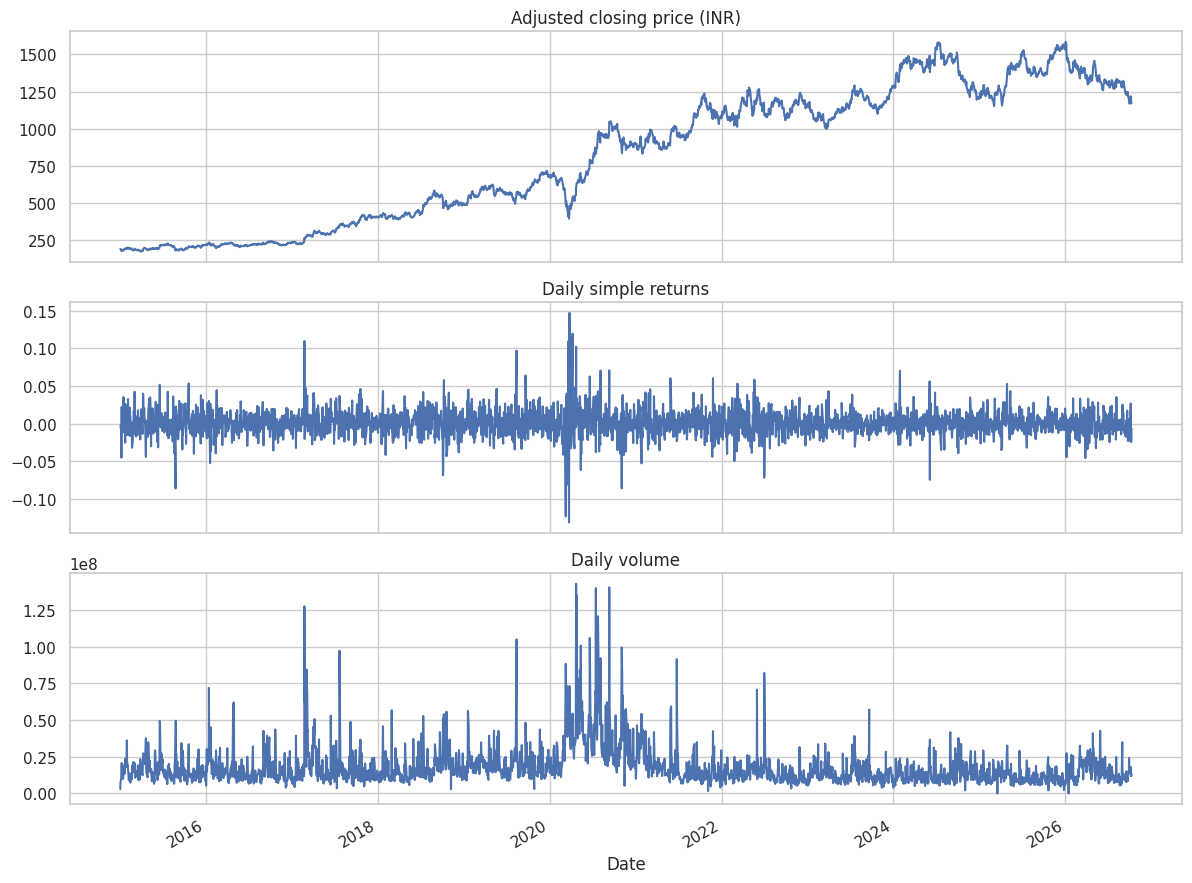

In [3]:
print('Missing values:'); display(raw.isna().sum().to_frame('missing'))
print('Duplicate dates:', raw.index.duplicated().sum())
data = raw.loc[~raw.index.duplicated(keep='last')].copy()
data = data.dropna(subset=['Open','High','Low','Close','Volume'])
valid = (data[['Open','High','Low','Close']] > 0).all(axis=1) & (data.Volume >= 0)
valid &= (data.High >= data[['Open','Close','Low']].max(axis=1)) & (data.Low <= data[['Open','Close','High']].min(axis=1))
data = data.loc[valid]
print('Removed records:', len(raw)-len(data))
print('Clean date range:', data.index.min().date(), 'to', data.index.max().date())
display(data.describe().T)
fig, ax = plt.subplots(3,1,figsize=(12,9),sharex=True)
data.Close.plot(ax=ax[0], title='Adjusted closing price (INR)')
data.Close.pct_change().plot(ax=ax[1],title='Daily simple returns')
data.Volume.plot(ax=ax[2],title='Daily volume')
plt.tight_layout(); plt.show()

## 3. Features and prediction timing
At the close of day t, all inputs use observations dated t or earlier. Target: adjusted Close(t+1). Predictors include current price, lagged returns, moving-average deviations, historical volatility, intraday range, and relative volume. No negative shift is used for features.

Compare a direct price-level regression with a return regression, which is converted back to price as `Close(t) × (1 + predicted return)`. Return modeling helps avoid misleading fit from persistent price levels but does not ensure stationarity or useful predictability. Full and reduced feature sets are specified **before** looking at test results.

Train 1730 2015-01-30 2022-02-02
Validation 576 2022-02-04 2024-06-07
Test 578 2024-06-11 2026-10-08


/usr/local/lib/python3.13/site-packages/pydantic/main.py:475: UserWarning: Pydantic serializer warnings:
  PydanticSerializationUnexpectedValue(Expected `LineChart` - serialized value may not be as expected [field_name='elements', input_value=Chart(type=<ChartType.UNK...relations', elements=[]), input_type=Chart])
  PydanticSerializationUnexpectedValue(Expected `ScatterChart` - serialized value may not be as expected [field_name='elements', input_value=Chart(type=<ChartType.UNK...relations', elements=[]), input_type=Chart])
  PydanticSerializationUnexpectedValue(Expected `BarChart` - serialized value may not be as expected [field_name='elements', input_value=Chart(type=<ChartType.UNK...relations', elements=[]), input_type=Chart])
  PydanticSerializationUnexpectedValue(Expected `PieChart` - serialized value may not be as expected [field_name='elements', input_value=Chart(type=<ChartType.UNK...relations', elements=[]), input_type=Chart])
  PydanticSerializationUnexpectedValue(Expected `B

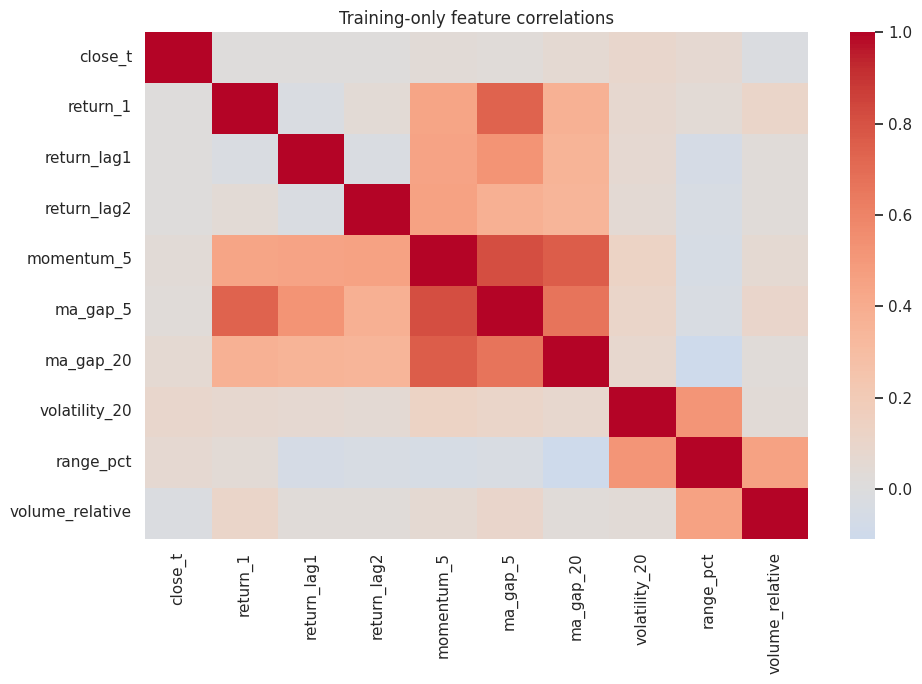

price level ADF p-value: 0.9440175766098291 (null: unit root; not proof of stationarity)
daily returns ADF p-value: 5.2703365459150203e-23 (null: unit root; not proof of stationarity)


In [4]:
frame = pd.DataFrame(index=data.index)
frame['close_t'] = data.Close
r = data.Close.pct_change()
frame['return_1'] = r
frame['return_lag1'] = r.shift(1)
frame['return_lag2'] = r.shift(2)
frame['momentum_5'] = data.Close.pct_change(5)
frame['ma_gap_5'] = data.Close / data.Close.rolling(5).mean() - 1
frame['ma_gap_20'] = data.Close / data.Close.rolling(20).mean() - 1
frame['volatility_20'] = r.rolling(20).std()
frame['range_pct'] = (data.High-data.Low)/data.Close
frame['volume_relative'] = np.log1p(data.Volume)-np.log1p(data.Volume).rolling(20).mean()
frame['target_price'] = data.Close.shift(-1)
frame['target_return'] = data.Close.shift(-1)/data.Close-1
frame['target_date'] = pd.Series(data.index,index=data.index).shift(-1)
feature_rows = frame.dropna(subset=['close_t','return_1','return_lag1','return_lag2','momentum_5','ma_gap_5','ma_gap_20','volatility_20','range_pct','volume_relative'])
model_data = feature_rows.dropna().copy()
full = ['return_1','return_lag1','return_lag2','momentum_5','ma_gap_5','ma_gap_20','volatility_20','range_pct','volume_relative']
reduced = ['return_1','return_lag1','return_lag2','volatility_20','range_pct','volume_relative']
specs = {'OLS price (full)': ('target_price',['close_t']+full),
         'OLS price (reduced)': ('target_price',['close_t']+reduced),
         'OLS return (reduced)': ('target_return',reduced)}
n = len(model_data); a = int(n*.60); b = int(n*.80)
# Purge one observation at each boundary: its target would fall in the next partition.
train = model_data.iloc[:a-1].copy()
validation = model_data.iloc[a:b-1].copy()
test = model_data.iloc[b:].copy()
for name, part in [('Train',train),('Validation',validation),('Test',test)]:
    print(name,len(part),part.index.min().date(),part.index.max().date())
assert train.target_date.max() < validation.index.min()
assert validation.target_date.max() < test.index.min()
fig,ax=plt.subplots(figsize=(10,7))
sns.heatmap(train[['close_t']+full].corr(),cmap='coolwarm',center=0,ax=ax)
ax.set_title('Training-only feature correlations');plt.tight_layout();plt.show()
for label, series in [('price level',train.close_t),('daily returns',train.return_1)]:
    result=adfuller(series,autolag='AIC')
    print(label,'ADF p-value:',result[1], '(null: unit root; not proof of stationarity)')

## 4. Train candidates and select using validation only
Standardization is fitted on training features only and makes the intercept and numerical diagnostics better conditioned. OLS does not need scaling for point prediction. The naive benchmark predicts tomorrow's close equals today's close.

Metrics: MAE and RMSE in adjusted INR, MAPE (%), out-of-sample R², and directional accuracy. A high price R² alone is not evidence of an exploitable forecasting signal.

In [5]:
def fit_model(part, target, features):
    means=part[features].mean(); scales=part[features].std().replace(0,1)
    X=sm.add_constant((part[features]-means)/scales,has_constant='add')
    fitted=sm.OLS(part[target],X).fit()
    return {'model':fitted,'means':means,'scales':scales,'features':features,'target':target}
def design(bundle, part):
    return sm.add_constant((part[bundle['features']]-bundle['means'])/bundle['scales'],has_constant='add')
def price_predict(bundle,part):
    pred=bundle['model'].predict(design(bundle,part))
    return part.close_t*(1+pred) if bundle['target']=='target_return' else pred
def metrics(part,pred):
    y=part.target_price
    return {'MAE_INR':mean_absolute_error(y,pred),'RMSE_INR':np.sqrt(mean_squared_error(y,pred)),
            'MAPE_pct':100*np.mean(np.abs((y-pred)/y)), 'R2':r2_score(y,pred),
            'Direction_accuracy_pct':100*np.mean(np.sign(pred-part.close_t)==np.sign(y-part.close_t))}
bundles={name:fit_model(train,*spec) for name,spec in specs.items()}
validation_table=pd.DataFrame({name:metrics(validation,price_predict(bundle,validation)) for name,bundle in bundles.items()}).T
validation_table.loc['Naive no-change']=metrics(validation,validation.close_t)
display(validation_table)
selected=validation_table.loc[list(specs),'RMSE_INR'].idxmin()
print('Selected OLS candidate:',selected)
print('Naive benchmark is not a regression candidate; whether OLS beats it is reported separately.')
# Expanding-window cross-validation within training only, with one-row boundary purge.
cv_rows=[]
for fold,(tr,va) in enumerate(TimeSeriesSplit(n_splits=5,gap=1).split(train),1):
    trp,vap=train.iloc[tr],train.iloc[va]
    assert trp.target_date.max() < vap.index.min()
    m=fit_model(trp,*specs[selected])
    cv_rows.append({'fold':fold,**metrics(vap,price_predict(m,vap)),
                    'naive_RMSE_INR':metrics(vap,vap.close_t)['RMSE_INR']})
display(pd.DataFrame(cv_rows))

,MAE_INR,RMSE_INR,MAPE_pct,R2,Direction_accuracy_pct
OLS price (full),12.568786,17.619852,1.048202,0.978616,50.000000
OLS price (reduced),12.562874,17.616106,1.047841,0.978625,48.784722
OLS return (reduced),12.614689,17.612319,1.053009,0.978634,47.916667
Naive no-change,12.559650,17.636374,1.047366,0.978576,0.000000


Selected OLS candidate: OLS return (reduced)
Naive benchmark is not a regression candidate; whether OLS beats it is reported separately.


,fold,MAE_INR,RMSE_INR,MAPE_pct,R2,Direction_accuracy_pct,naive_RMSE_INR
0,1,2.450377,3.508317,1.003129,0.986436,55.902778,3.513370
1,2,4.384792,5.707538,1.103026,0.982949,50.694444,5.702013
2,3,7.529383,9.921654,1.388251,0.936552,48.958333,9.924095
3,4,12.655297,18.095962,1.812910,0.987272,47.569444,17.990057
4,5,12.038577,16.136450,1.207516,0.975815,55.208333,15.980362


## 5. Locked holdout evaluation
After validation selection, refit on all eligible pre-test observations. Remove the boundary observation whose target date is the first test feature date. The test is used once for final evaluation, not to choose features or change models. Compare forecasts on the same dates.

,MAE_INR,RMSE_INR,MAPE_pct,R2,Direction_accuracy_pct,RMSE_skill_vs_naive
Selected OLS,13.418165,17.884875,0.988096,0.969305,49.134948,-0.006201
Naive no-change,13.357826,17.774656,0.982698,0.969682,0.519031,0.000000


,target_date,close_t,actual,OLS_prediction,naive_prediction
Date,,,,,
2026-09-24,2026-09-25,1219.199951,1226.000000,1221.019023,1219.199951
2026-09-25,2026-09-28,1226.000000,1197.599976,1226.088947,1226.000000
2026-09-28,2026-09-29,1197.599976,1182.000000,1199.702551,1197.599976
2026-09-29,2026-09-30,1182.000000,1187.000000,1183.410840,1182.000000
2026-09-30,2026-10-01,1187.000000,1167.699951,1187.943344,1187.000000
2026-10-01,2026-10-05,1167.699951,1186.400024,1169.117950,1167.699951
2026-10-05,2026-10-06,1186.400024,1218.000000,1186.138156,1186.400024
2026-10-06,2026-10-07,1218.000000,1207.699951,1218.661205,1218.000000
2026-10-07,2026-10-08,1207.699951,1178.000000,1209.825975,1207.699951


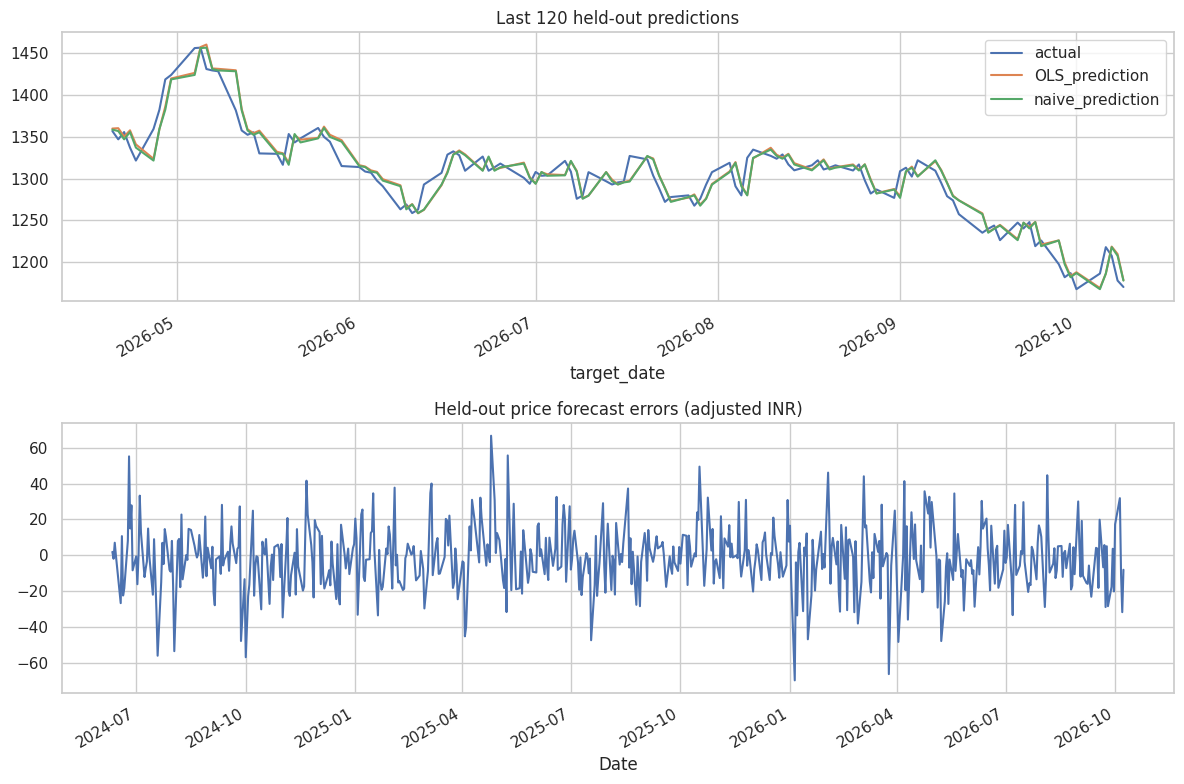

In [6]:
development=model_data.loc[model_data.target_date < test.index.min()].copy()
final=fit_model(development,*specs[selected])
pred=price_predict(final,test)
results=pd.DataFrame({'Selected OLS':metrics(test,pred),'Naive no-change':metrics(test,test.close_t)}).T
results['RMSE_skill_vs_naive']=1-results.RMSE_INR/results.loc['Naive no-change','RMSE_INR']
display(results)
predictions=pd.DataFrame({'target_date':test.target_date,'close_t':test.close_t,'actual':test.target_price,
                          'OLS_prediction':pred,'naive_prediction':test.close_t})
display(predictions.tail(10))
fig,ax=plt.subplots(2,1,figsize=(12,8))
predictions.set_index('target_date')[['actual','OLS_prediction','naive_prediction']].tail(120).plot(ax=ax[0],title='Last 120 held-out predictions')
(test.target_price-pred).plot(ax=ax[1],title='Held-out price forecast errors (adjusted INR)')
plt.tight_layout();plt.show()

## 6. Statistical assumption diagnostics
Run formal specification diagnostics on the selected **training fit**, so test data do not influence model specification. Also inspect held-out errors for generalization problems. Null hypotheses: constant variance (Breusch–Pagan), normal errors (Jarque–Bera), no residual serial correlation (Ljung–Box/Breusch–Godfrey), and no omitted nonlinear fitted-value terms (RESET). VIF is a descriptive collinearity measure; values above 5 warrant investigation, not an automatic deletion rule. Durbin–Watson near 2 is descriptive, not a stand-alone verdict.

Use α=0.05. Failure to reject does not prove an assumption. Large samples can detect minor deviations; tests are dependent and multiple testing is not adjusted. RESET is a general specification check, not a definitive test of every form of nonlinearity. Jarque–Bera asymptotics and regression tests can themselves be affected by dependent/heteroskedastic errors.

,feature,VIF
1,return_1,1.024368
2,return_lag1,1.029744
3,return_lag2,1.017664
4,volatility_20,1.527059
5,range_pct,1.931833
6,volume_relative,1.412711


,Assumption,Test,p_value,Decision
0,Homoskedasticity,Breusch–Pagan (Koenker default),7.358022e-47,Reject null / concern detected
1,Residual normality,Jarque–Bera,0.000000e+00,Reject null / concern detected
2,No autocorrelation,Ljung–Box lag 10,5.441303e-03,Reject null / concern detected
3,No autocorrelation,Breusch–Godfrey lag 10,7.290678e-03,Reject null / concern detected
4,Specification / linearity,"RESET squared fitted, HC3",6.491374e-01,Do not reject null (not proof)


,lb_stat,lb_pvalue
5,2.740629,0.739898
10,24.949889,0.005441
20,44.772258,0.001185


Durbin–Watson: 1.9995172237671872
Scaled design condition number: 2.39873608465226


/usr/local/lib/python3.13/site-packages/pydantic/main.py:475: UserWarning: Pydantic serializer warnings:
  PydanticSerializationUnexpectedValue(Expected `LineChart` - serialized value may not be as expected [field_name='elements', input_value=Chart(type=<ChartType.UNK...ng spread', elements=[]), input_type=Chart])
  PydanticSerializationUnexpectedValue(Expected `ScatterChart` - serialized value may not be as expected [field_name='elements', input_value=Chart(type=<ChartType.UNK...ng spread', elements=[]), input_type=Chart])
  PydanticSerializationUnexpectedValue(Expected `BarChart` - serialized value may not be as expected [field_name='elements', input_value=Chart(type=<ChartType.UNK...ng spread', elements=[]), input_type=Chart])
  PydanticSerializationUnexpectedValue(Expected `PieChart` - serialized value may not be as expected [field_name='elements', input_value=Chart(type=<ChartType.UNK...ng spread', elements=[]), input_type=Chart])
  PydanticSerializationUnexpectedValue(Expected `B

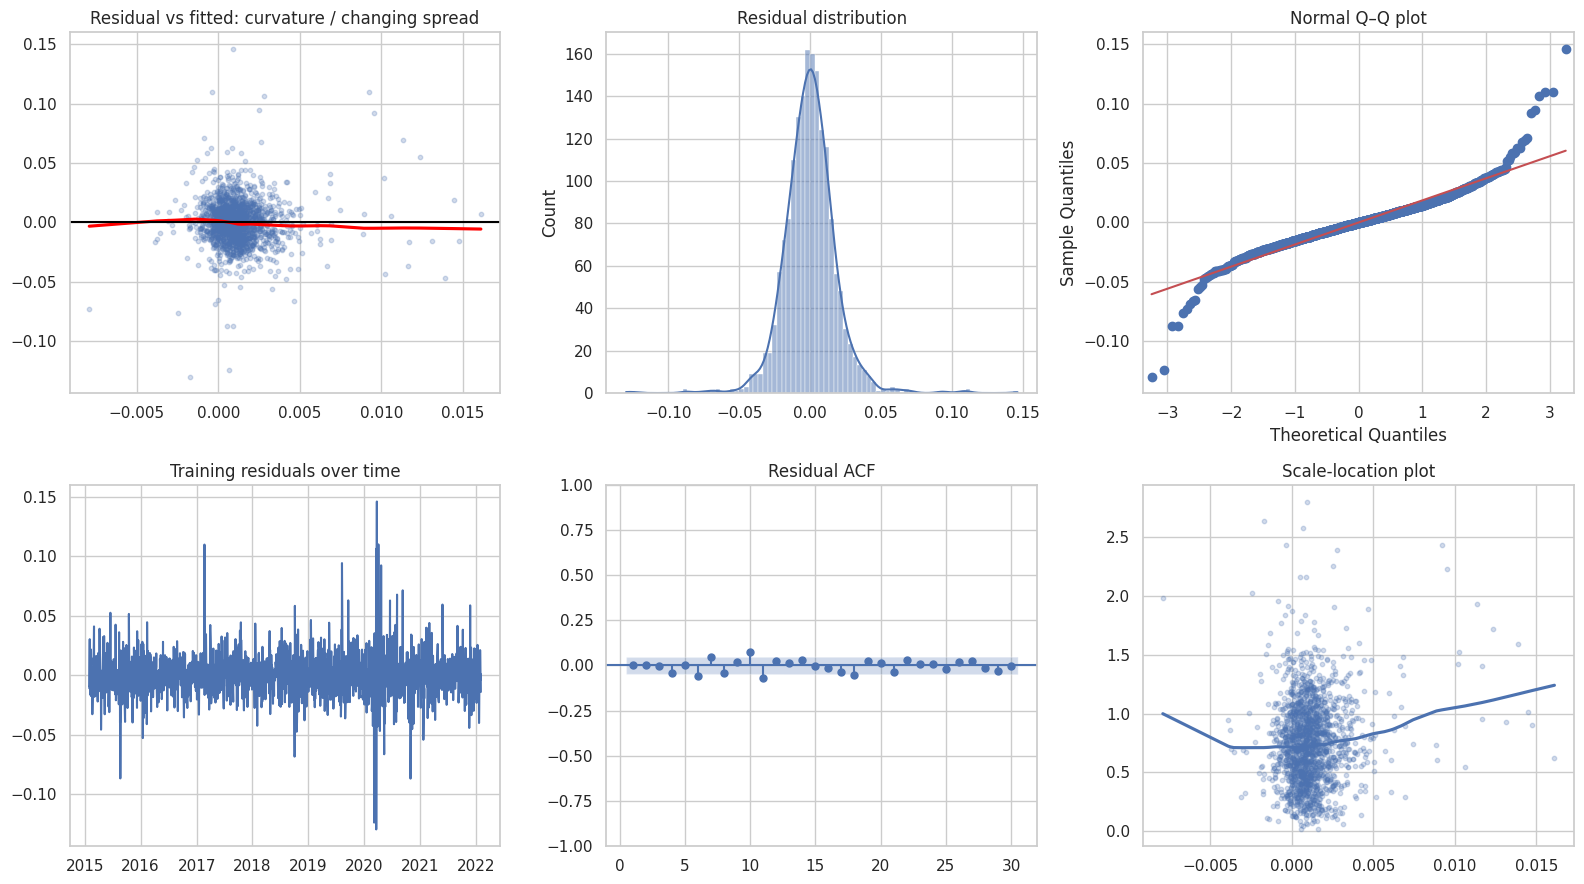

Held-out price error Ljung–Box (descriptive; no retuning):


,lb_stat,lb_pvalue
10,8.084445,0.620589
20,15.995601,0.716897


In [7]:
diagnostic_fit=bundles[selected]['model']
X=diagnostic_fit.model.exog
resid=diagnostic_fit.resid
vif=pd.DataFrame({'feature':['Intercept']+bundles[selected]['features'],
                  'VIF':[variance_inflation_factor(X,i) for i in range(X.shape[1])]})
display(vif.iloc[1:])
bp=het_breuschpagan(resid,X)
jb=jarque_bera(resid)
lb=acorr_ljungbox(resid,lags=[5,10,20],return_df=True)
bg=acorr_breusch_godfrey(diagnostic_fit,nlags=10)
reset=linear_reset(diagnostic_fit,power=2,test_type='fitted',use_f=True,cov_type='HC3')
diag=pd.DataFrame([
    ['Homoskedasticity','Breusch–Pagan (Koenker default)',bp[1]],
    ['Residual normality','Jarque–Bera',jb[1]],
    ['No autocorrelation','Ljung–Box lag 10',lb.loc[10,'lb_pvalue']],
    ['No autocorrelation','Breusch–Godfrey lag 10',bg[1]],
    ['Specification / linearity','RESET squared fitted, HC3',float(reset.pvalue)]
],columns=['Assumption','Test','p_value'])
diag['Decision']=np.where(diag.p_value<ALPHA,'Reject null / concern detected','Do not reject null (not proof)')
display(diag,lb)
print('Durbin–Watson:',durbin_watson(resid))
print('Scaled design condition number:',diagnostic_fit.condition_number)
fig,ax=plt.subplots(2,3,figsize=(16,9))
sns.regplot(x=diagnostic_fit.fittedvalues,y=resid,lowess=True,scatter_kws={'alpha':.25,'s':10},line_kws={'color':'red'},ax=ax[0,0])
ax[0,0].axhline(0,color='black');ax[0,0].set_title('Residual vs fitted: curvature / changing spread')
sns.histplot(resid,kde=True,ax=ax[0,1]);ax[0,1].set_title('Residual distribution')
sm.qqplot(resid,line='s',ax=ax[0,2]);ax[0,2].set_title('Normal Q–Q plot')
ax[1,0].plot(resid.index,resid);ax[1,0].set_title('Training residuals over time')
plot_acf(resid,lags=30,zero=False,ax=ax[1,1]);ax[1,1].set_title('Residual ACF')
standardized=resid/np.sqrt(diagnostic_fit.mse_resid)
sns.regplot(x=diagnostic_fit.fittedvalues,y=np.sqrt(np.abs(standardized)),lowess=True,scatter_kws={'alpha':.25,'s':10},ax=ax[1,2])
ax[1,2].set_title('Scale-location plot')
plt.tight_layout();plt.show()
print('Held-out price error Ljung–Box (descriptive; no retuning):')
display(acorr_ljungbox(test.target_price-pred,lags=[10,20],return_df=True))

## 7. Robust coefficient inference—not a repair of predictability
Compare conventional OLS standard errors with Newey–West HAC standard errors (maximum lag 5, specified in advance). HAC changes inference, not fitted coefficients or predictions; it does not cure nonlinearity, nonstationarity, omitted variables, multicollinearity, or poor forecasts. Conditional exogeneity cannot be established by these residual diagnostics. Normality is not necessary for computing OLS coefficients; it matters for exact classical small-sample inference.

Conventional prediction intervals are intentionally omitted: if variance/dependence assumptions fail, nominal coverage is not trustworthy. Honest intervals would require a separately designed time-series calibration procedure and evaluation.

In [8]:
hac=diagnostic_fit.get_robustcov_results(cov_type='HAC',maxlags=5)
coef=pd.DataFrame({'coefficient':diagnostic_fit.params,'OLS_SE':diagnostic_fit.bse,
                   'HAC_SE':hac.bse,'OLS_p':diagnostic_fit.pvalues,'HAC_p':hac.pvalues},index=diagnostic_fit.params.index)
display(coef)
# Latest eligible feature row may have no next-day target; avoid pretending its future outcome is known.
latest=feature_rows.iloc[[-1]]
next_price=float(price_predict(final,latest).iloc[0])
print('Illustrative next-observed-session forecast from feature date:',latest.index[0].date())
print('Adjusted close:',float(latest.close_t.iloc[0]))
print('OLS predicted adjusted close:',next_price)
print('This uses a model fitted only on pre-test data; not a live production forecast or a trade recommendation.')

,coefficient,OLS_SE,HAC_SE,OLS_p,HAC_p
const,0.001156,0.000448,0.000442,0.009952,0.008956
return_1,-0.000514,0.000454,0.000793,0.257333,0.517220
return_lag1,0.000587,0.000455,0.000803,0.196980,0.464807
return_lag2,0.000042,0.000452,0.000671,0.925183,0.949573
volatility_20,0.001715,0.000554,0.000794,0.001990,0.030944
range_pct,-0.000920,0.000623,0.000945,0.139770,0.330369
volume_relative,0.000164,0.000533,0.000542,0.757854,0.761779


Illustrative next-observed-session forecast from feature date: 2026-10-09
Adjusted close: 1170.300048828125
OLS predicted adjusted close: 1171.082849379099
This uses a model fitted only on pre-test data; not a live production forecast or a trade recommendation.


## 8. Results-driven conclusions and limitations
The following conclusion is generated from actual holdout and diagnostic results. Do not claim that a model is valid merely because it has high R².

**Limitations:** one stock, third-party data revisions, retrospectively adjusted prices rather than point-in-time corporate-action data, potential selection bias from the chosen ticker, market regime changes, omitted macro/fundamental information, and no transaction costs or trading implementation. Historical adjusted prices are not directly executable. The final target is tomorrow's price, not same-day fitting. No causal interpretation is warranted.

**If assumptions fail:** reduce redundant inputs using training-only analysis; consider return/log-return targets and alternative prespecified features; use HAC for qualified inference; assess volatility models for changing variance; and test nonlinear alternatives through a new validation experiment—not repeated tuning on this test set. Strong benchmark performance should be treated as evidence against the current OLS trading signal, not as a reason to hide the benchmark.

**Potential extensions:** multiple stocks, rolling-window training, external holdout periods, point-in-time source verification, transaction-cost-aware backtesting, and time-series interval calibration. These are proposals, not results established by this notebook.

In [9]:
skill=float(results.loc['Selected OLS','RMSE_skill_vs_naive'])
concerns=diag.loc[diag.p_value<ALPHA,'Assumption'].unique().tolist()
max_vif=float(vif.iloc[1:].VIF.max())
text=f"""### Computed project conclusion
- Selected candidate: **{selected}**.
- Holdout OLS RMSE: **{results.loc['Selected OLS','RMSE_INR']:.3f} adjusted INR**.
- Holdout no-change RMSE: **{results.loc['Naive no-change','RMSE_INR']:.3f} adjusted INR**.
- RMSE skill against no-change: **{skill:.2%}** (positive is better).
- Assessment: **{'OLS beat the benchmark on this holdout, but robustness and economic value remain unestablished.' if skill > 0 else 'OLS did not beat the benchmark on this holdout; high price R² should not be interpreted as predictive advantage.'}**
- Diagnostic concerns at α=0.05: **{', '.join(concerns) if concerns else 'No rejections in the selected tests; this does not prove validity'}**.
- Maximum feature VIF: **{max_vif:.2f}**.
- Regression is a transparent baseline; neither assumption satisfaction nor investment usefulness is guaranteed.
"""
display(Markdown(text))

### Computed project conclusion
- Selected candidate: **OLS return (reduced)**.
- Holdout OLS RMSE: **17.885 adjusted INR**.
- Holdout no-change RMSE: **17.775 adjusted INR**.
- RMSE skill against no-change: **-0.62%** (positive is better).
- Assessment: **OLS did not beat the benchmark on this holdout; high price R² should not be interpreted as predictive advantage.**
- Diagnostic concerns at α=0.05: **Homoskedasticity, Residual normality, No autocorrelation**.
- Maximum feature VIF: **1.93**.
- Regression is a transparent baseline; neither assumption satisfaction nor investment usefulness is guaranteed.
